# Loading the Train and Test data


In [2]:
train= pd.read_csv("/kaggle/input/System-Threat-Forecaster/train.csv")
test = pd.read_csv("/kaggle/input/System-Threat-Forecaster/test.csv")
data= train.copy()
test_data=test.copy()

###  Shape and Data Samples

In [3]:
print(data.shape)
print(test.shape)
data.head(10)

(100000, 76)
(10000, 75)


,MachineID,ProductName,EngineVersion,AppVersion,SignatureVersion,IsBetaUser,RealTimeProtectionState,IsPassiveModeEnabled,AntivirusConfigID,NumAntivirusProductsInstalled,...,IsSecureBootEnabled,IsVirtualDevice,IsTouchEnabled,IsPenCapable,IsAlwaysOnAlwaysConnectedCapable,IsGamer,RegionIdentifier,DateAS,DateOS,target
0,f541bae429089117c4aac39c90dd3416,win8defender,1.1.15200.1,4.18.1807.18075,1.275.1003.0,0,7.0,0,53447.0,1.0,...,0,0.0,1,0,1.0,0.0,6.0,2018-09-10 10:11:00,2018-04-17,0
1,dc2b14d9ce3a0ce4050bb640190f2ca5,win8defender,1.1.15100.1,4.18.1807.18075,1.273.1465.0,0,7.0,0,53447.0,1.0,...,1,0.0,0,0,0.0,0.0,10.0,2018-08-16 00:01:00,2018-08-14,1
2,fd20c5f010e9c5f91ad1c6b3e0da68a0,win8defender,1.1.15200.1,4.18.1807.18075,1.275.1546.0,0,7.0,0,53447.0,1.0,...,0,0.0,0,0,0.0,1.0,6.0,2018-09-20 23:20:00,2018-09-11,1
3,38711eae85eb77a72ec5dfdf27eb2a76,win8defender,1.1.15200.1,4.12.17007.18011,1.275.1141.0,0,7.0,0,46413.0,2.0,...,1,0.0,0,0,0.0,0.0,12.0,2018-09-14 00:32:00,2018-01-03,1
4,32607c9a543a9214e2c7e45800ed4849,win8defender,1.1.15200.1,4.13.17134.228,1.275.1283.0,0,7.0,0,40466.0,2.0,...,0,0.0,0,0,0.0,1.0,7.0,2018-09-15 19:34:00,2018-09-11,0
5,22f549ef938e3a943854d49c853ba918,win8defender,1.1.15200.1,4.18.1807.18075,1.275.1338.0,0,7.0,0,53447.0,1.0,...,0,0.0,0,0,0.0,1.0,4.0,2018-09-17 02:29:00,2018-09-11,0
6,d197d1b86b9071b50a655bb3b31cc828,win8defender,1.1.15200.1,4.18.1807.18075,1.275.182.0,0,7.0,0,53447.0,1.0,...,0,0.0,0,0,0.0,0.0,11.0,2018-08-26 09:33:00,2018-08-14,0
7,8e3a7d3fe18b946443f0777060f82ab7,win8defender,1.1.15100.1,4.18.1807.18075,1.273.738.0,0,7.0,0,53447.0,1.0,...,0,0.0,0,0,0.0,0.0,1.0,2018-08-02 16:51:00,2018-07-16,1
8,bdb0b0d016466c16b3c58ce39da702e1,win8defender,1.1.15100.1,4.18.1807.18075,1.273.1498.0,0,7.0,0,53447.0,1.0,...,0,0.0,0,0,0.0,0.0,1.0,2018-08-16 11:38:00,2018-07-10,0
9,44f4b3df4c9ecc13c4a8f3b61f7a18c8,win8defender,1.1.15200.1,4.18.1807.18075,1.275.36.0,0,7.0,0,53447.0,1.0,...,1,0.0,0,0,0.0,1.0,1.0,2018-08-23 12:13:00,2018-07-16,1


**MachineID can be removed, not significant** 

In [4]:
data=data.drop(columns=["MachineID"],axis=1)

# Exploratory Data Analysis

# **Data Statistics**

In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 75 columns):
 #   Column                              Non-Null Count   Dtype  
---  ------                              --------------   -----  
 0   ProductName                         100000 non-null  object 
 1   EngineVersion                       100000 non-null  object 
 2   AppVersion                          100000 non-null  object 
 3   SignatureVersion                    100000 non-null  object 
 4   IsBetaUser                          100000 non-null  int64  
 5   RealTimeProtectionState             99934 non-null   float64
 6   IsPassiveModeEnabled                100000 non-null  int64  
 7   AntivirusConfigID                   99924 non-null   float64
 8   NumAntivirusProductsInstalled       99924 non-null   float64
 9   NumAntivirusProductsEnabled         99924 non-null   float64
 10  HasTpm                              100000 non-null  int64  
 11  CountryID                  

### It seems many features has missing values in it

In [6]:
data.describe()

,IsBetaUser,RealTimeProtectionState,IsPassiveModeEnabled,AntivirusConfigID,NumAntivirusProductsInstalled,NumAntivirusProductsEnabled,HasTpm,CountryID,CityID,GeoRegionID,...,FirmwareManufacturerID,FirmwareVersionID,IsSecureBootEnabled,IsVirtualDevice,IsTouchEnabled,IsPenCapable,IsAlwaysOnAlwaysConnectedCapable,IsGamer,RegionIdentifier,target
count,100000.0,99934.000000,100000.000000,99924.000000,99924.000000,99924.000000,100000.000000,100000.000000,99377.000000,100000.000000,...,99624.000000,99666.000000,100000.000000,99980.000000,100000.000000,100000.000000,99866.000000,99441.000000,99441.000000,100000.000000
mean,0.0,6.848430,0.017620,47975.710440,1.326528,1.018264,0.996780,108.078790,81029.938587,169.741630,...,401.987613,32942.648044,0.495690,0.003841,0.128470,0.040580,0.058398,0.296668,7.875866,0.505250
std,0.0,1.015166,0.131566,13803.321533,0.520681,0.155291,0.056654,63.062151,48944.027074,89.188929,...,221.318891,21151.970827,0.499984,0.061855,0.334614,0.197316,0.234496,0.456791,4.562533,0.499975
min,0.0,0.000000,0.000000,39.000000,1.000000,0.000000,0.000000,1.000000,7.000000,1.000000,...,2.000000,121.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000
25%,0.0,7.000000,0.000000,49480.000000,1.000000,1.000000,1.000000,51.000000,36694.000000,89.000000,...,142.000000,13020.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000,0.000000
50%,0.0,7.000000,0.000000,53447.000000,1.000000,1.000000,1.000000,97.000000,82373.000000,181.000000,...,500.000000,33066.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,10.000000,1.000000
75%,0.0,7.000000,0.000000,53447.000000,2.000000,1.000000,1.000000,162.000000,122835.000000,267.000000,...,556.000000,52357.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,11.000000,1.000000
max,0.0,8.000000,1.000000,70490.000000,5.000000,4.000000,1.000000,222.000000,167957.000000,296.000000,...,1083.000000,72091.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,15.000000,1.000000


In [7]:
data.describe(include=["object"])

,ProductName,EngineVersion,AppVersion,SignatureVersion,PlatformType,Processor,OSVersion,OsPlatformSubRelease,OSBuildLab,SKUEditionName,...,OSBranch,OSEdition,OSSkuFriendlyName,OSInstallType,AutoUpdateOptionsName,OSGenuineState,LicenseActivationChannel,FlightRing,DateAS,DateOS
count,100000,100000,100000,100000,100000,100000,100000,100000,100000,100000,...,100000,100000,100000,100000,100000,100000,100000,100000,100000,99976
unique,2,37,69,2735,4,3,7,9,281,8,...,13,20,18,9,6,4,6,7,2695,112
top,win8defender,1.1.15200.1,4.18.1807.18075,1.273.1420.0,windows10,x64,10.0.0.0,rs4,17134.1.amd64fre.rs4_release.180410-1804,Home,...,rs4_release,Core,CORE,UUPUpgrade,FullAuto,IS_GENUINE,Retail,Retail,2018-08-15 06:29:00,2018-08-14
freq,99771,45219,62119,1274,98344,91262,98368,45837,42964,62863,...,46909,39275,39273,32033,45154,89860,52195,94153,1274,20905


# Exploring null values

In [8]:
print("NaN missing values:",data.isnull().sum().sum())
print("Empty missing values:",(data == ' ').sum().sum())
print("Other missing values:",(data.isin(['NA', 'N/A', '-',"?"])).sum().sum())
print("UNKNOWN missing values:",(data == 'UNKNOWN').sum().sum())
print("Unknown missing values:",(data == 'Unknown').sum().sum())

NaN missing values: 6533
Empty missing values: 0
Other missing values: 0
UNKNOWN missing values: 30079
Unknown missing values: 2548


### Which all features has null values and how much??


In [9]:
null_information=data.isnull().sum()
null_data=null_information.iloc[lambda x:x.values != 0]
null_df= pd.DataFrame(null_data)
null_df.columns=["Null_values"]
null_df=null_df.sort_values(by="Null_values")
print(null_df.shape)
print(null_df)

(33, 1)
                                    Null_values
ChassisType                                   2
EnableLUA                                    19
IsVirtualDevice                              20
PrimaryDiskType                              23
DateOS                                       24
RealTimeProtectionState                      66
PrimaryDisplayResolutionVertical             72
PrimaryDisplayResolutionHorizontal           72
PrimaryDisplayDiagonalInches                 72
AntivirusConfigID                            76
NumAntivirusProductsInstalled                76
IsSystemProtected                            76
NumAntivirusProductsEnabled                  76
ProcessorCoreCount                           85
ProcessorManufacturerID                      85
ProcessorModelID                             85
IEVersionID                                 107
SystemVolumeCapacityMB                      110
PrimaryDiskCapacityMB                       110
OSInstallLanguageID             

#### 33 features has null values in it

# Exploring Unique Values


                             Unique Values
IsBetaUser                               1
IsFlightsDisabled                        1
AutoSampleSubmissionEnabled              1
ProductName                              2
IsGamer                                  2
...                                    ...
SignatureVersion                      2735
FirmwareVersionID                    12299
OEMModelID                           15952
CityID                               16047
SystemVolumeCapacityMB               46188

[75 rows x 1 columns]


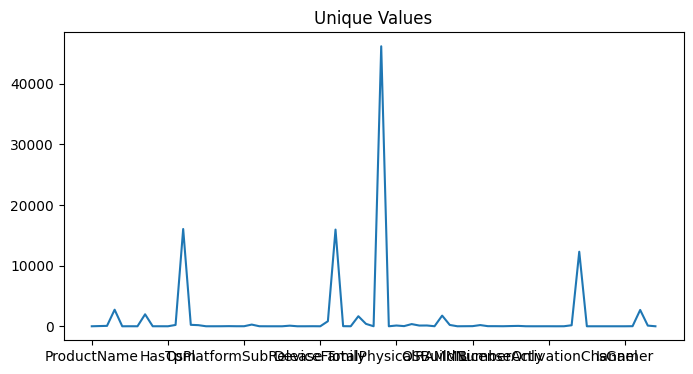

In [10]:
unique_data=data.nunique()
unique_df=pd.DataFrame(unique_data)
unique_df.columns=['Unique Values']
unique_df['Unique Values'].plot(kind='line', figsize=(8, 4), title='Unique Values')
unique_df=unique_df.sort_values(by="Unique Values")
print(unique_df)

### Some features has only one unique value that is zero which can be removed

 # Let's analyze categorical and numerical features invidually

## Exploring Categorical features 


In [11]:
cat_features= data.select_dtypes(include=["object"]).copy()
print("Number of Categorical Features:",cat_features.shape[1])
cat_features.info()

Number of Categorical Features: 27
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 27 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   ProductName               100000 non-null  object
 1   EngineVersion             100000 non-null  object
 2   AppVersion                100000 non-null  object
 3   SignatureVersion          100000 non-null  object
 4   PlatformType              100000 non-null  object
 5   Processor                 100000 non-null  object
 6   OSVersion                 100000 non-null  object
 7   OsPlatformSubRelease      100000 non-null  object
 8   OSBuildLab                100000 non-null  object
 9   SKUEditionName            100000 non-null  object
 10  MDC2FormFactor            100000 non-null  object
 11  DeviceFamily              100000 non-null  object
 12  PrimaryDiskType           99977 non-null   object
 13  ChassisType              

### Only 3 of the categorical features has missing values in it

# What I want from each Categorical Variable? 
*    Unique values,
*    Number of unique values
*    Count including NaN
*    Count excluding NaN
*    Number of missing values
*    Percentage to missing values.
Create a Dataframe to analyze

In [12]:
cat_stats = pd.DataFrame([
    {
        'Name': c,
        'values': cat_features[c].unique(),
        'values_count_in': cat_features[c].nunique(dropna=False), 
        'values_count_ex': cat_features[c].nunique(), 
        'miss_values': cat_features[c].isna().sum(),  
        '%_miss': round(cat_features[c].isna().mean() * 100, 3),
        "UNKNOWN_values": cat_features[c][cat_features[c] == "UNKNOWN"].count(),
        "Unknown_values": cat_features[c][cat_features[c] == "Unknown"].count()      

    }
    for c in cat_features.columns
])
cat_stats = cat_stats.sort_values(by='values_count_in')
cat_stats

,Name,values,values_count_in,values_count_ex,miss_values,%_miss,UNKNOWN_values,Unknown_values
0,ProductName,"[win8defender, mse]",2,2,0,0.000,0,0
11,DeviceFamily,"[Windows.Desktop, Windows.Server]",2,2,0,0.000,0,0
5,Processor,"[x86, x64, arm64]",3,3,0,0.000,0,0
16,OSArchitecture,"[x86, amd64, arm64]",3,3,0,0.000,0,0
22,OSGenuineState,"[IS_GENUINE, INVALID_LICENSE, OFFLINE, UNKNOWN]",4,4,0,0.000,115,0
4,PlatformType,"[windows10, windows8, windows7, windows2016]",4,4,0,0.000,0,0
12,PrimaryDiskType,"[SSD, HDD, Unspecified, UNKNOWN, nan]",5,4,23,0.023,3105,0
23,LicenseActivationChannel,"[Retail, OEM:DM, OEM:NONSLP, Volume:GVLK, Volu...",6,6,0,0.000,0,0
21,AutoUpdateOptionsName,"[UNKNOWN, FullAuto, AutoInstallAndRebootAtMain...",6,6,0,0.000,26299,0
24,FlightRing,"[Retail, NOT_SET, Unknown, WIS, RP, Disabled, ...",7,7,0,0.000,0,2489


### Which all categorical features has missing values in it?

In [13]:
cat_stats.sort_values(by = '%_miss', ascending = False).head()

,Name,values,values_count_in,values_count_ex,miss_values,%_miss,UNKNOWN_values,Unknown_values
26,DateOS,"[2018-04-17, 2018-08-14, 2018-09-11, 2018-01-0...",113,112,24,0.024,0,0
12,PrimaryDiskType,"[SSD, HDD, Unspecified, UNKNOWN, nan]",5,4,23,0.023,3105,0
13,ChassisType,"[Notebook, AllinOne, Desktop, Tower, Laptop, P...",29,28,2,0.002,454,59
0,ProductName,"[win8defender, mse]",2,2,0,0.000,0,0
7,OsPlatformSubRelease,"[rs1, rs4, rs2, rs3, th2, windows8.1, th1, pre...",9,9,0,0.000,0,0


### Which all categorical features has unknown values in it?

In [14]:
cat_stats.sort_values(by=["UNKNOWN_values", "Unknown_values"], ascending=False).head(7)


,Name,values,values_count_in,values_count_ex,miss_values,%_miss,UNKNOWN_values,Unknown_values
21,AutoUpdateOptionsName,"[UNKNOWN, FullAuto, AutoInstallAndRebootAtMain...",6,6,0,0.000,26299,0
12,PrimaryDiskType,"[SSD, HDD, Unspecified, UNKNOWN, nan]",5,4,23,0.023,3105,0
13,ChassisType,"[Notebook, AllinOne, Desktop, Tower, Laptop, P...",29,28,2,0.002,454,59
22,OSGenuineState,"[IS_GENUINE, INVALID_LICENSE, OFFLINE, UNKNOWN]",4,4,0,0.000,115,0
14,PowerPlatformRole,"[Slate, Desktop, Mobile, SOHOServer, UNKNOWN, ...",9,9,0,0.000,106,0
24,FlightRing,"[Retail, NOT_SET, Unknown, WIS, RP, Disabled, ...",7,7,0,0.000,0,2489
0,ProductName,"[win8defender, mse]",2,2,0,0.000,0,0


# Visualization for categorical Features

col


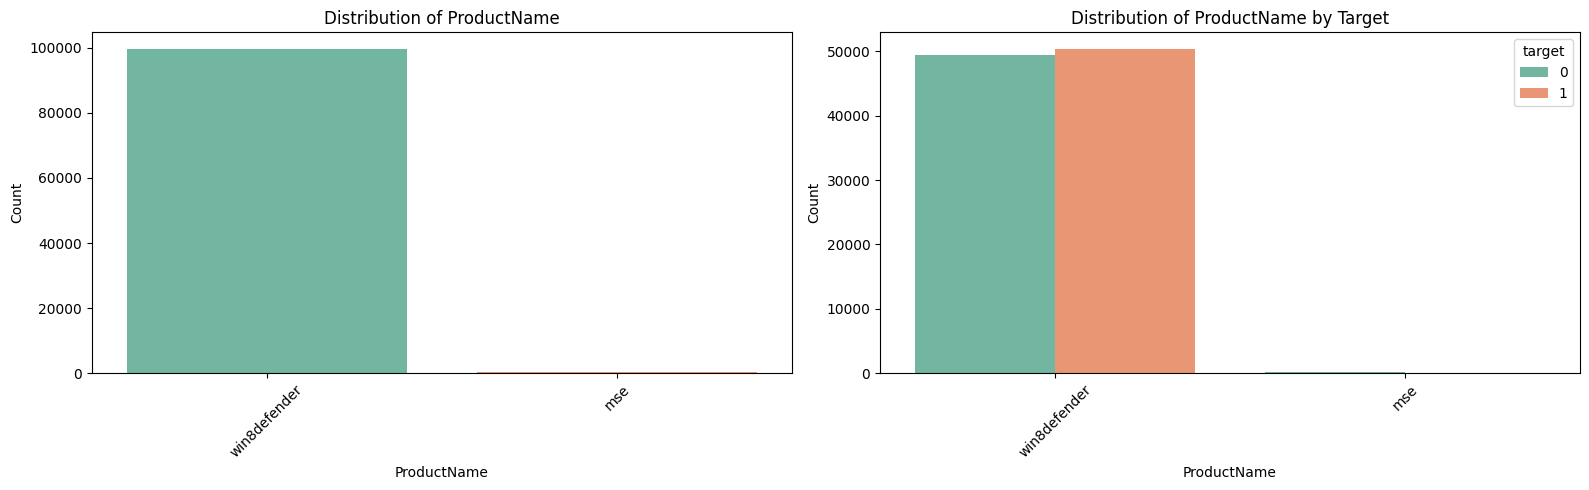

col


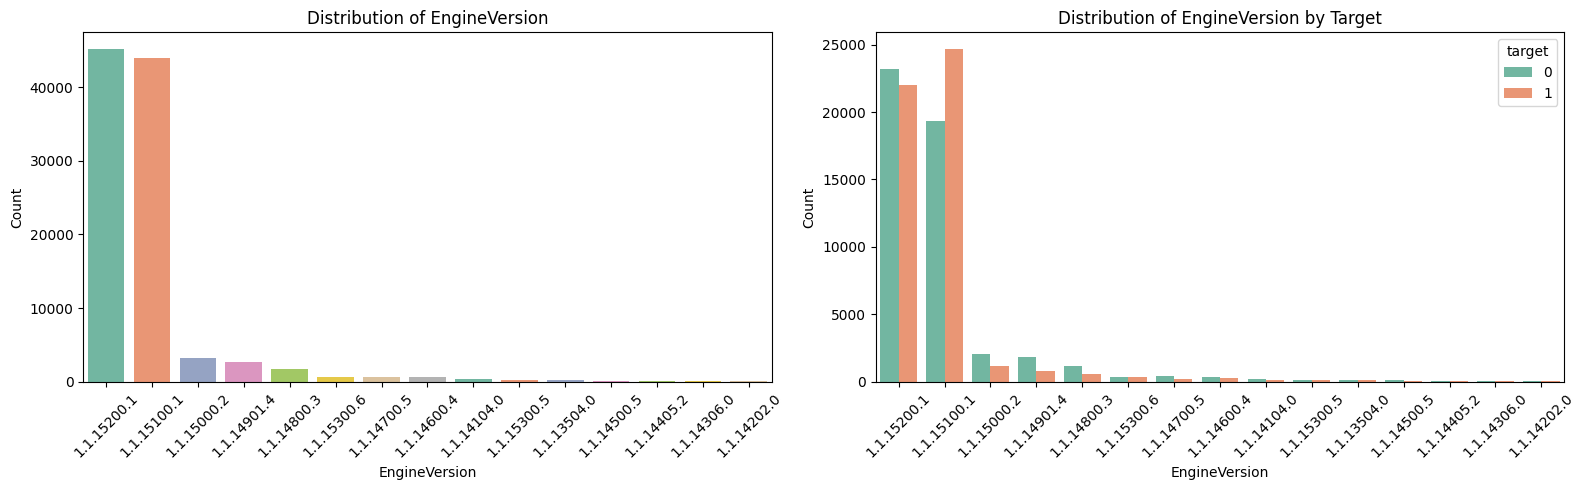

col


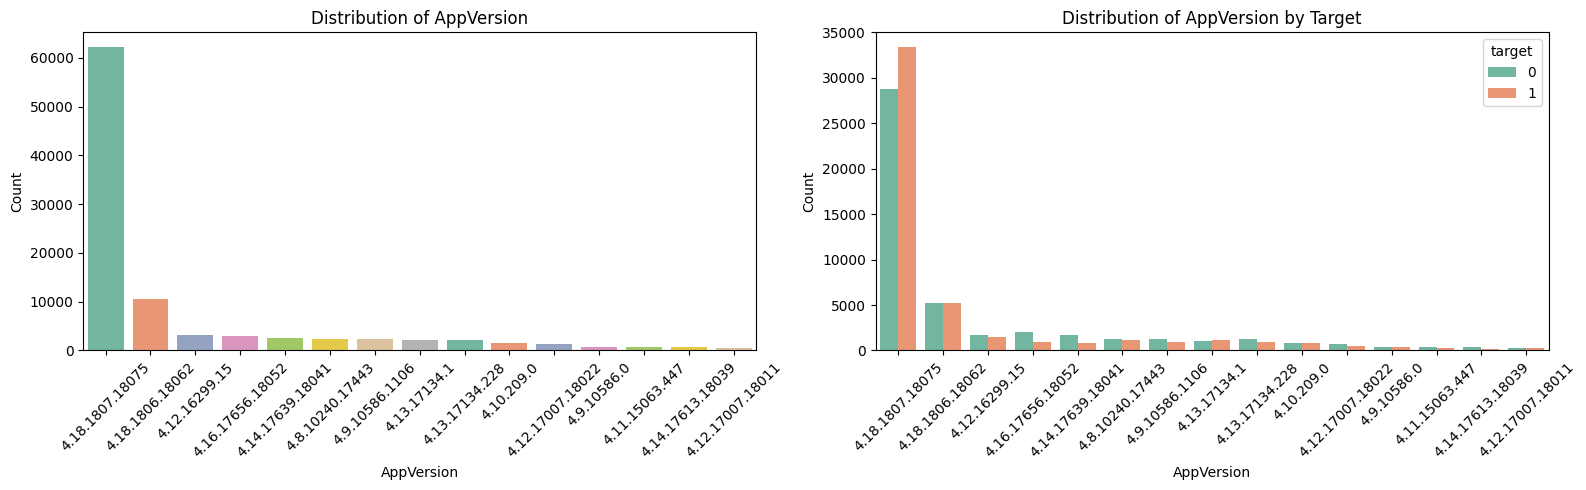

col


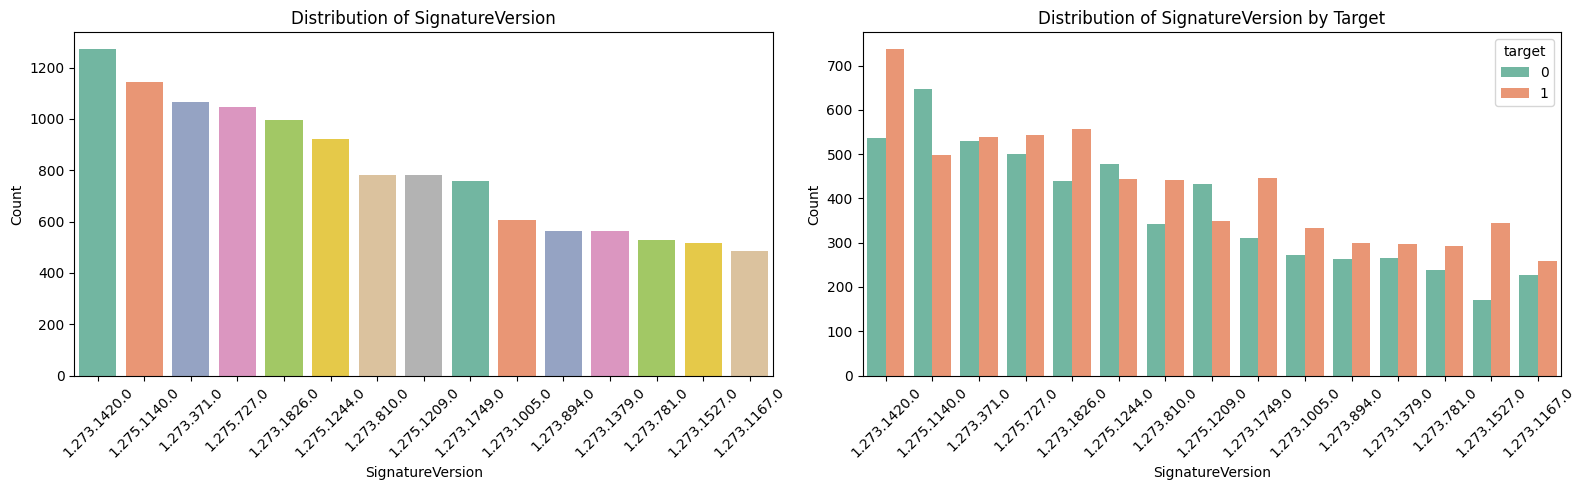

col


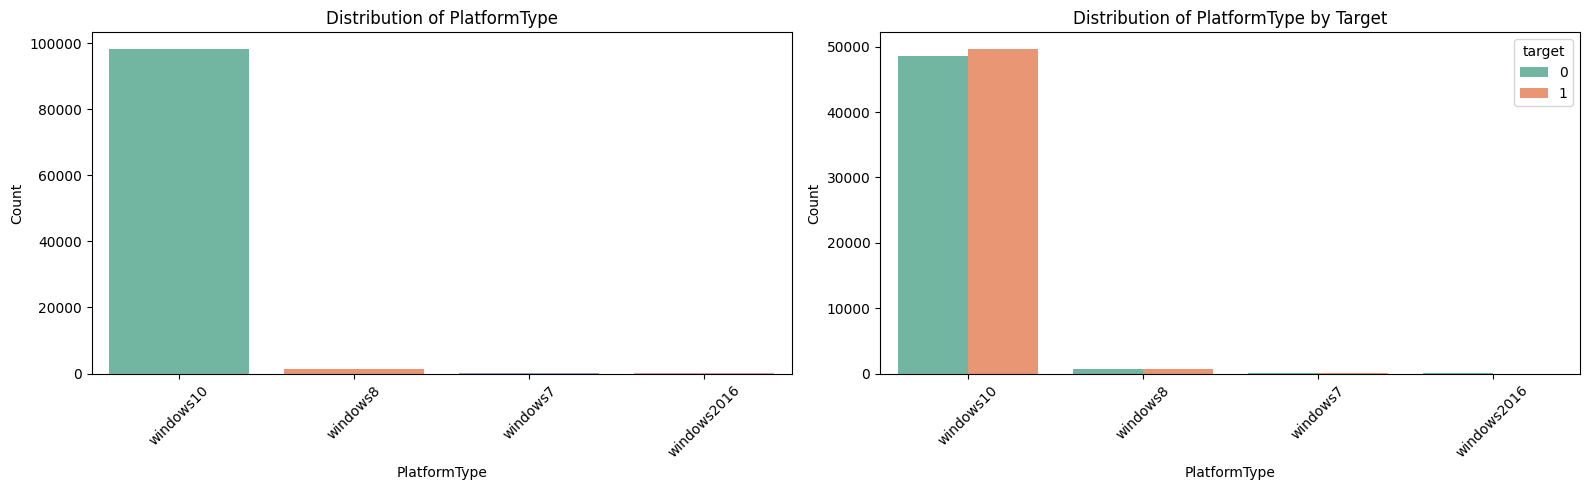

col


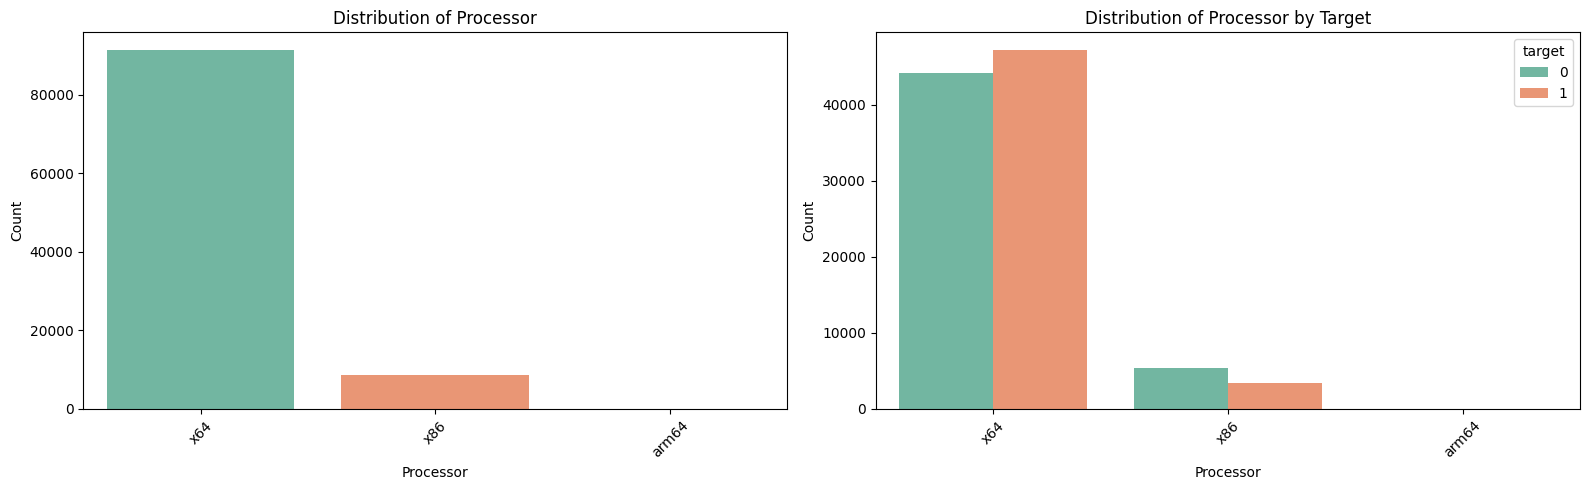

col


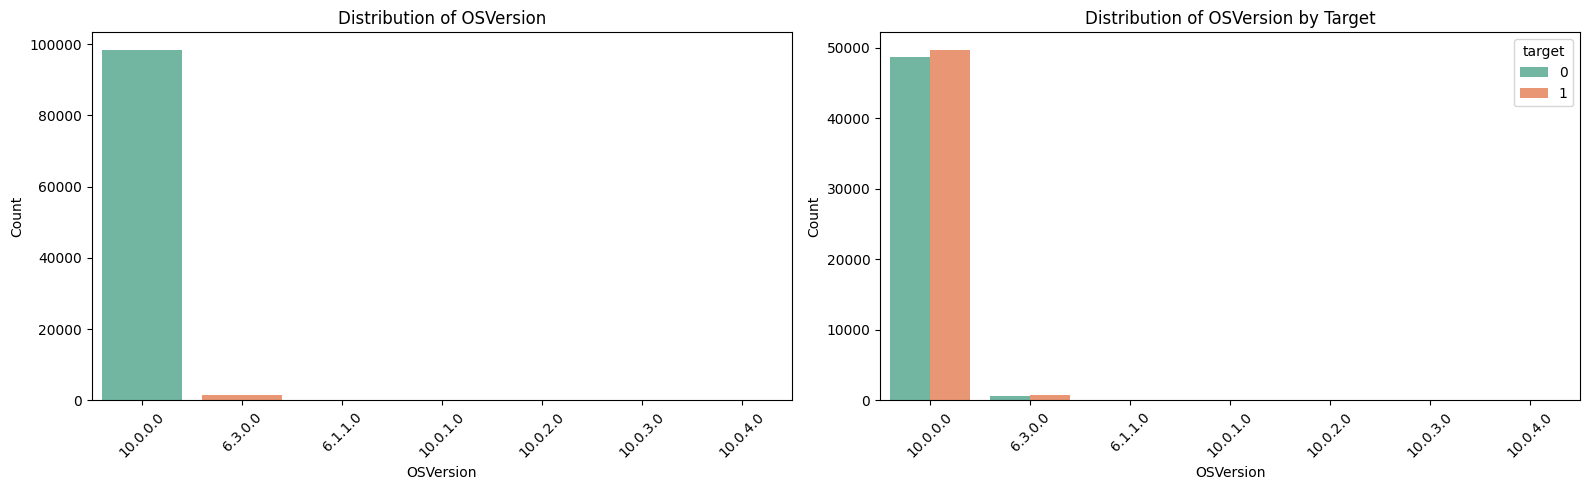

col


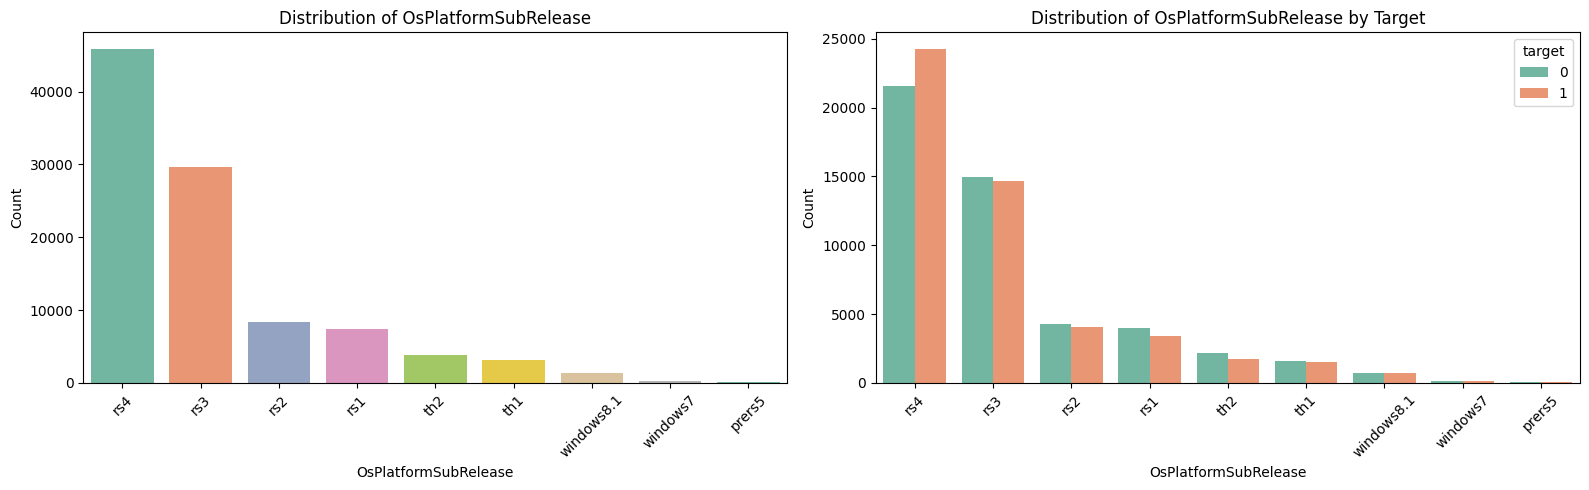

col


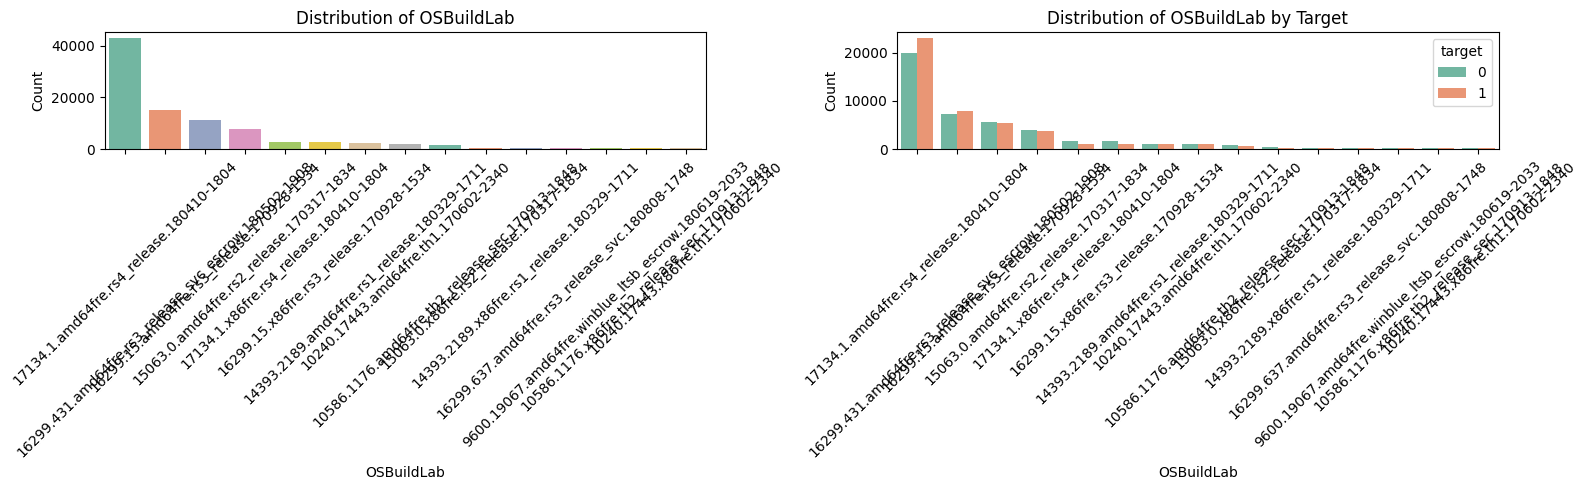

col


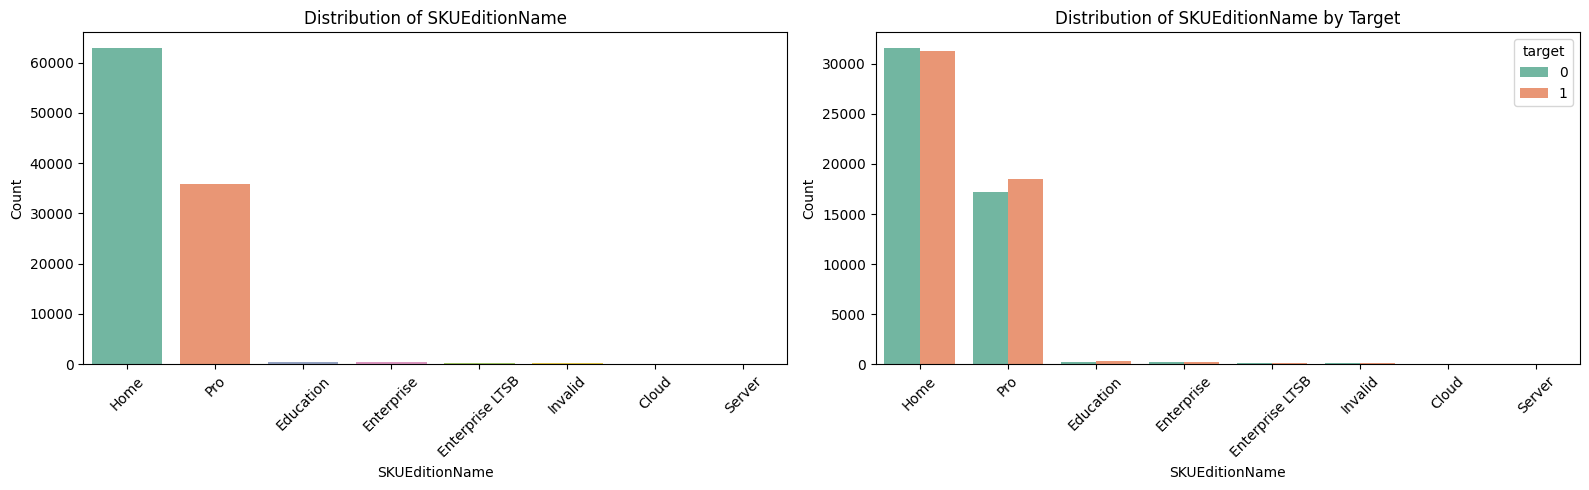

col


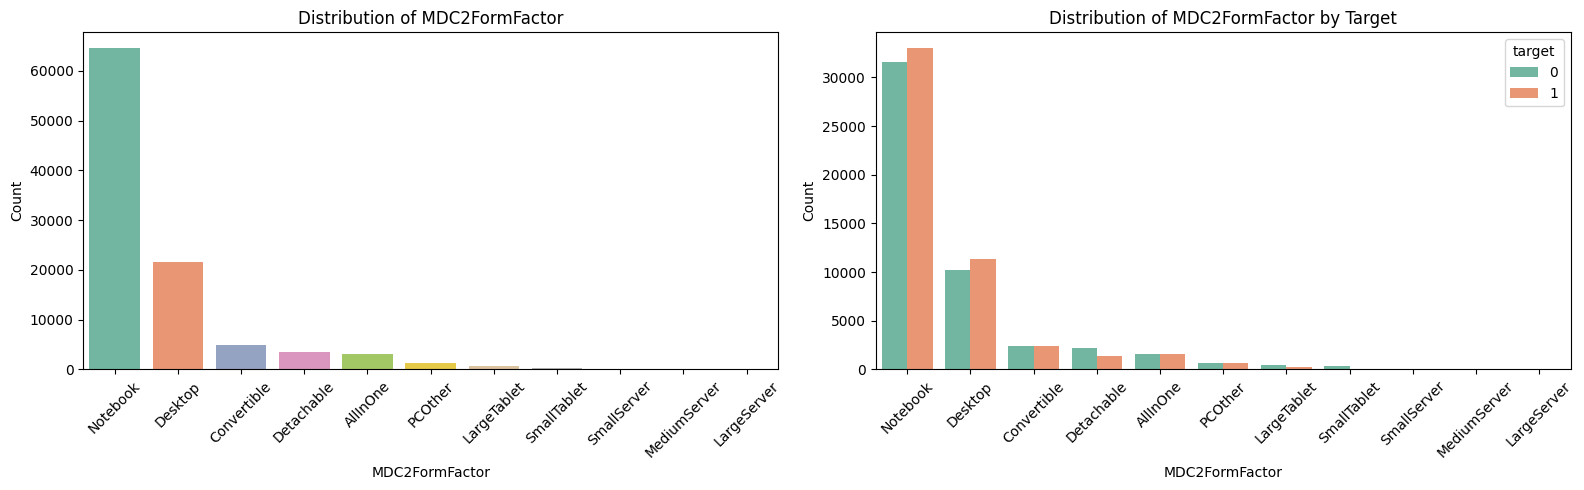

col


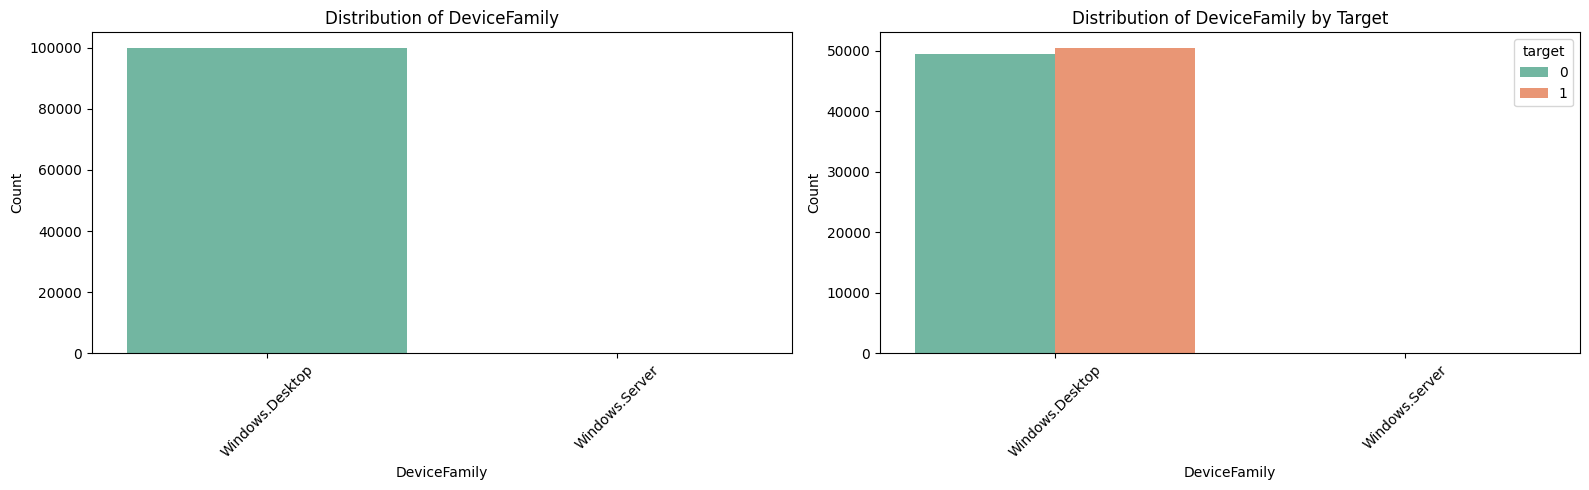

col


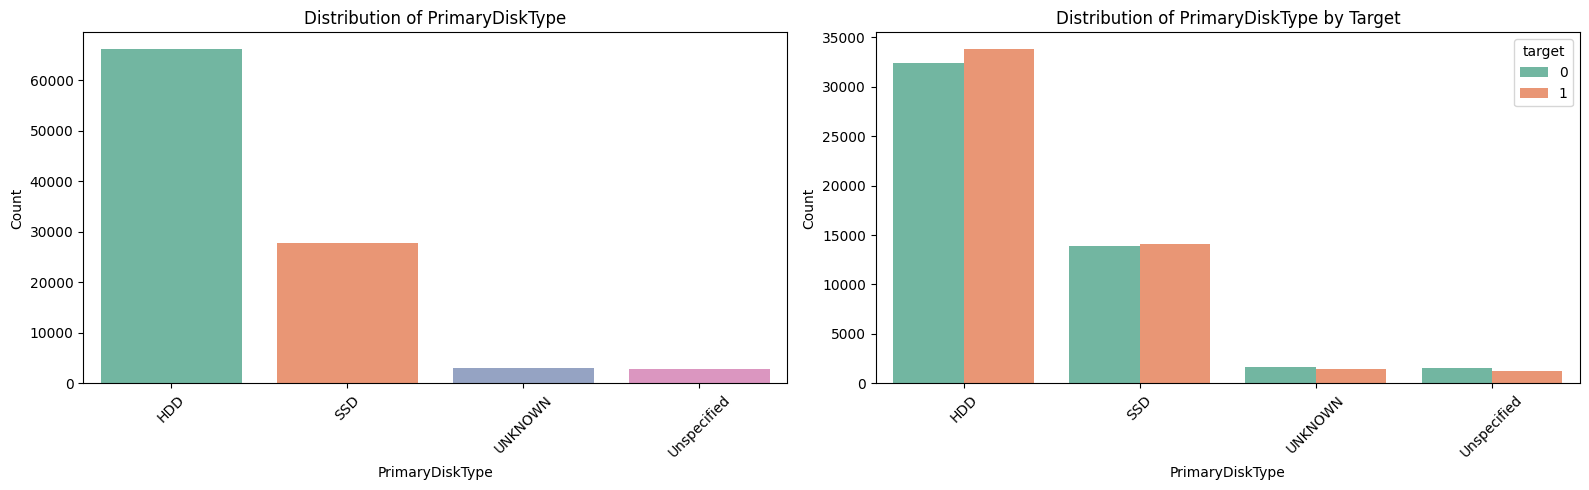

col


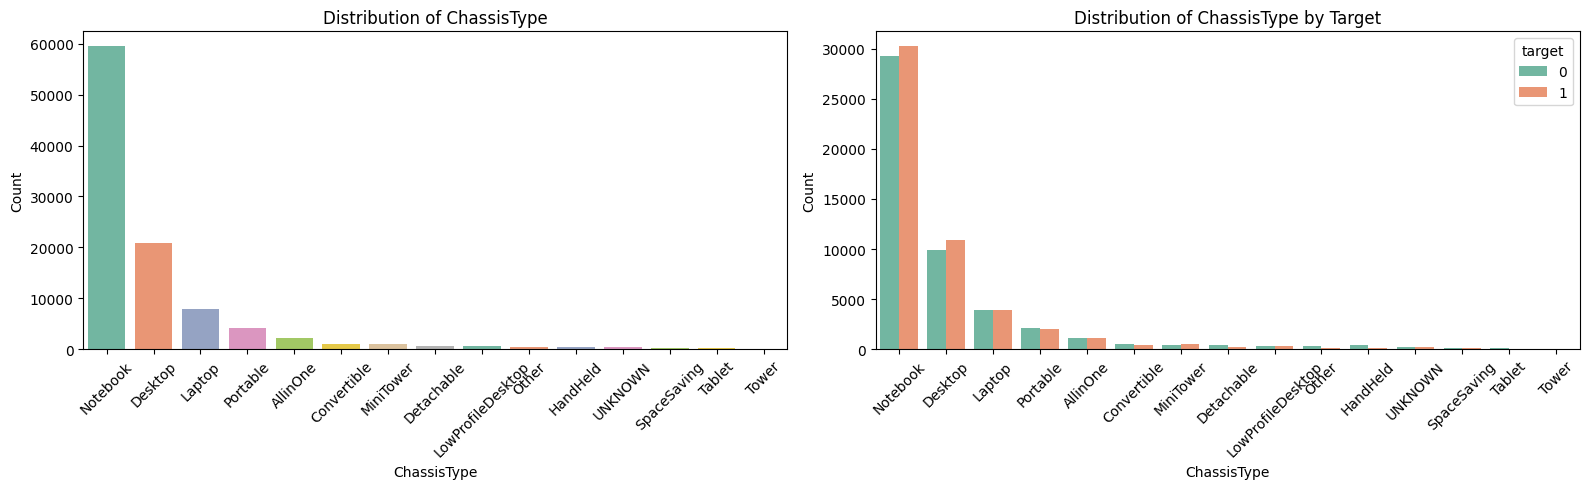

col


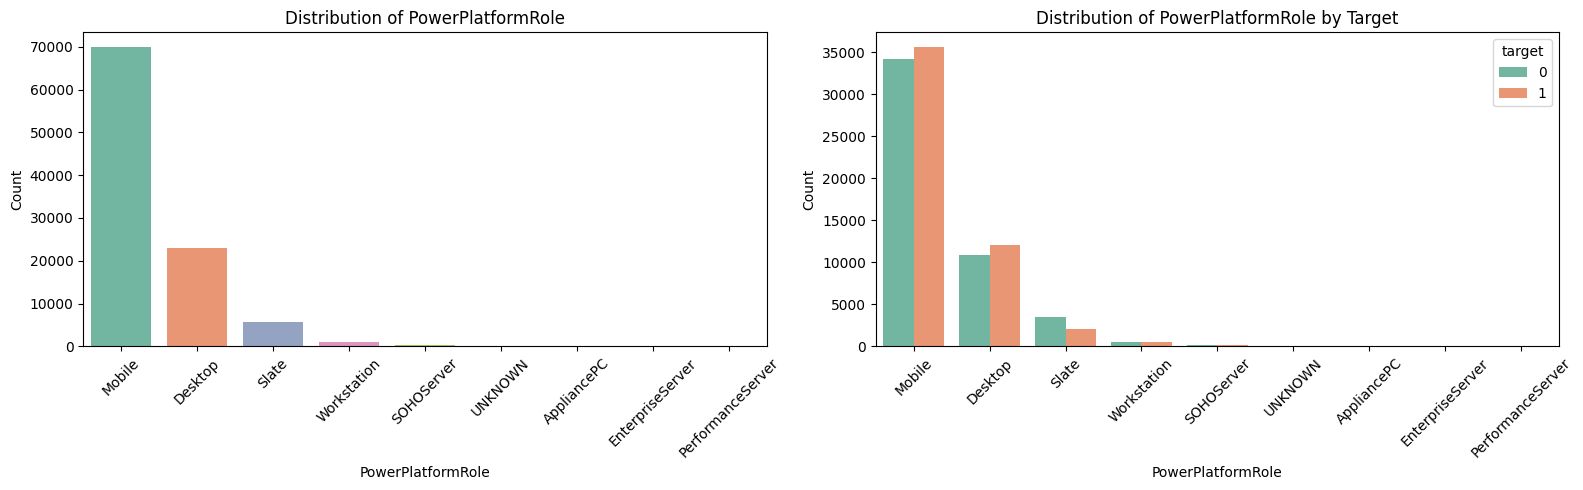

col


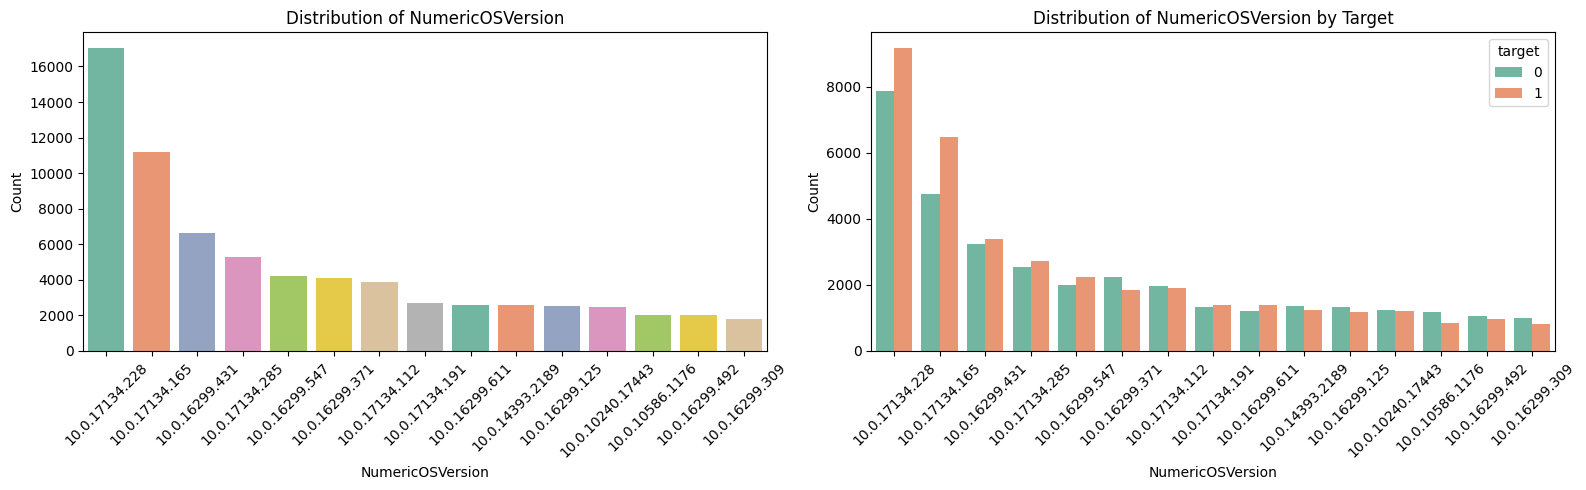

col


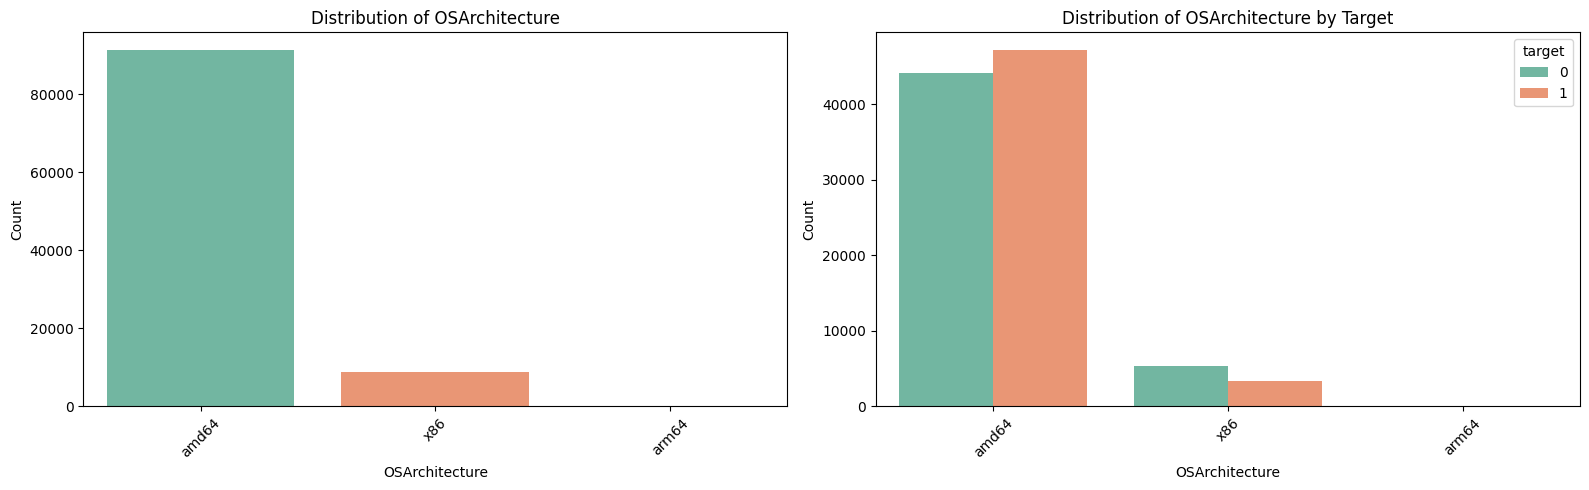

col


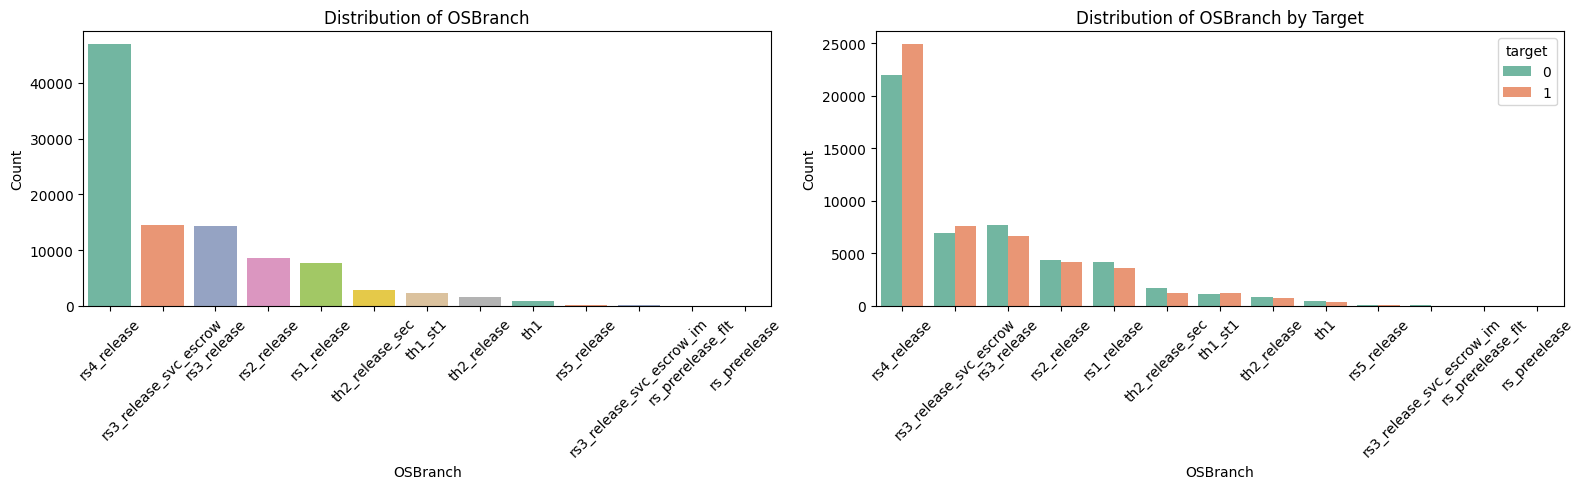

col


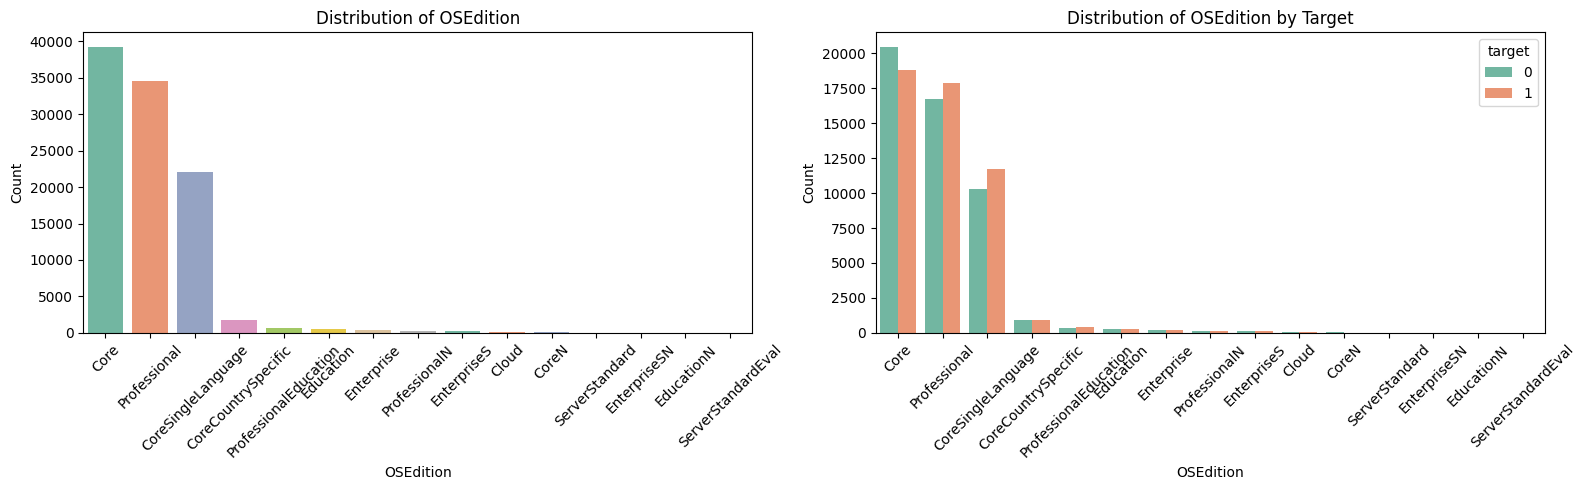

col


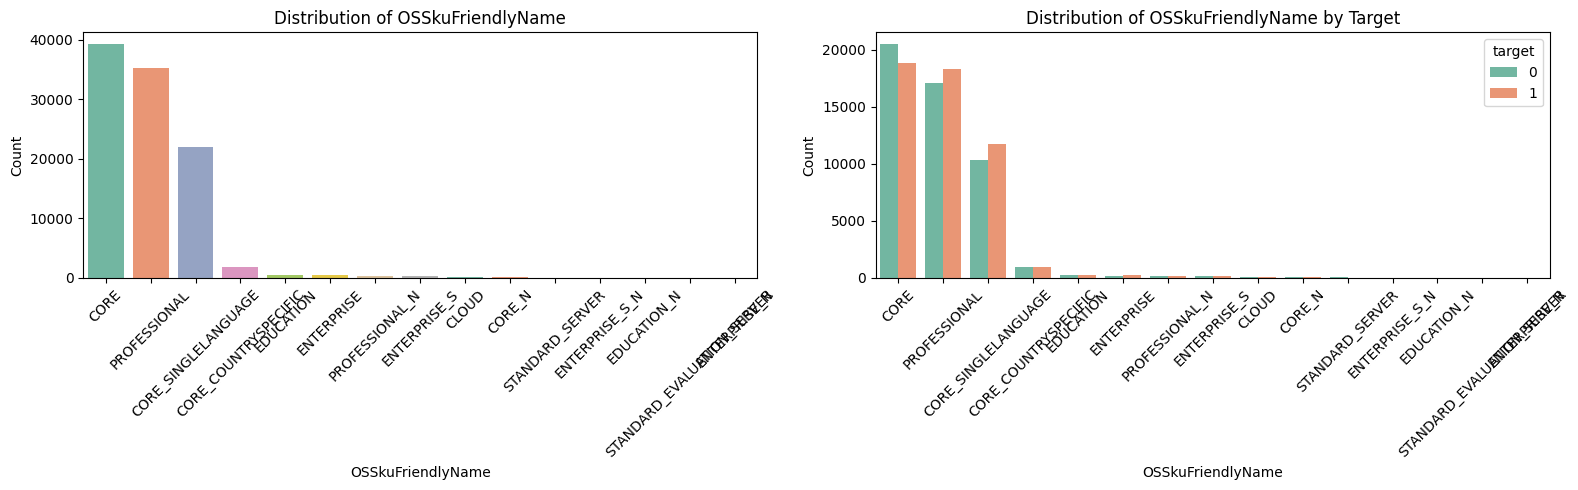

col


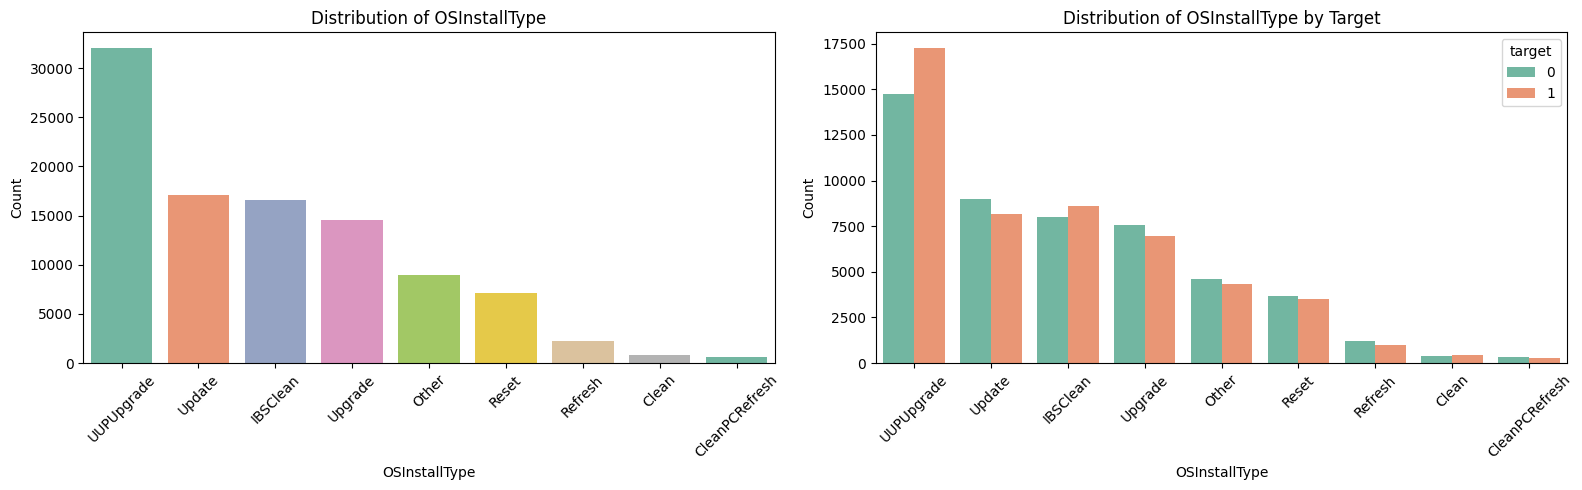

col


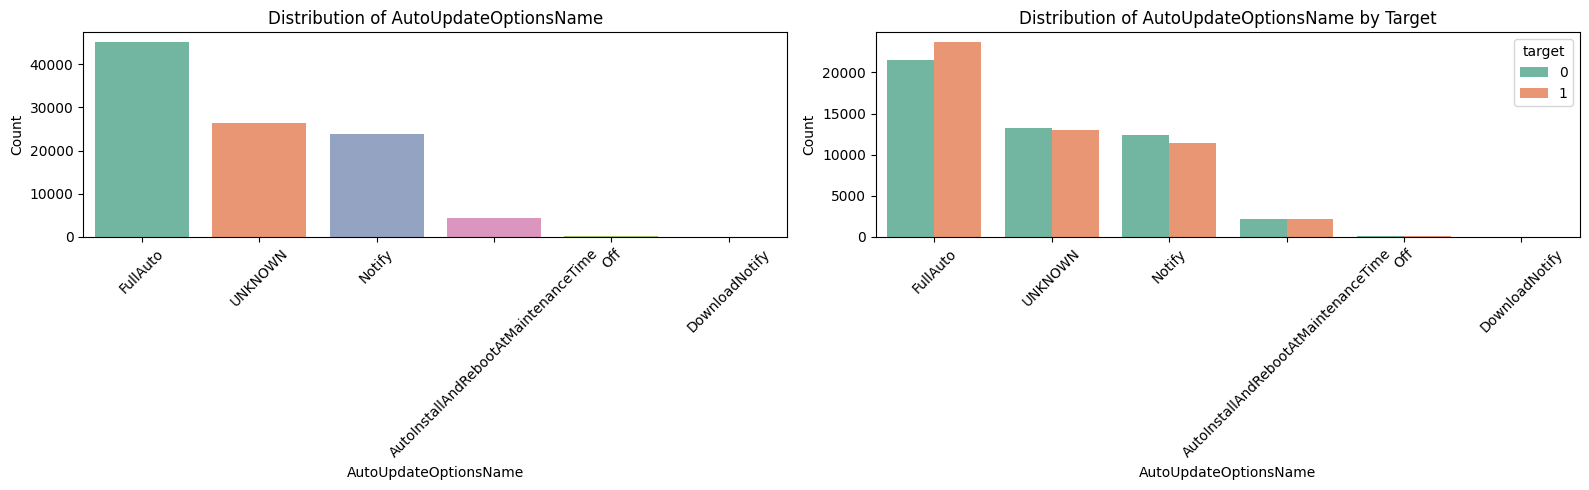

col


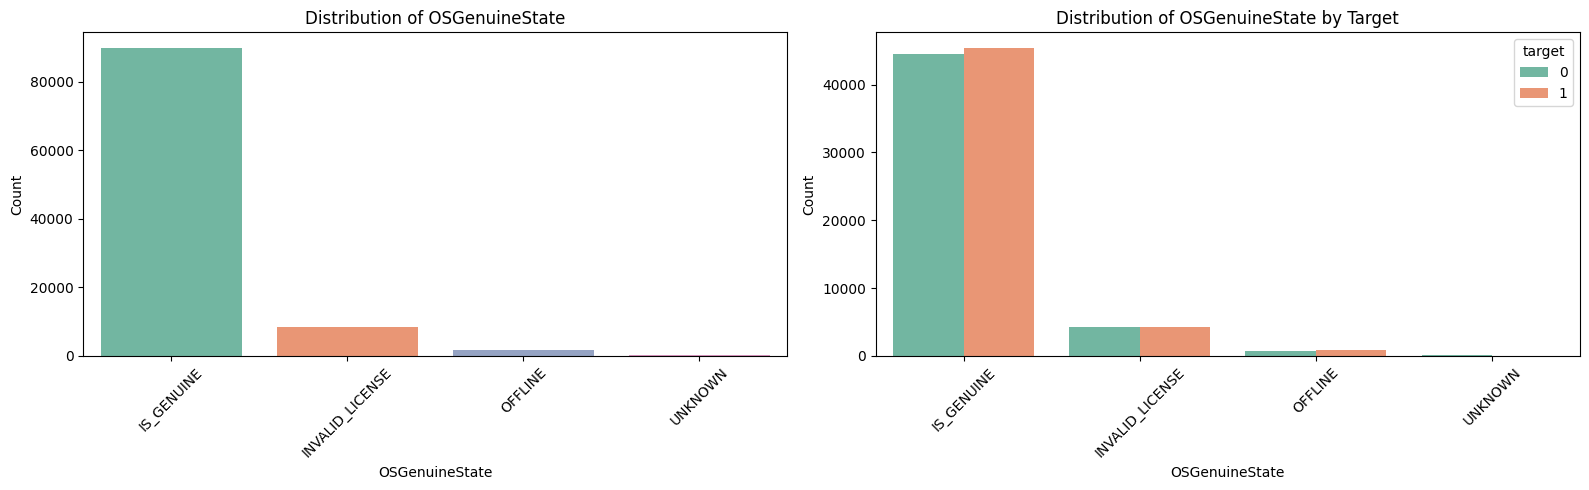

col


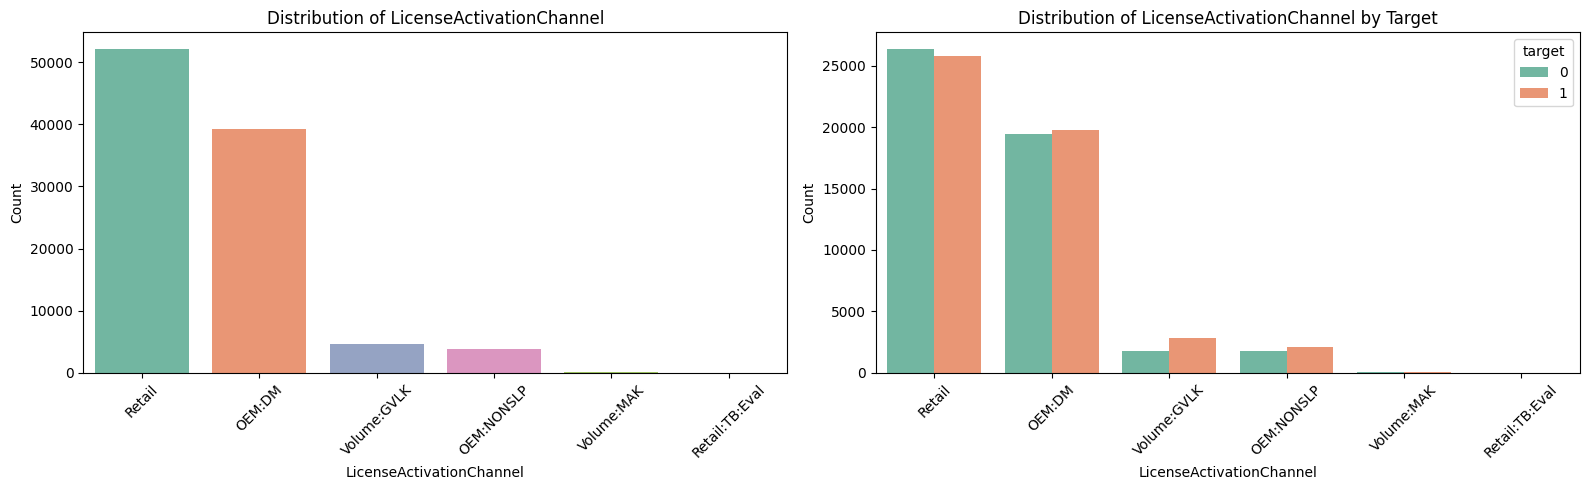

col


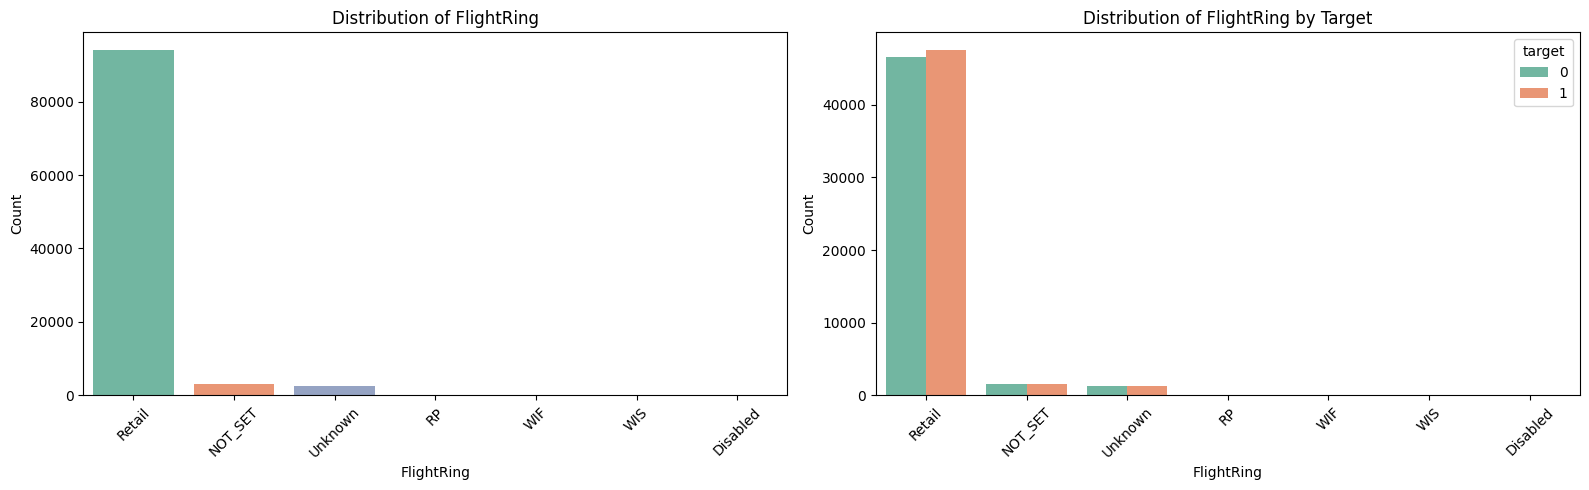

col


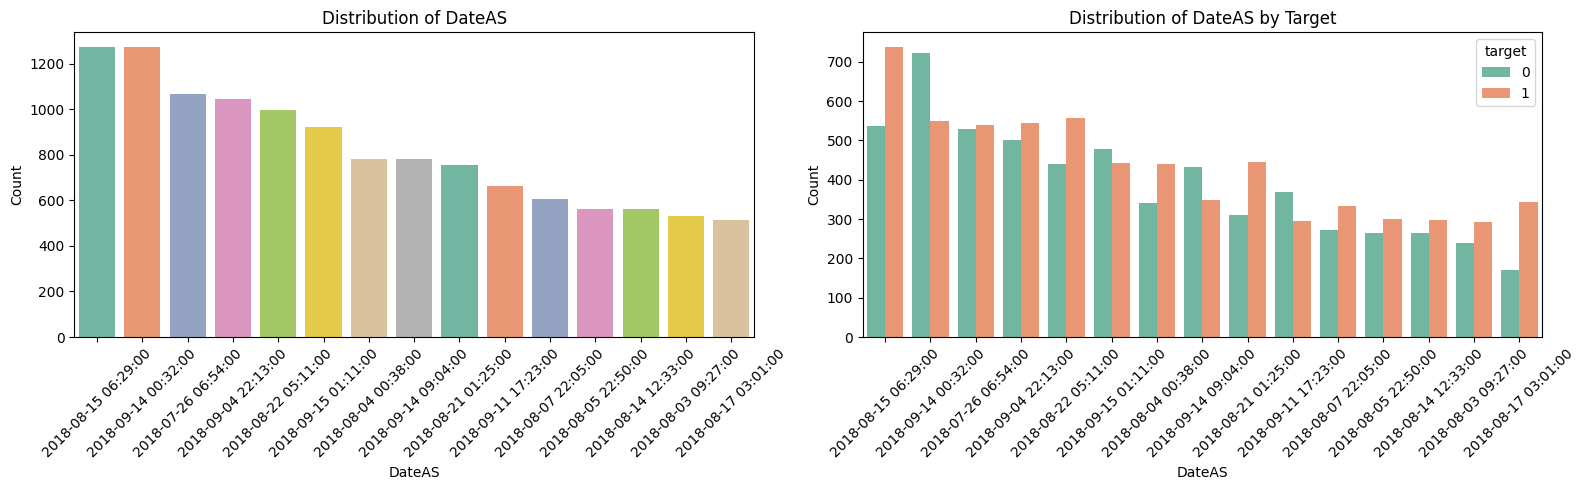

col


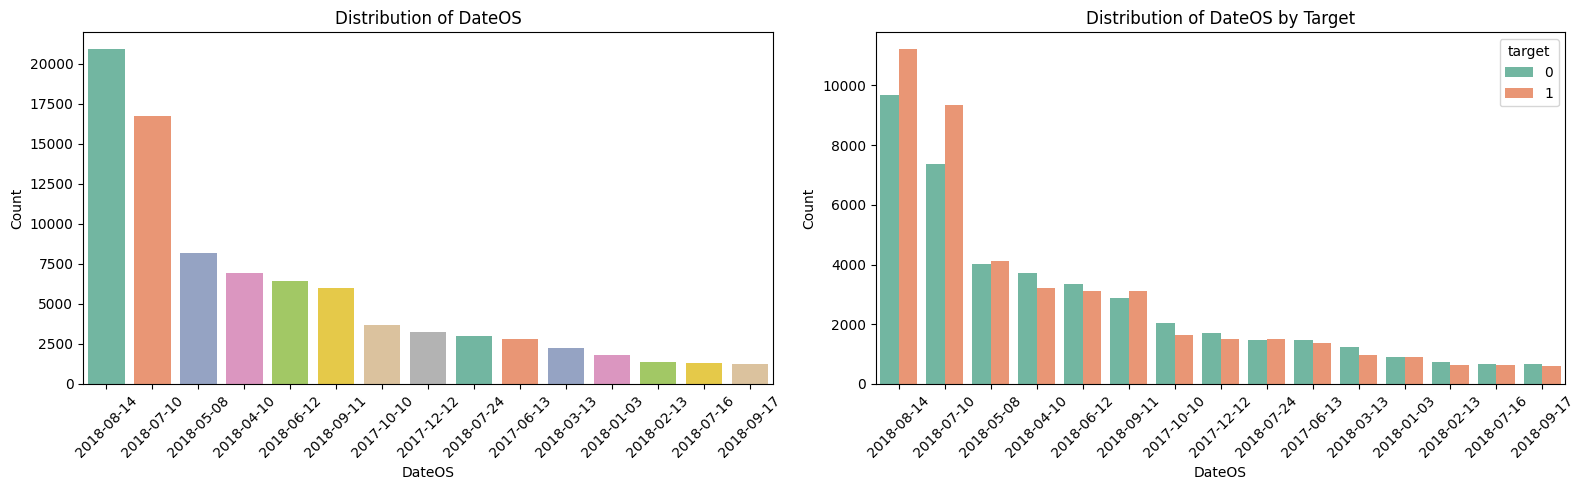

In [15]:
for col in cat_features:  
    print("col")
    fig, axes = plt.subplots(1, 2, figsize=(16, 5))
    top_categories = data[col].value_counts().index[:15]
    
    sns.countplot(data=data, x=col, order=top_categories, palette='Set2', ax=axes[0])
    axes[0].set_title(f"Distribution of {col}")
    axes[0].set_xlabel(col)
    axes[0].set_ylabel("Count")
    axes[0].tick_params(axis='x', rotation=45)
    
    sns.countplot(data=data, x=col, hue='target', order=top_categories, palette='Set2', ax=axes[1])
    axes[1].set_title(f"Distribution of {col} by Target")
    axes[1].set_xlabel(col)
    axes[1].set_ylabel("Count")
    axes[1].tick_params(axis='x', rotation=45)
    
    plt.tight_layout()
    plt.show()

### The distribution of categories in many features is biased, but the proportion of target is not that biased
### Do test have the similar distribution????

col


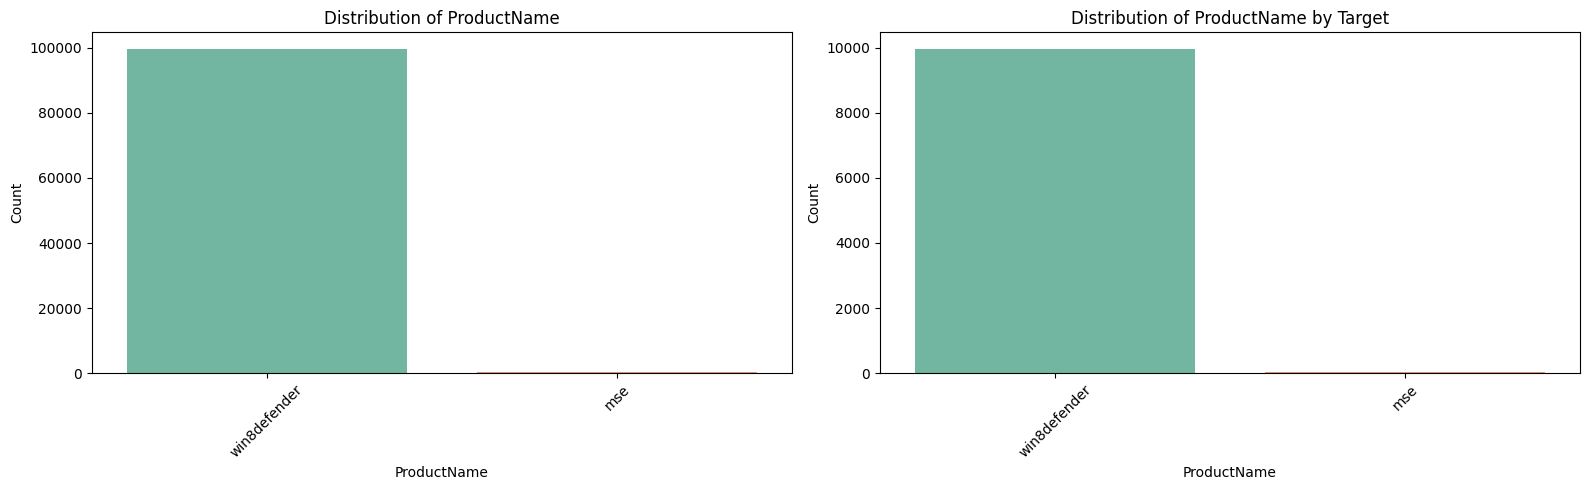

col


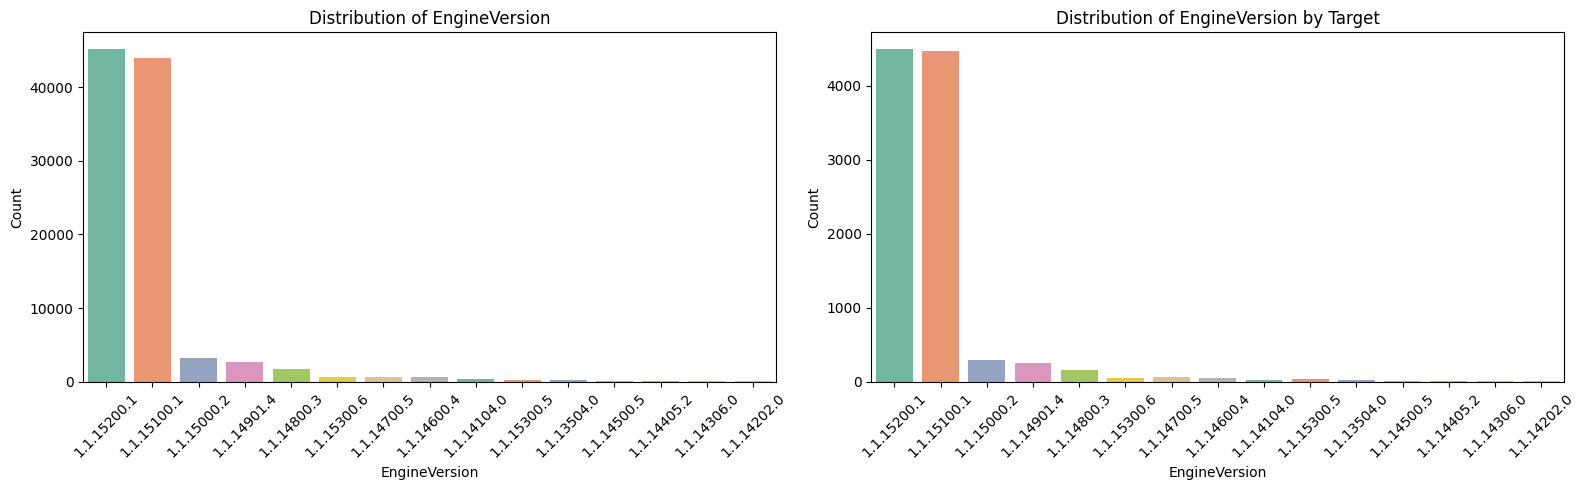

col


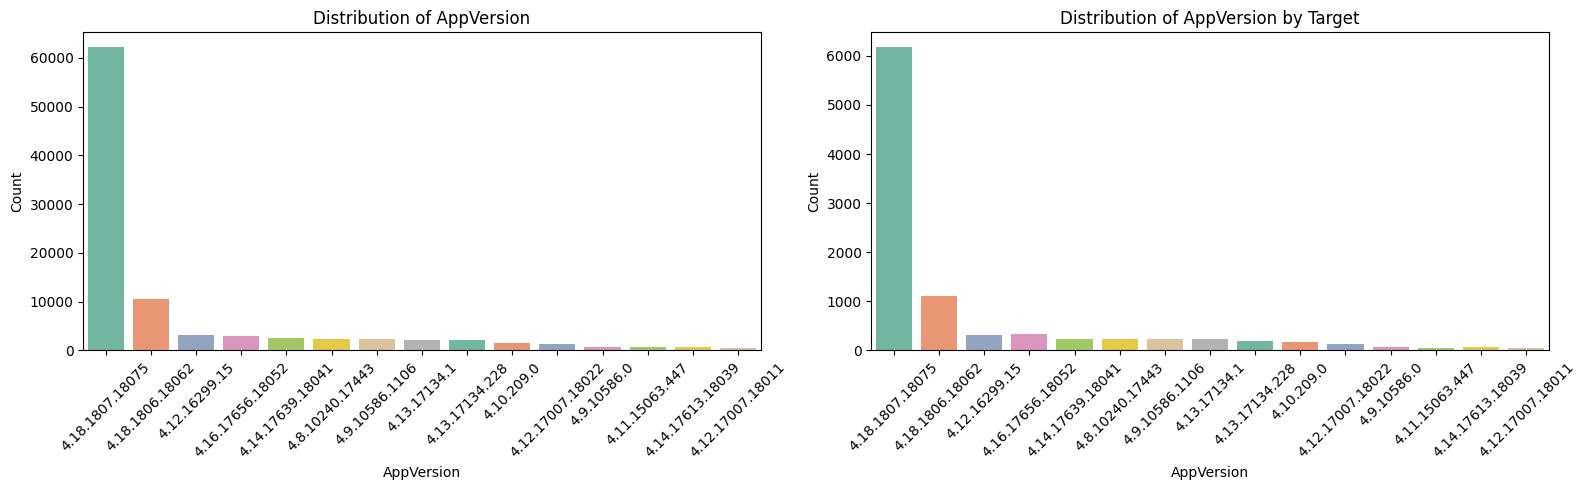

col


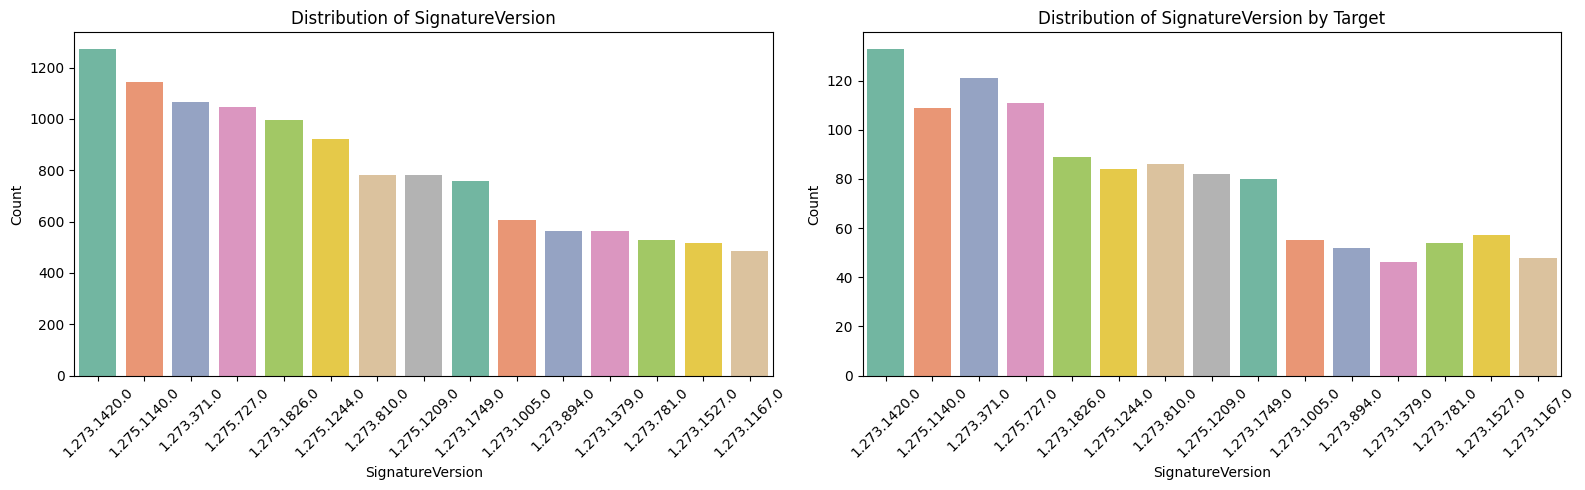

col


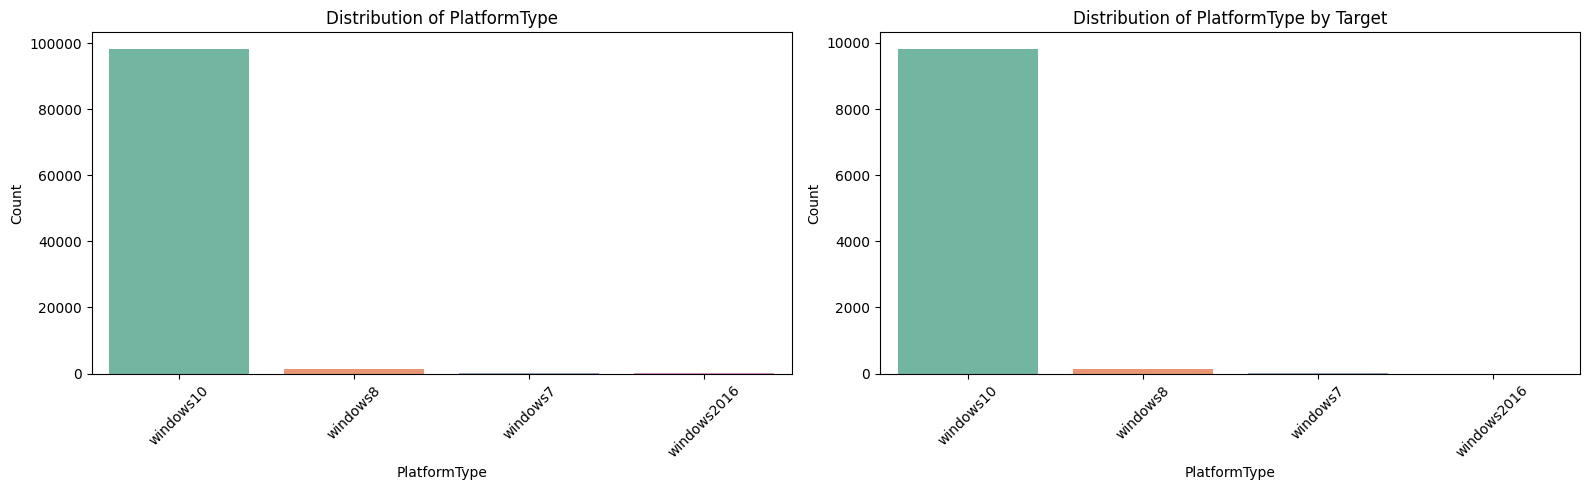

col


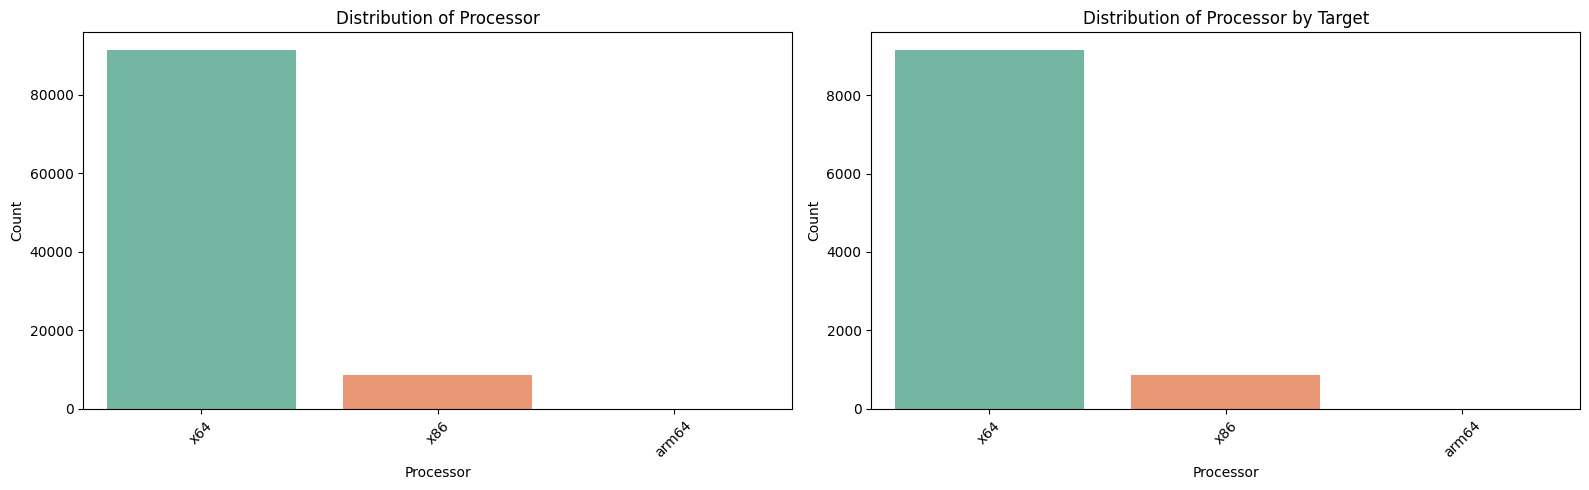

col


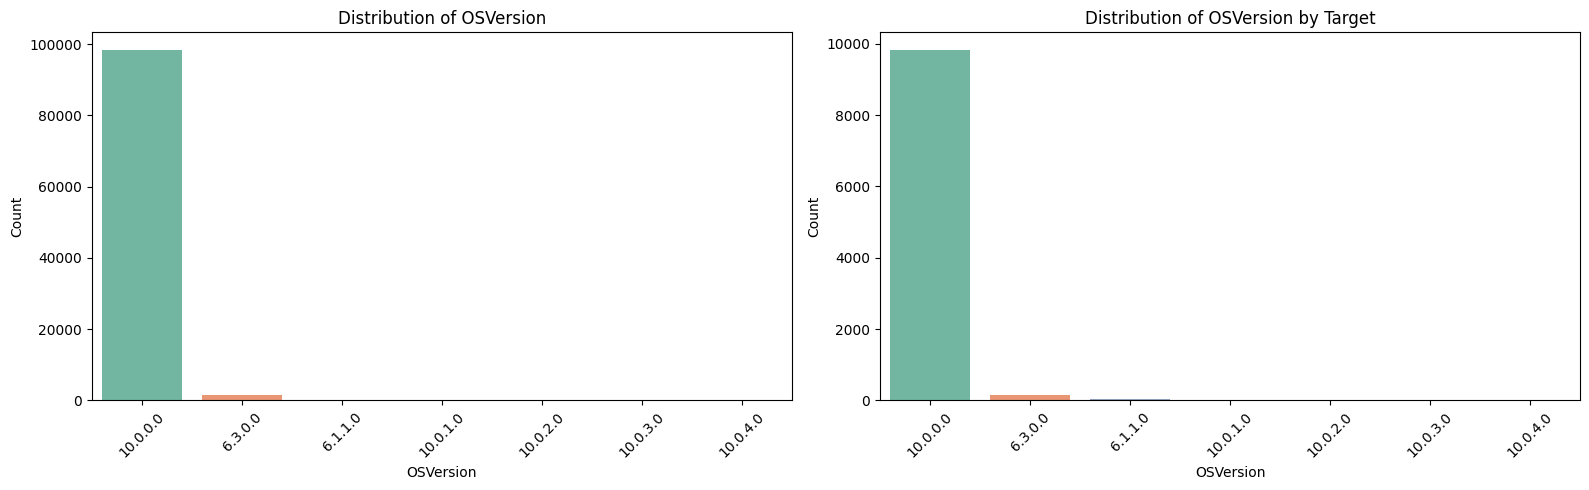

col


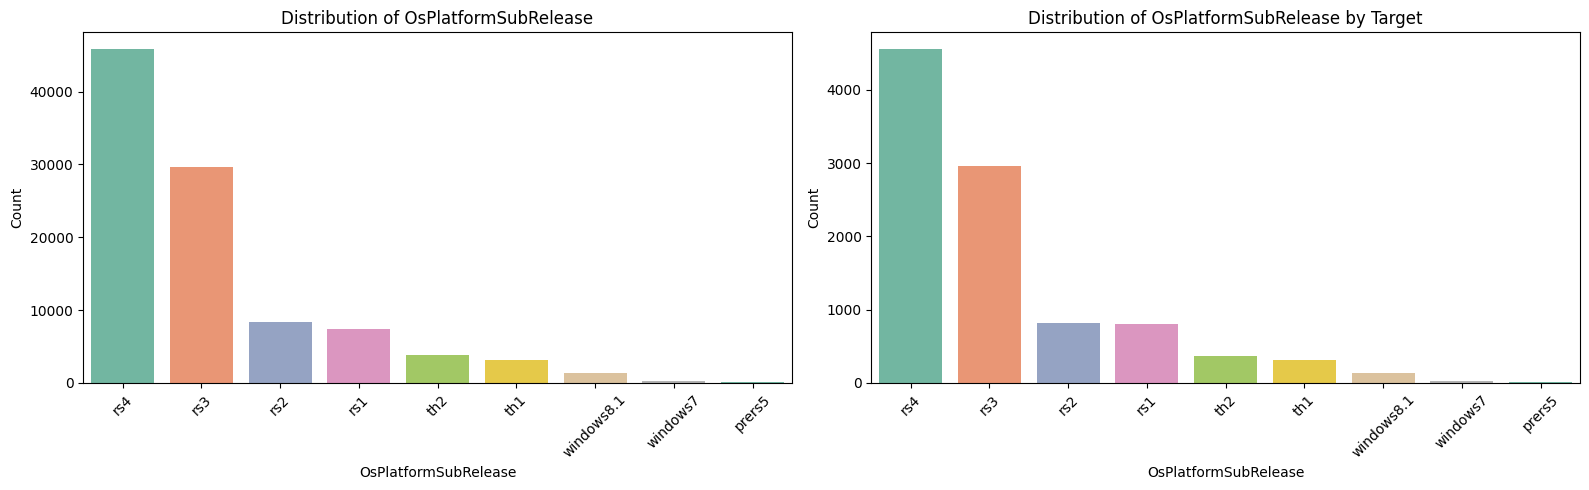

col


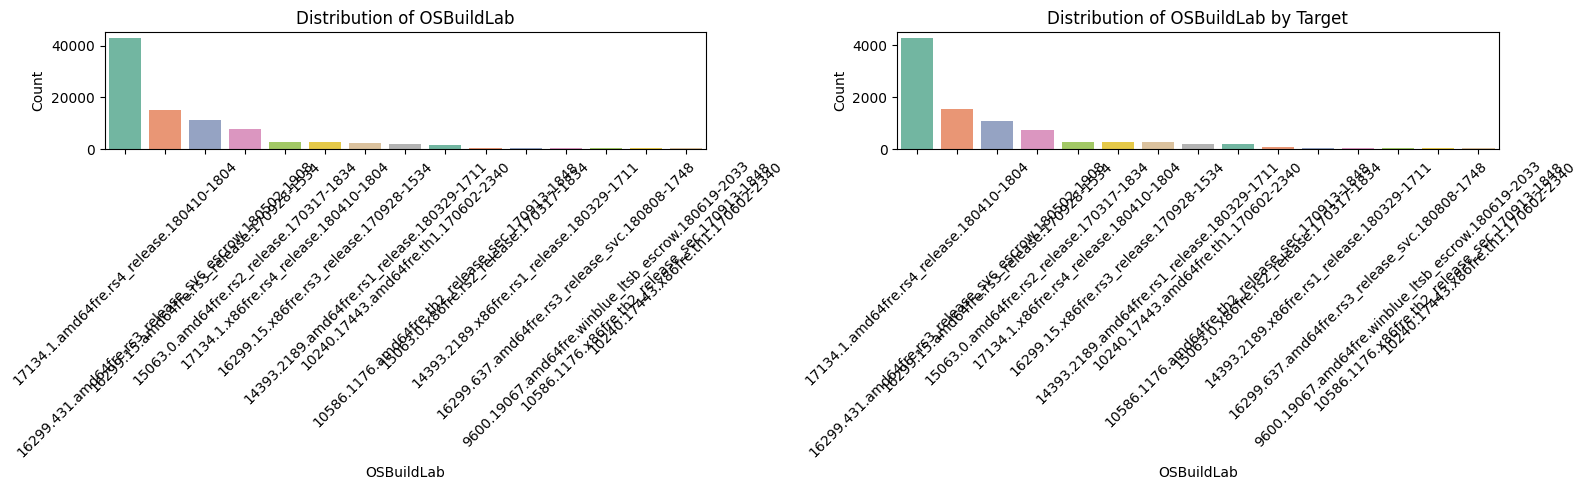

col


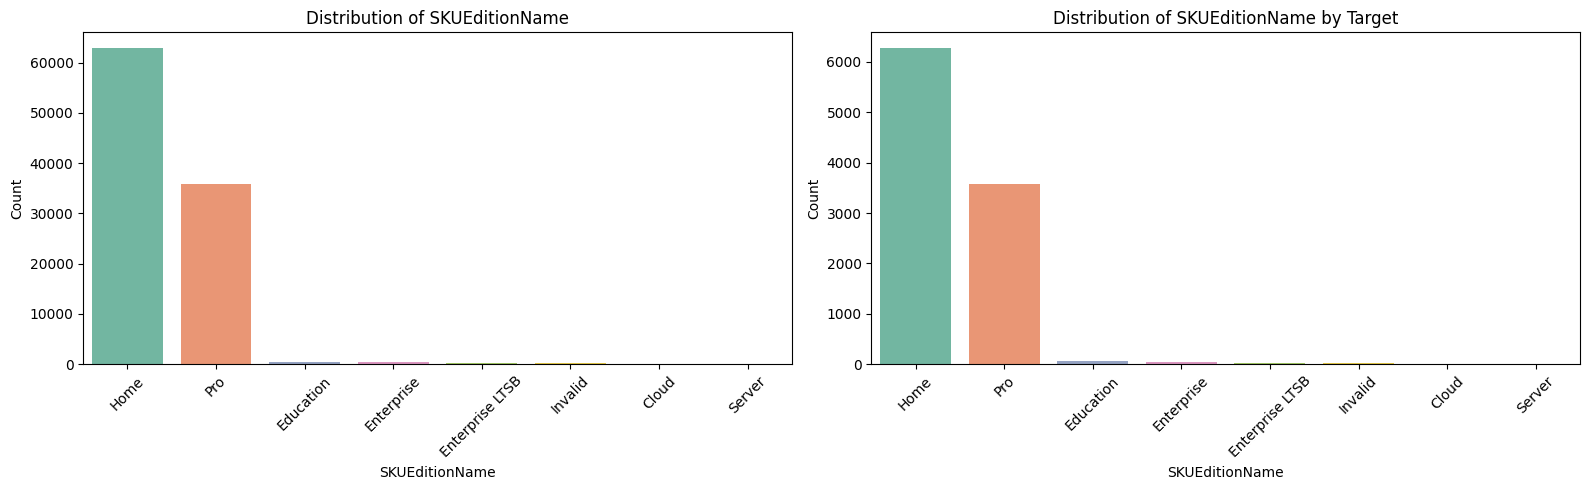

col


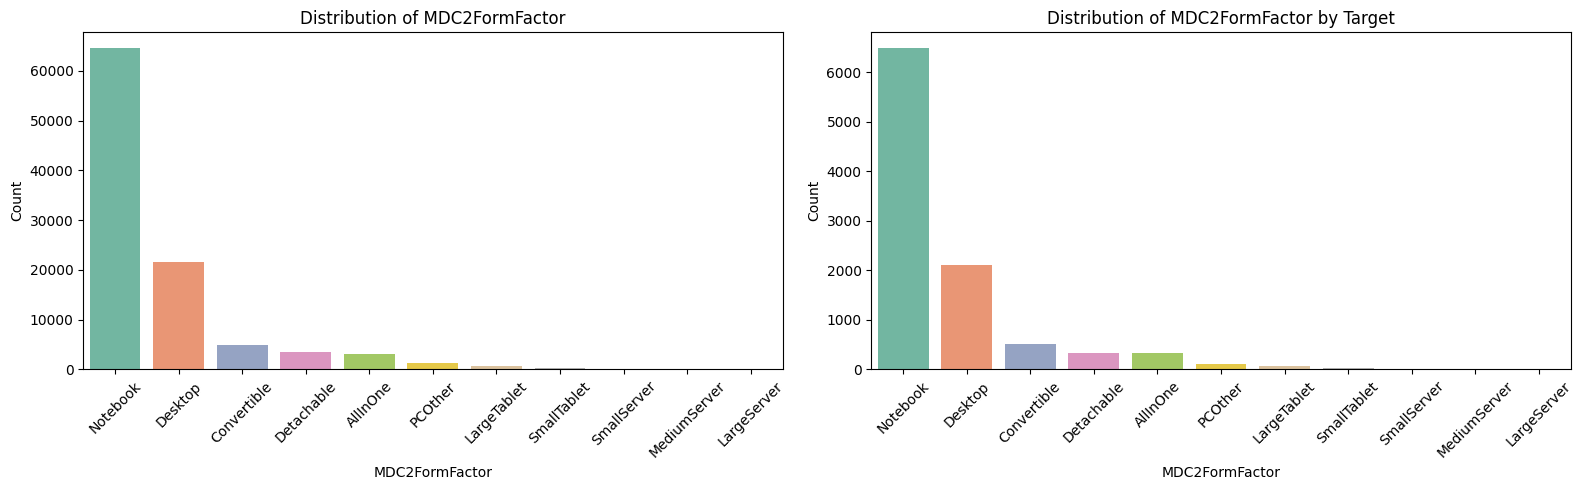

col


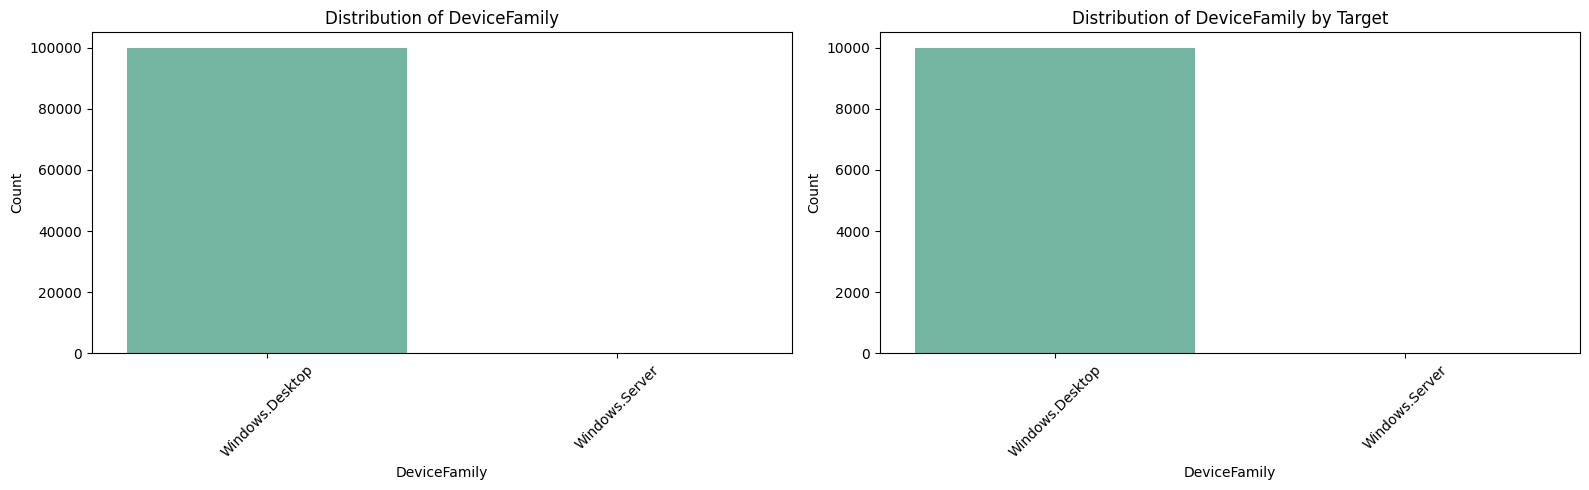

col


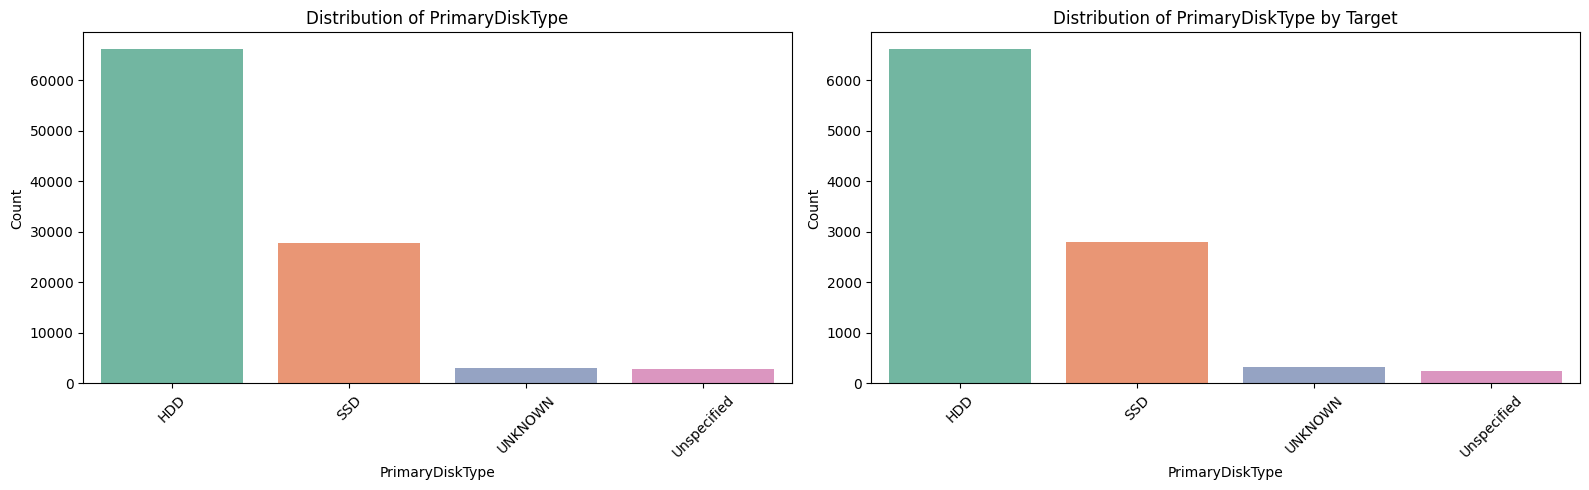

col


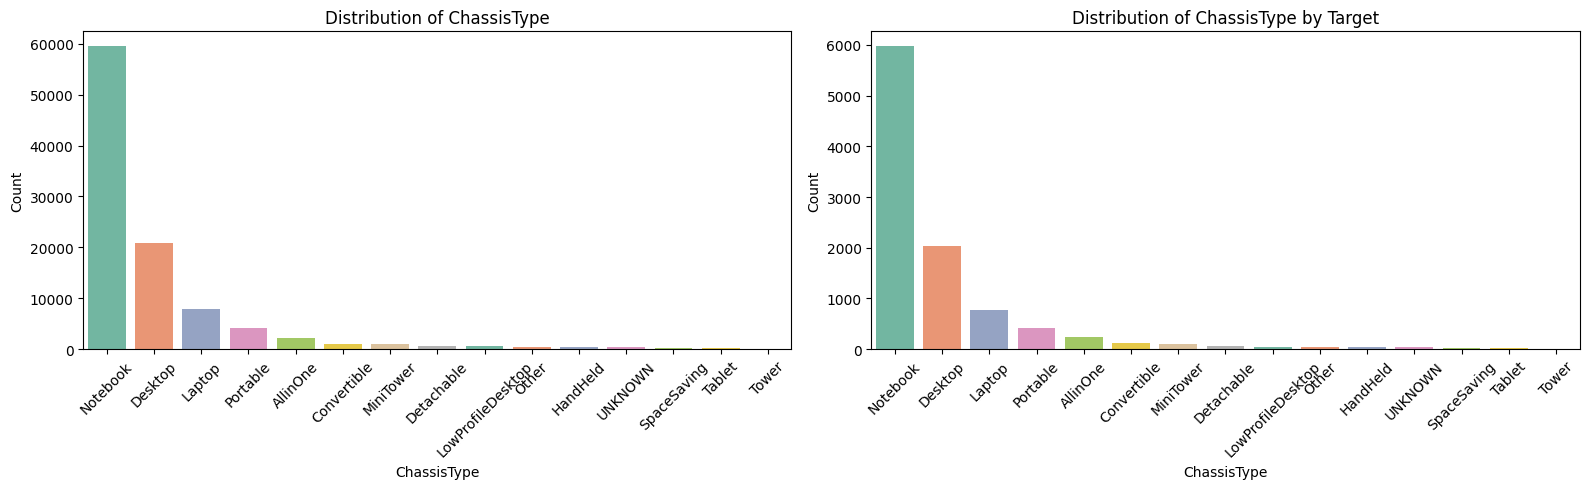

col


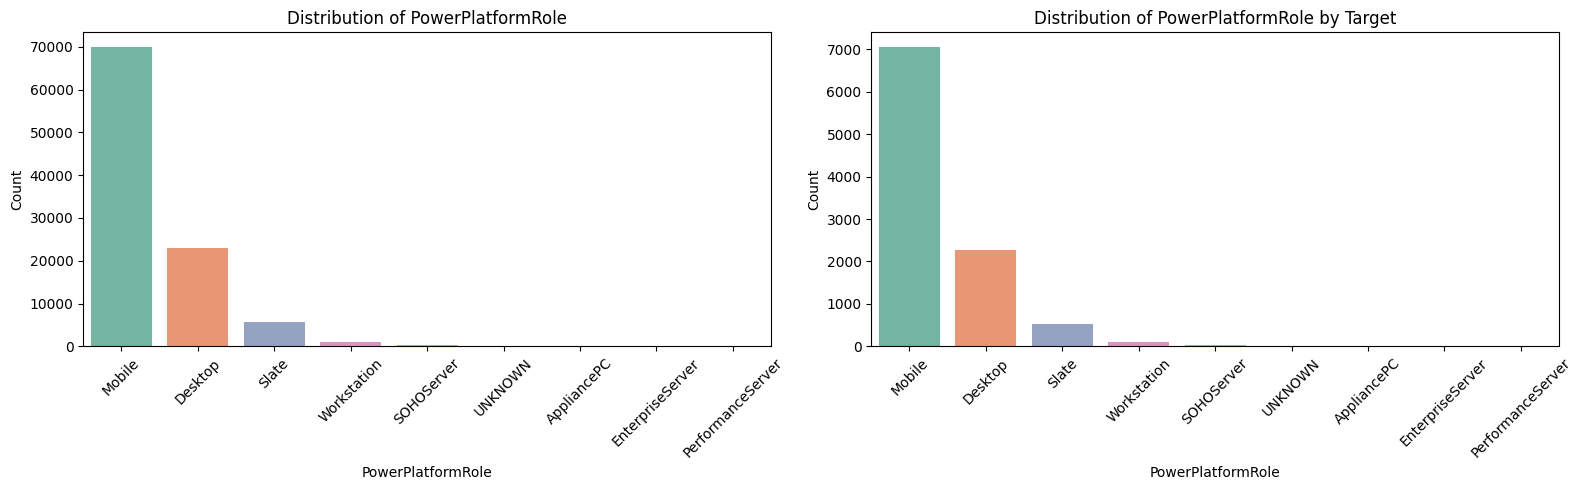

col


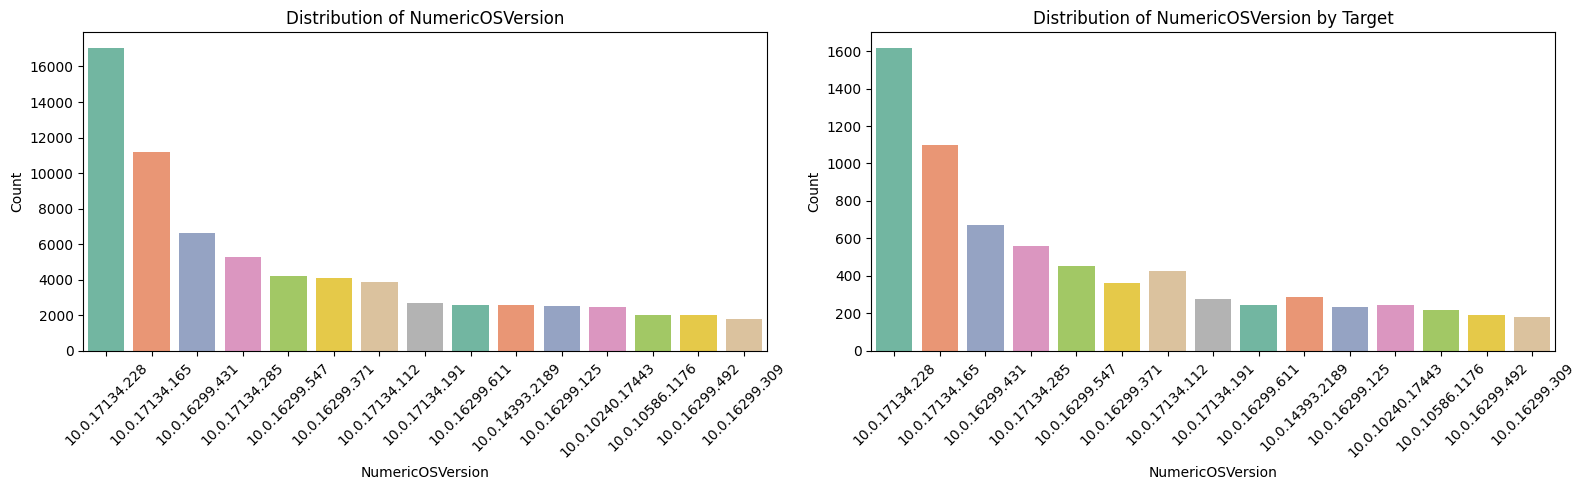

col


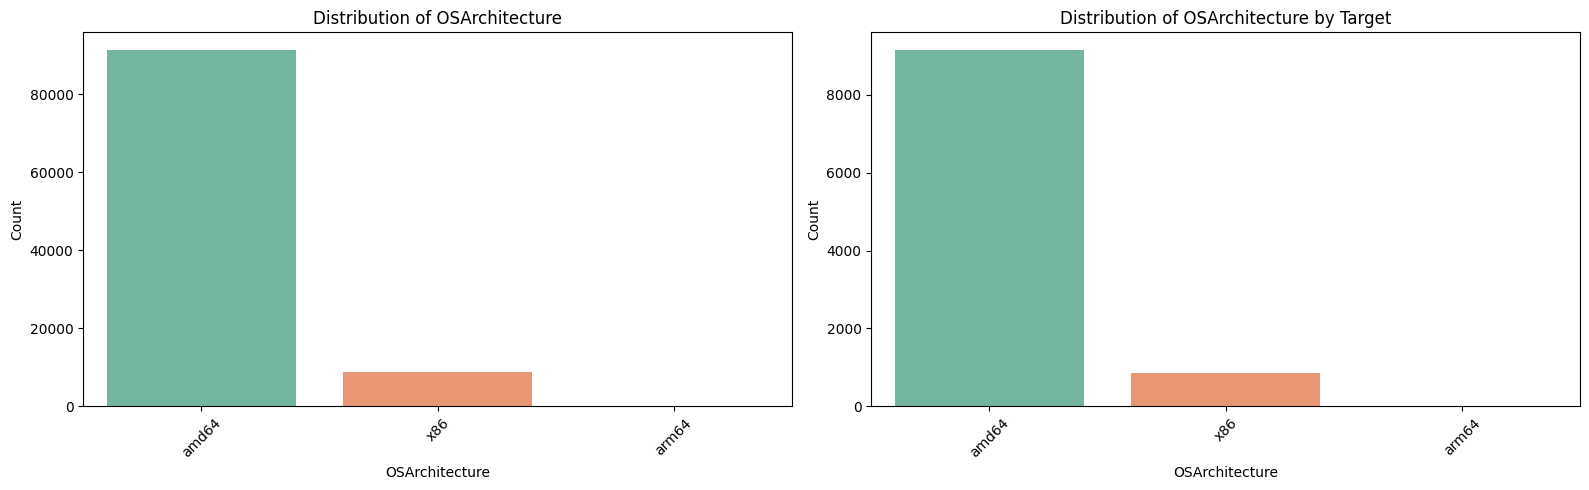

col


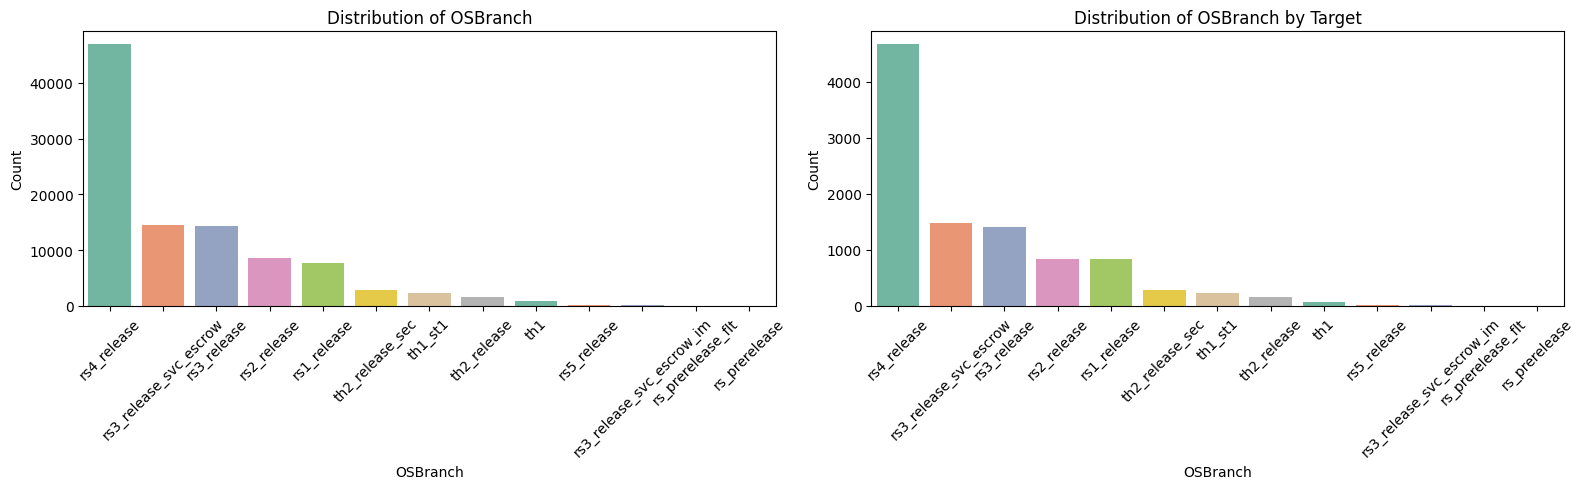

col


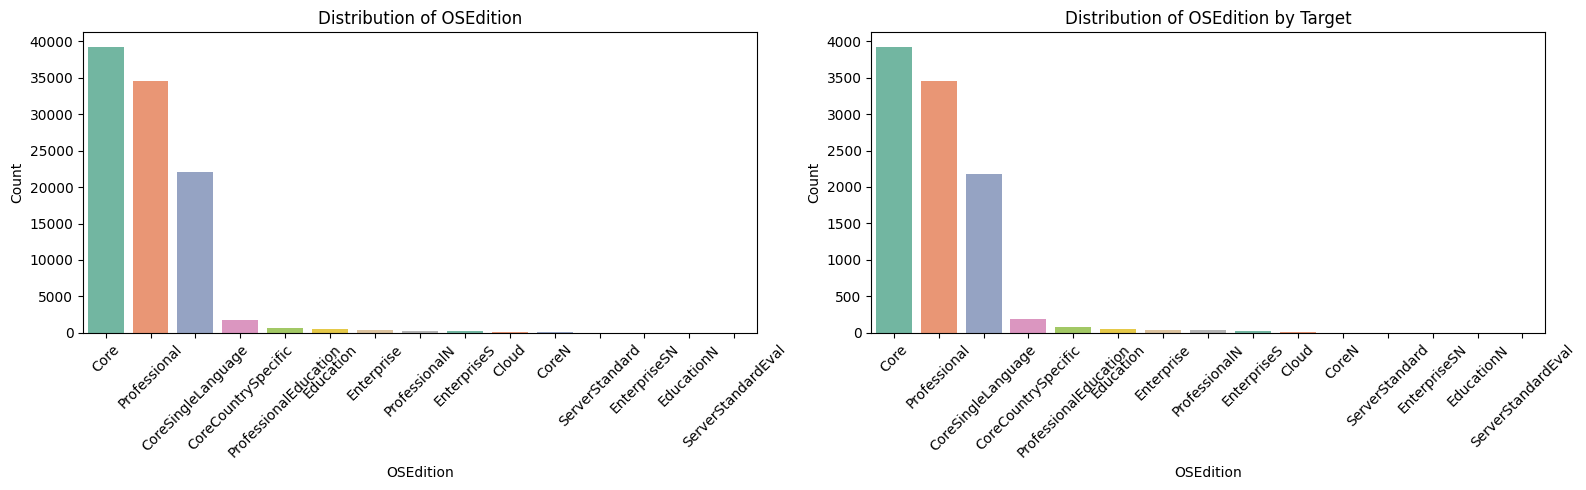

col


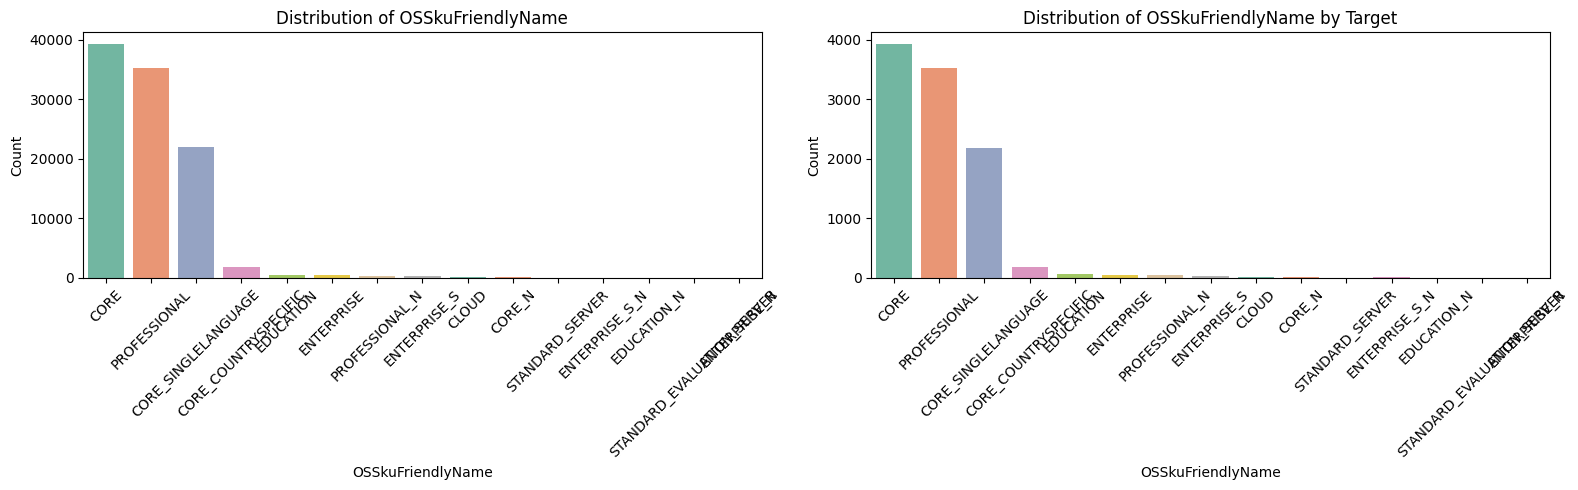

col


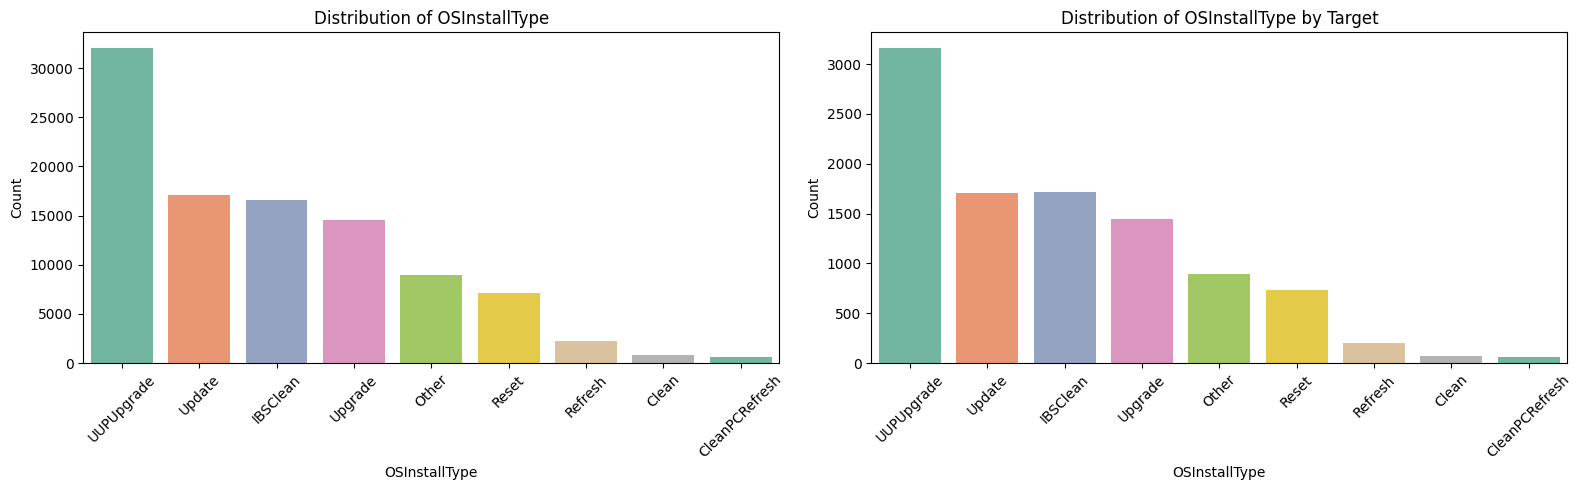

col


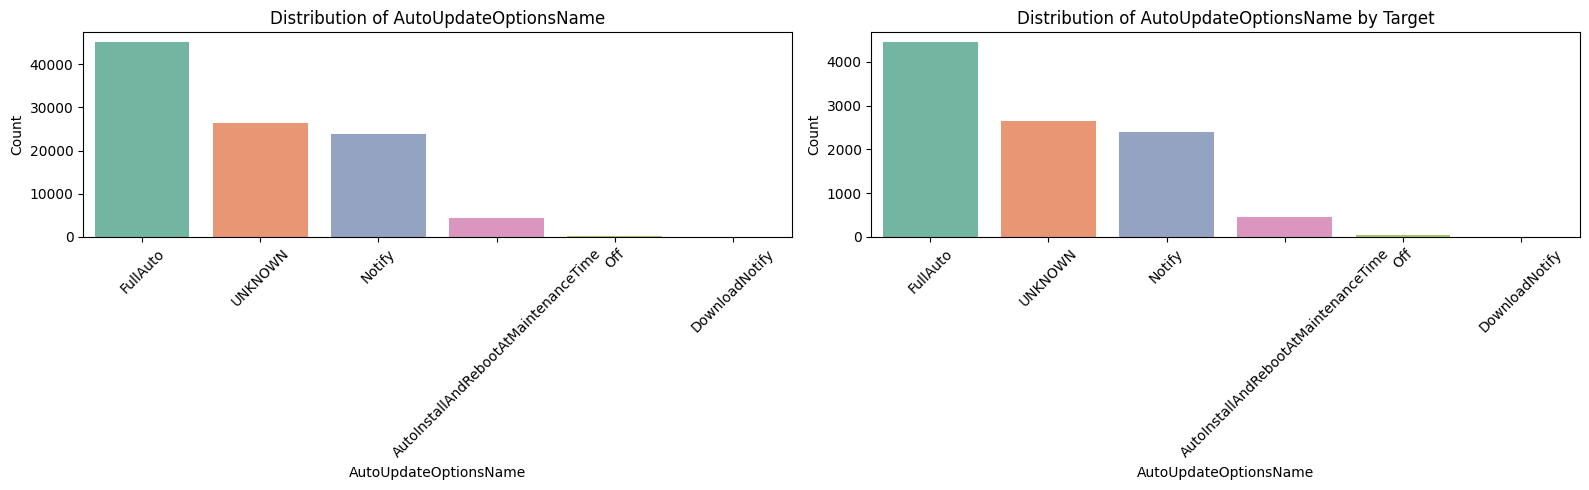

col


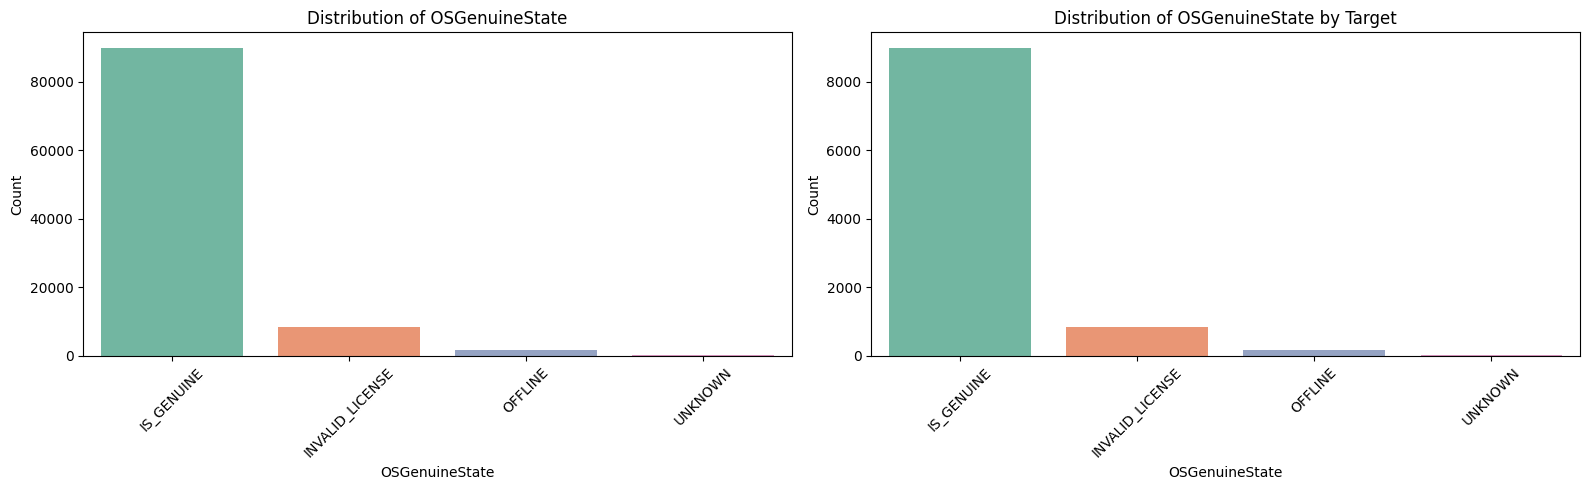

col


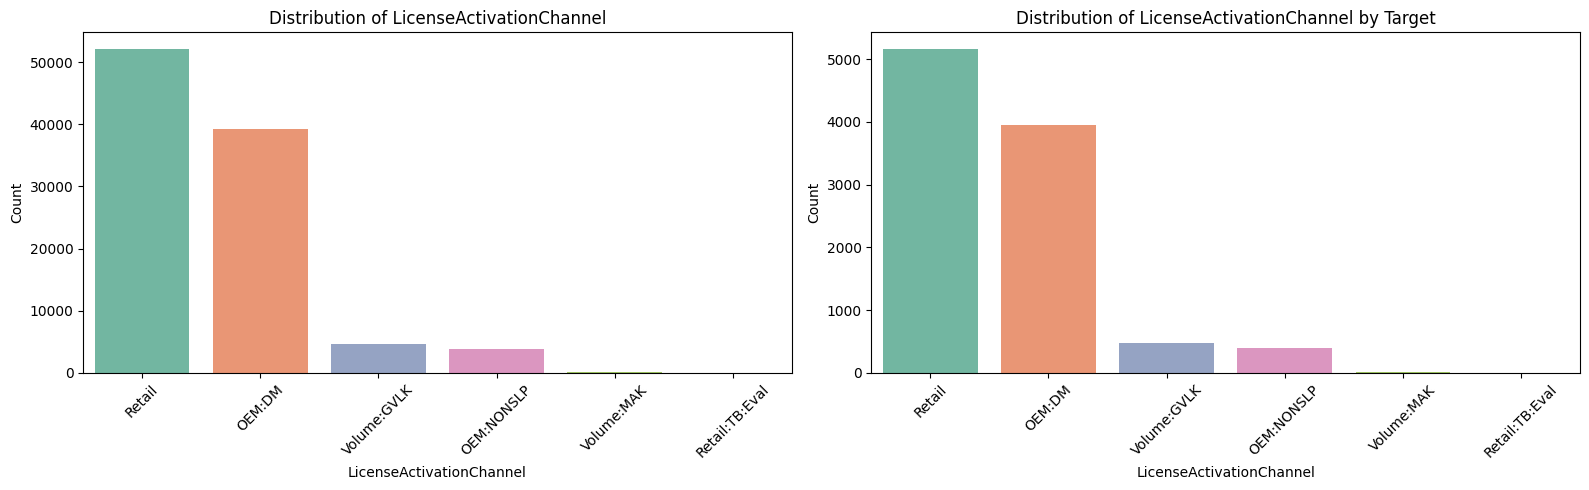

col


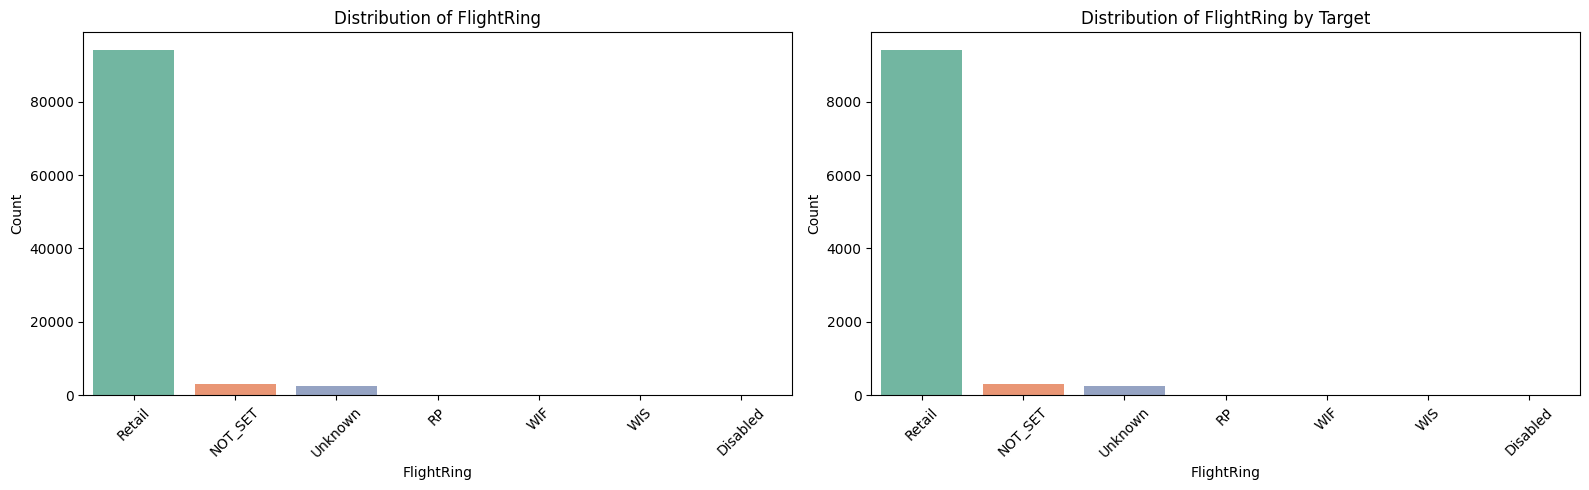

col


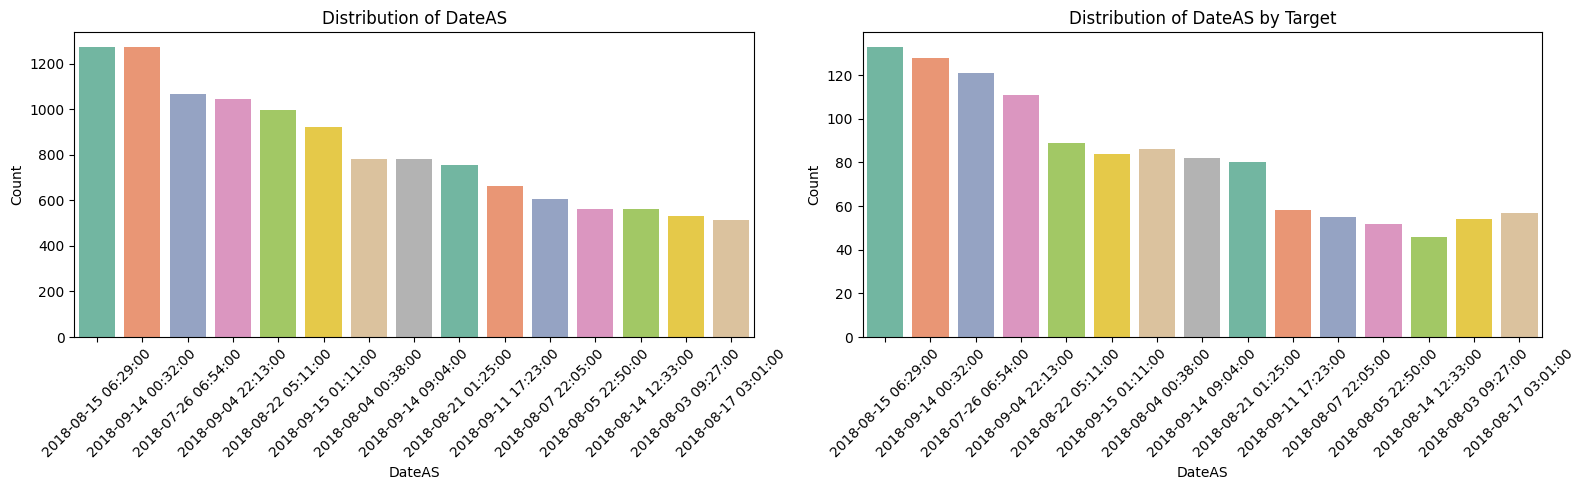

col


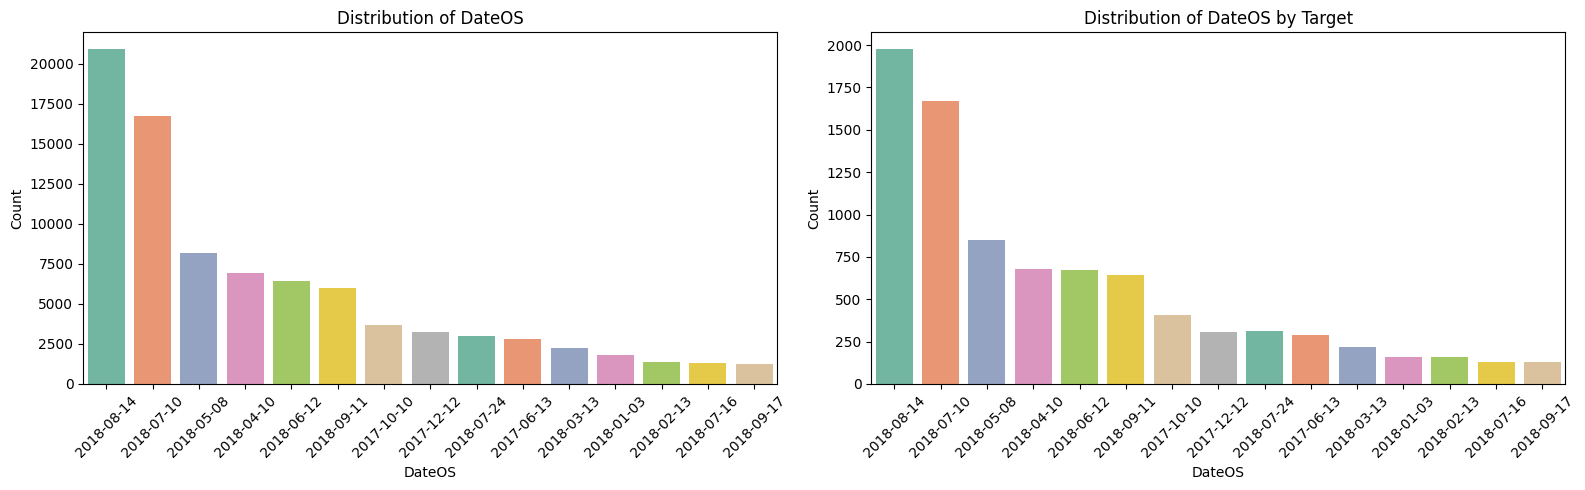

In [16]:
for col in cat_features: 
    print("col")
    fig, axes = plt.subplots(1, 2, figsize=(16, 5))
    top_categories = data[col].value_counts().index[:15]
    
    sns.countplot(data=data, x=col, order=top_categories, palette='Set2', ax=axes[0])
    axes[0].set_title(f"Distribution of {col}")
    axes[0].set_xlabel(col)
    axes[0].set_ylabel("Count")
    axes[0].tick_params(axis='x', rotation=45)
    
    sns.countplot(data=test_data, x=col , order=top_categories, palette='Set2', ax=axes[1])
    axes[1].set_title(f"Distribution of {col} by Target")
    axes[1].set_xlabel(col)
    axes[1].set_ylabel("Count")
    axes[1].tick_params(axis='x', rotation=45)
    
    plt.tight_layout()
    plt.show()

### it seems the test data and data has similar distribution only. YAYYY!!!

### Proportional Distribution

<Figure size 800x400 with 0 Axes>

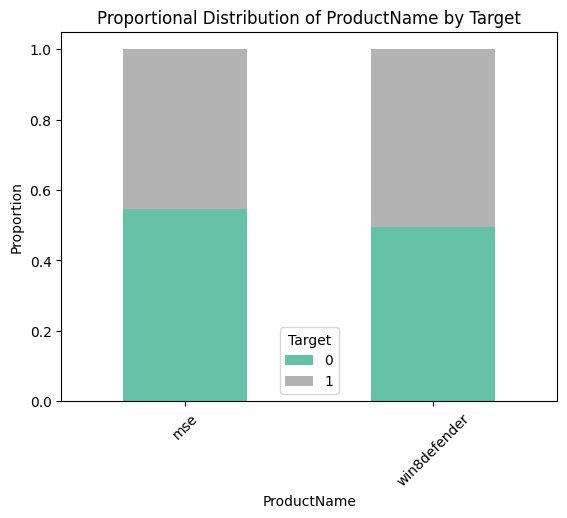

<Figure size 800x400 with 0 Axes>

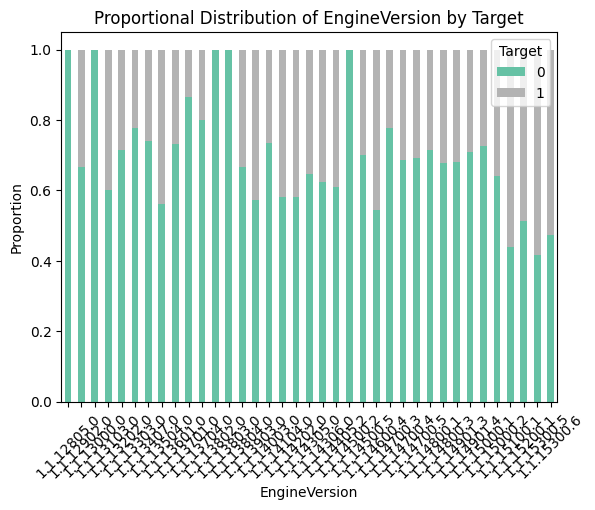

<Figure size 800x400 with 0 Axes>

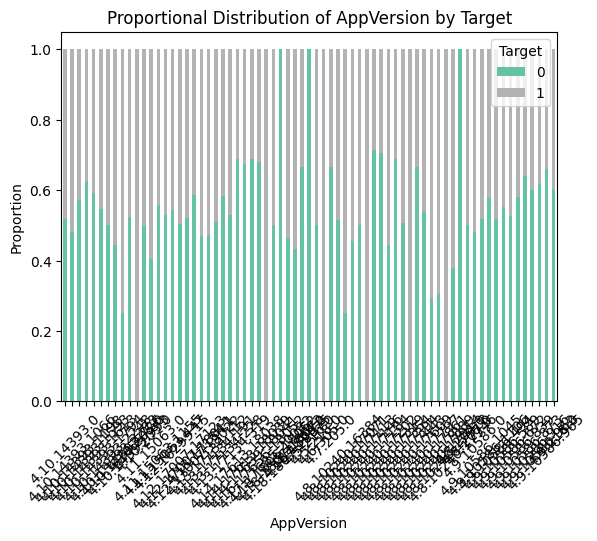

<Figure size 800x400 with 0 Axes>

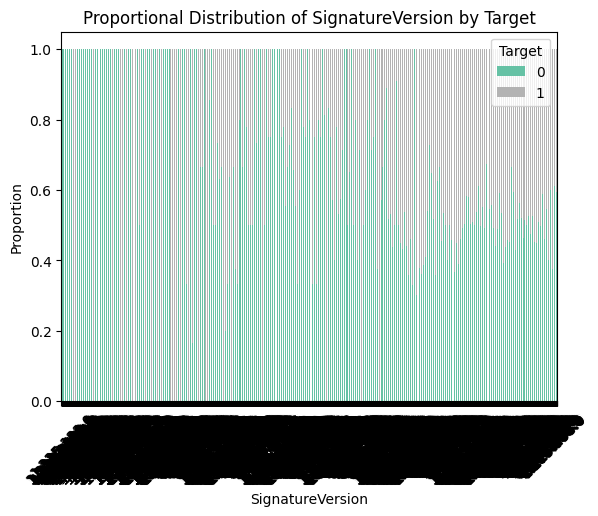

<Figure size 800x400 with 0 Axes>

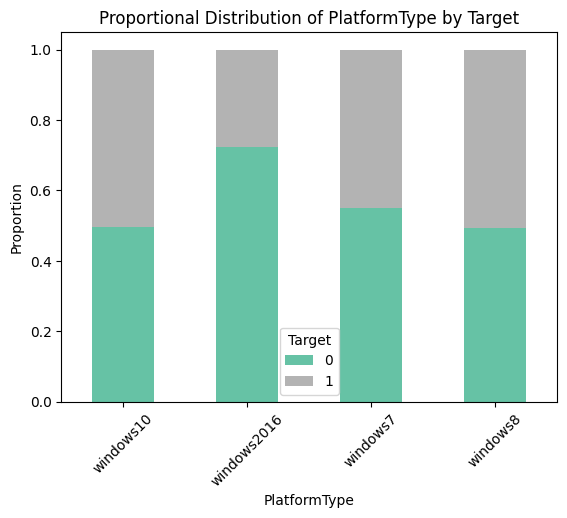

<Figure size 800x400 with 0 Axes>

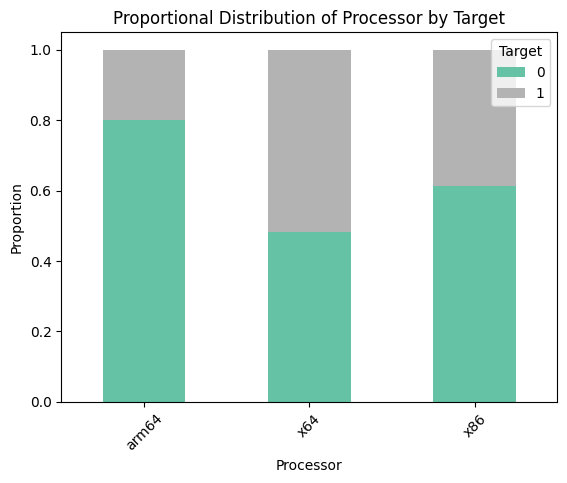

<Figure size 800x400 with 0 Axes>

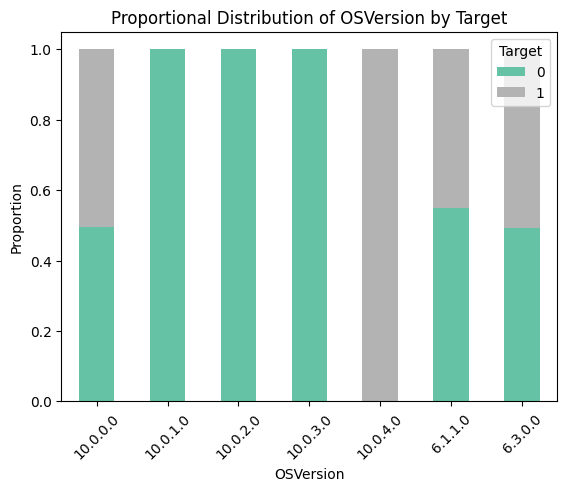

<Figure size 800x400 with 0 Axes>

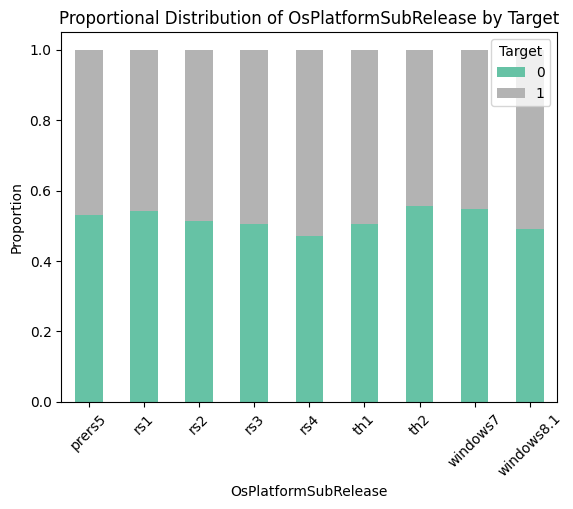

<Figure size 800x400 with 0 Axes>

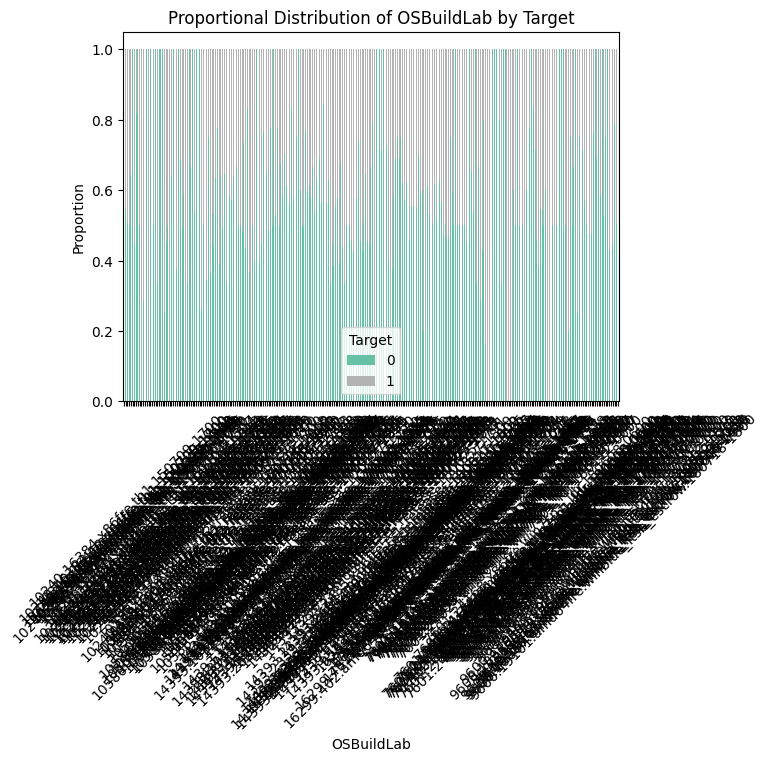

<Figure size 800x400 with 0 Axes>

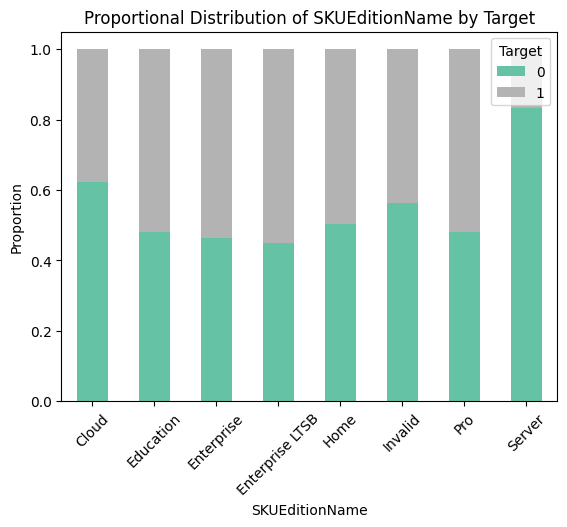

<Figure size 800x400 with 0 Axes>

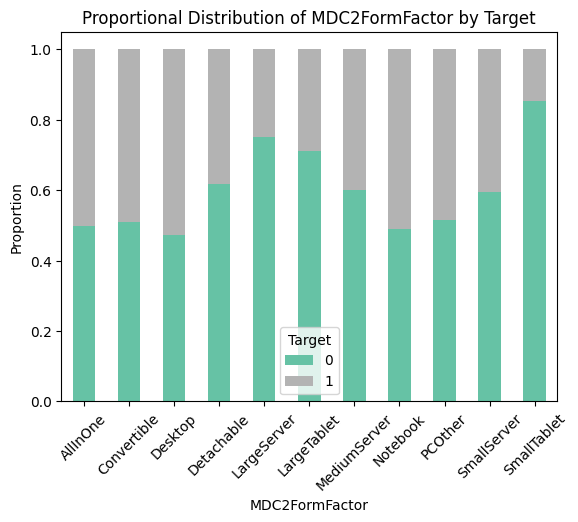

<Figure size 800x400 with 0 Axes>

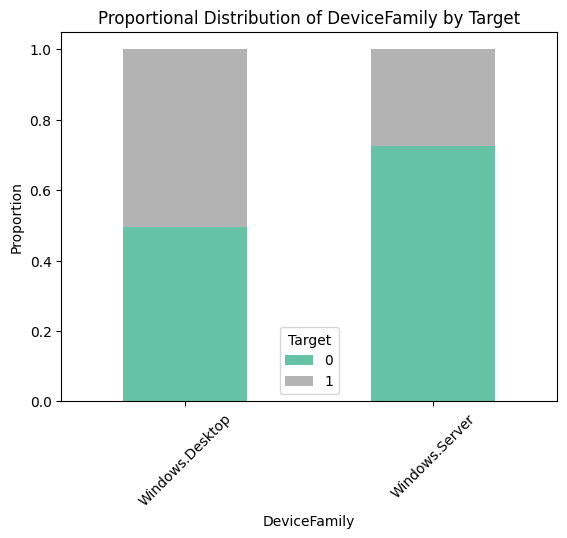

<Figure size 800x400 with 0 Axes>

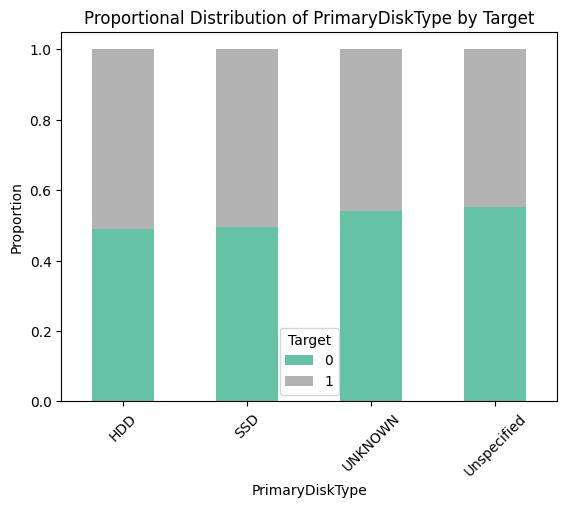

<Figure size 800x400 with 0 Axes>

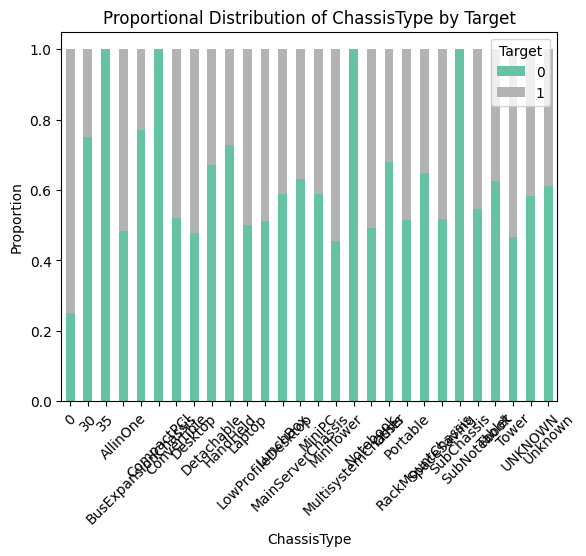

<Figure size 800x400 with 0 Axes>

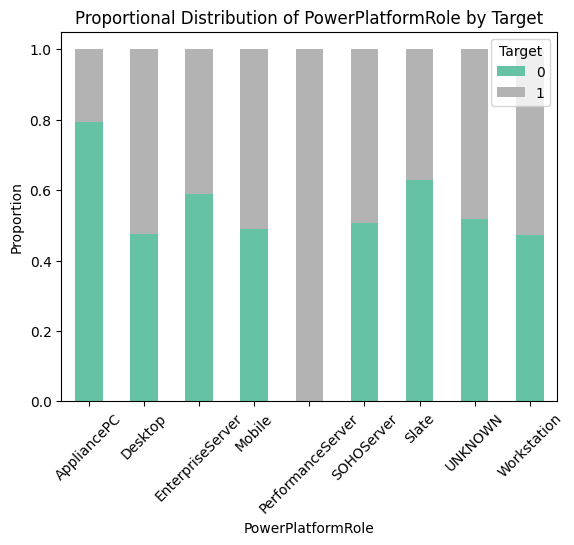

<Figure size 800x400 with 0 Axes>

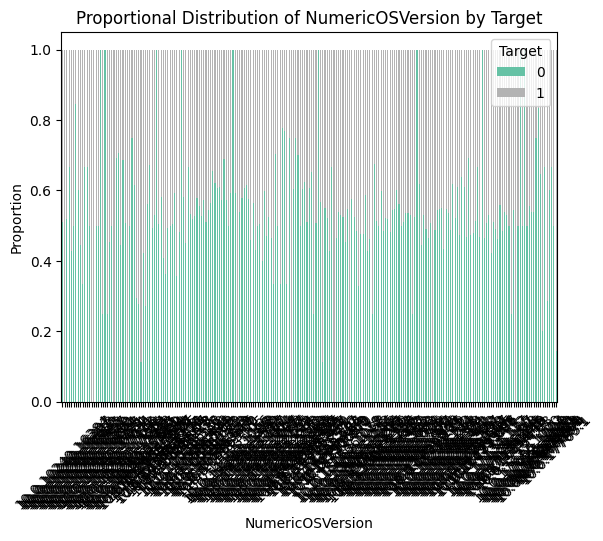

<Figure size 800x400 with 0 Axes>

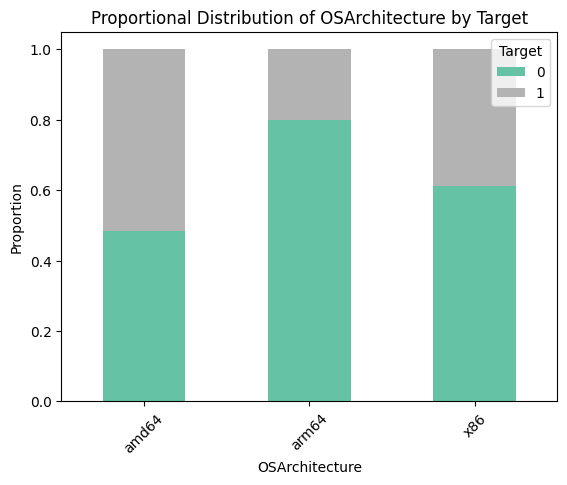

<Figure size 800x400 with 0 Axes>

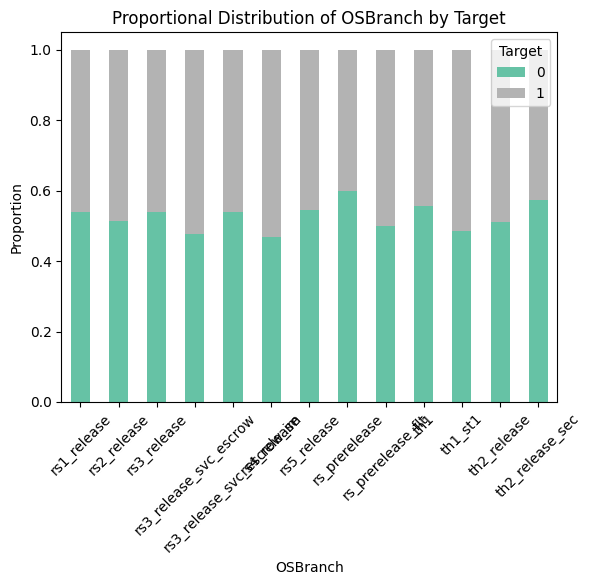

<Figure size 800x400 with 0 Axes>

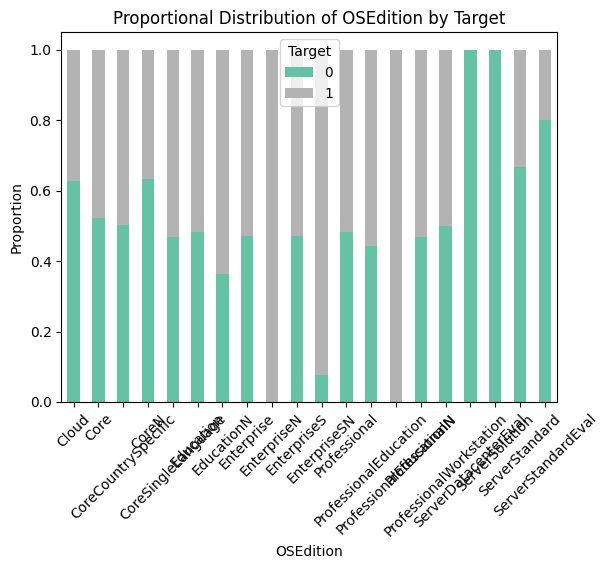

<Figure size 800x400 with 0 Axes>

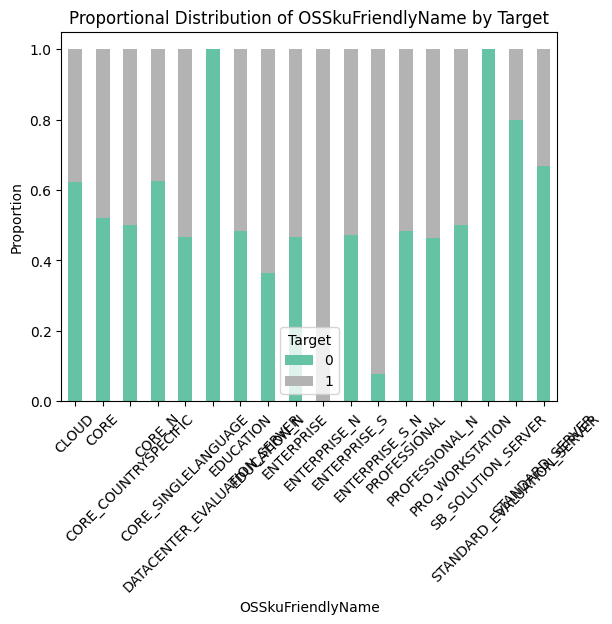

<Figure size 800x400 with 0 Axes>

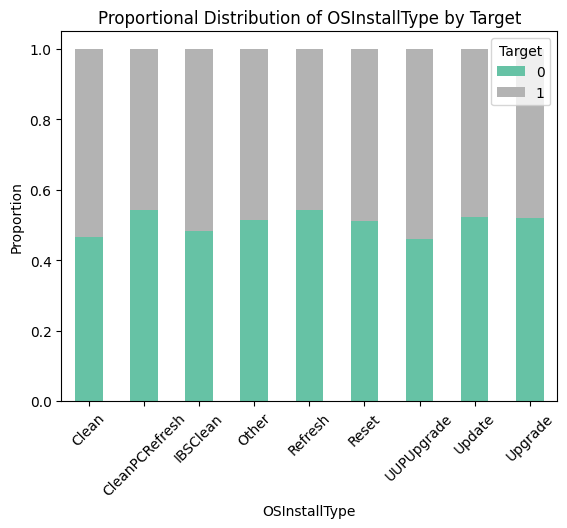

<Figure size 800x400 with 0 Axes>

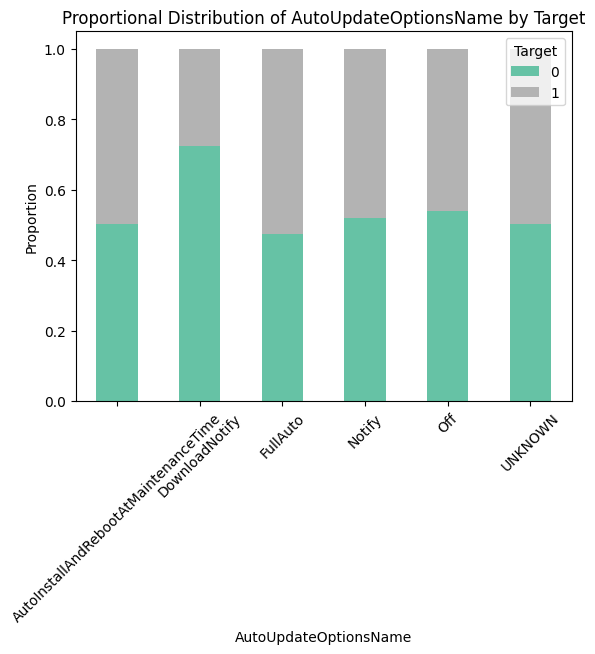

<Figure size 800x400 with 0 Axes>

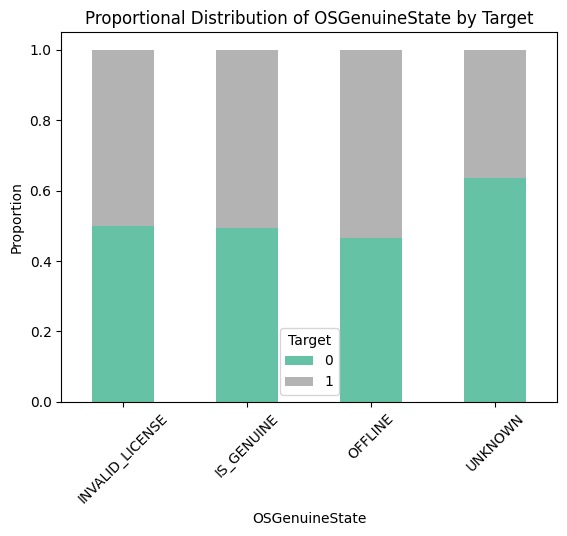

<Figure size 800x400 with 0 Axes>

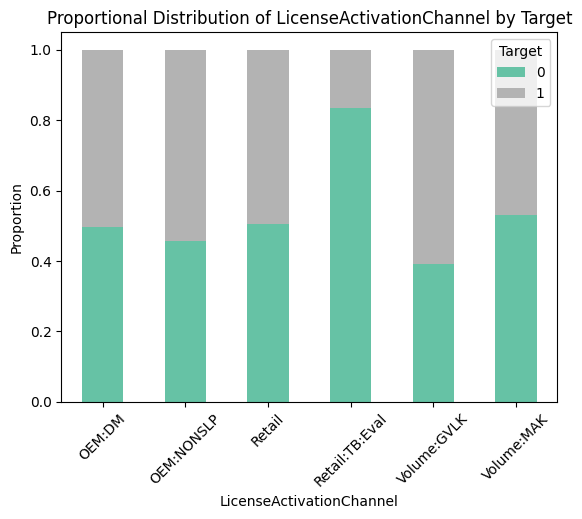

<Figure size 800x400 with 0 Axes>

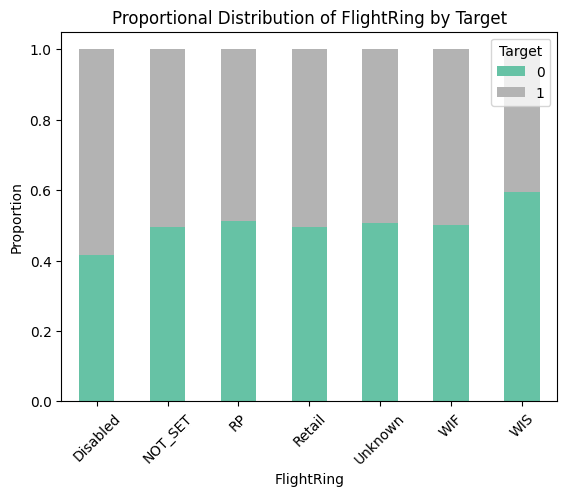

<Figure size 800x400 with 0 Axes>

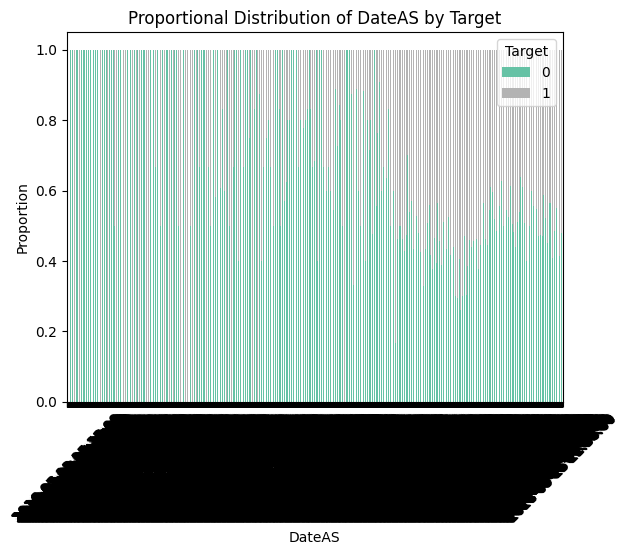

<Figure size 800x400 with 0 Axes>

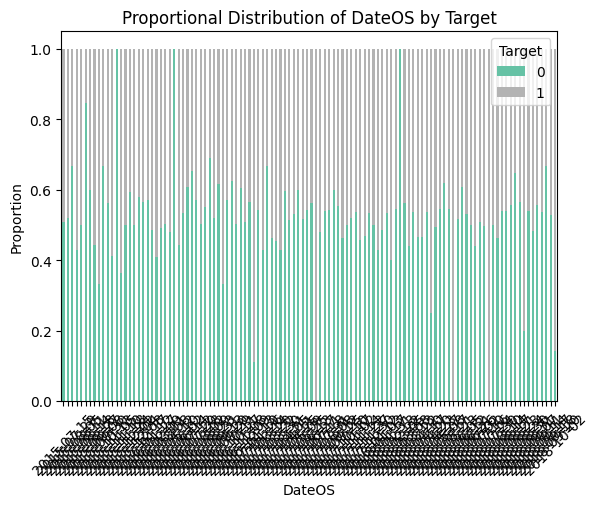

In [17]:
import pandas as pd
for col in cat_features:
    plt.figure(figsize=(8, 4))
    cat_counts = data.groupby([col, 'target']).size().unstack()
    cat_counts.div(cat_counts.sum(axis=1), axis=0).plot(kind="bar", stacked=True, colormap="Set2")
    plt.title(f"Proportional Distribution of {col} by Target")
    plt.xlabel(col)
    plt.ylabel("Proportion")
    plt.legend(title="Target")
    plt.xticks(rotation=45)
    plt.show()


###  Chi-Square Test for Categorical Variables to test their significance

In [18]:
from scipy.stats import chi2_contingency
alpha=0.05
significant_features = []
for col in cat_features:
    contingency_table = pd.crosstab(data[col], data['target'])
    chi2, p, dof, expected = chi2_contingency(contingency_table)      
    if p < alpha:
        significant_features.append({'column': col, 'chi2': round(chi2,4), 'p_value': round(p,4), 'significant': True})
    else:
        significant_features.append({'column': col, 'chi2': round(chi2,4),'p_value': round(p,4), 'significant': False})
Significant_cat_features = pd.DataFrame(significant_features)
Significant_cat_features

,column,chi2,p_value,significant
0,ProductName,2.1972,0.1383,False
1,EngineVersion,1815.4480,0.0000,True
2,AppVersion,1434.3991,0.0000,True
3,SignatureVersion,4853.3481,0.0000,True
4,PlatformType,8.7911,0.0322,True
5,Processor,541.0713,0.0000,True
6,OSVersion,7.7457,0.2573,False
7,OsPlatformSubRelease,260.6077,0.0000,True
8,OSBuildLab,1156.2537,0.0000,True
9,SKUEditionName,53.2974,0.0000,True


### Which features are significant and which features are not??

In [19]:
Insignificant_Features = Significant_cat_features[Significant_cat_features['significant']==False]["column"].tolist()
cat_significant_Features = Significant_cat_features[Significant_cat_features['significant']==True]["column"].tolist()
Insignificant_Features

['ProductName', 'OSVersion', 'FlightRing']

# Insights gained from analyzing the features

# Analyzing Numerical Data 

In [20]:
num_features= data.select_dtypes(exclude=["object"])

num_features=num_features.drop(columns=["target"],axis=1)

num_features

,IsBetaUser,RealTimeProtectionState,IsPassiveModeEnabled,AntivirusConfigID,NumAntivirusProductsInstalled,NumAntivirusProductsEnabled,HasTpm,CountryID,CityID,GeoRegionID,...,IsFlightsDisabled,FirmwareManufacturerID,FirmwareVersionID,IsSecureBootEnabled,IsVirtualDevice,IsTouchEnabled,IsPenCapable,IsAlwaysOnAlwaysConnectedCapable,IsGamer,RegionIdentifier
0,0,7.0,0,53447.0,1.0,1.0,1,51,120232.0,98.0,...,0.0,513.0,21964.0,0,0.0,1,0,1.0,0.0,6.0
1,0,7.0,0,53447.0,1.0,1.0,1,141,112854.0,167.0,...,0.0,628.0,44548.0,1,0.0,0,0,0.0,0.0,10.0
2,0,7.0,0,53447.0,1.0,1.0,1,51,41759.0,98.0,...,0.0,142.0,9414.0,0,0.0,0,0,0.0,1.0,6.0
3,0,7.0,0,46413.0,2.0,1.0,1,68,19507.0,276.0,...,0.0,554.0,33060.0,1,0.0,0,0,0.0,0.0,12.0
4,0,7.0,0,40466.0,2.0,1.0,1,43,117801.0,53.0,...,0.0,628.0,13224.0,0,0.0,0,0,0.0,1.0,7.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,0,7.0,0,68585.0,2.0,1.0,1,43,71228.0,53.0,...,0.0,142.0,25740.0,0,0.0,0,0,0.0,1.0,7.0
99996,0,7.0,0,11280.0,2.0,1.0,1,137,137066.0,160.0,...,0.0,355.0,20900.0,0,0.0,0,0,0.0,0.0,3.0
99997,0,7.0,0,53447.0,1.0,1.0,1,142,74924.0,157.0,...,0.0,486.0,51605.0,1,0.0,0,0,0.0,1.0,1.0
99998,0,7.0,0,53447.0,1.0,1.0,1,139,87570.0,158.0,...,0.0,677.0,18669.0,1,0.0,1,1,1.0,0.0,1.0


### Looks there are some zero variance features

In [21]:
from sklearn.feature_selection import VarianceThreshold
selector = VarianceThreshold()
selected_features = selector.fit_transform(num_features)
feature_mask = selector.get_support()
keep_features = num_features.columns[feature_mask]
remove_features = num_features.columns[~feature_mask]
print("Removed Features:", remove_features.tolist())
num_features=num_features.drop(columns=remove_features,axis=1)

Removed Features: ['IsBetaUser', 'AutoSampleSubmissionEnabled', 'IsFlightsDisabled']


# What I want from each Numerical Variable? 
*    Unique values,
*    Number of unique values
*    Count including NaN
*    Count excluding NaN
*    Number of missing values
*    Percentage to missing values.
Create a Dataframe to for all of this

In [22]:
num_stats = pd.DataFrame([
    {
        'Name': n,
        'values': num_features[n].unique(),
        'values_count_in': num_features[n].nunique(dropna=False), 
        'values_count_ex': num_features[n].nunique(), 
        'miss_values': num_features[n].isna().sum(),  
        '%_miss': round(num_features[n].isna().mean() * 100, 3),
             

    }
    for n in num_features.columns
])
num_stats = num_stats.sort_values(by='values_count_in',ignore_index=True)
num_stats

,Name,values,values_count_in,values_count_ex,miss_values,%_miss
0,IsSecureBootEnabled,"[0, 1]",2,2,0,0.000
1,IsPassiveModeEnabled,"[0, 1]",2,2,0,0.000
2,HasTpm,"[1, 0]",2,2,0,0.000
3,IsPenCapable,"[0, 1]",2,2,0,0.000
4,IsTouchEnabled,"[1, 0]",2,2,0,0.000
5,IsPortableOS,"[0, 1]",2,2,0,0.000
6,HasOpticalDiskDrive,"[0, 1]",2,2,0,0.000
7,IsAlwaysOnAlwaysConnectedCapable,"[1.0, 0.0, nan]",3,2,134,0.134
8,FirewallEnabled,"[1.0, 0.0, nan]",3,2,166,0.166
9,IsVirtualDevice,"[0.0, 1.0, nan]",3,2,20,0.020


### Which all feature has null values and how much??

In [23]:
num_stats.sort_values(by = '%_miss', ascending = False).head(35)

,Name,values,values_count_in,values_count_ex,miss_values,%_miss
12,SMode,"[0.0, nan, 1.0]",3,2,981,0.981
42,CityID,"[120232.0, 112854.0, 41759.0, 19507.0, 117801....",16048,16047,623,0.623
19,RegionIdentifier,"[6.0, 10.0, 12.0, 7.0, 4.0, 11.0, 1.0, 15.0, 3...",16,15,559,0.559
10,IsGamer,"[0.0, 1.0, nan]",3,2,559,0.559
38,InternalBatteryNumberOfCharges,"[142.0, 4294967295.0, 0.0, 28.0, 94.0, 432.0, ...",1761,1760,515,0.515
29,FirmwareManufacturerID,"[513.0, 628.0, 142.0, 554.0, 355.0, 127.0, 556...",170,169,376,0.376
40,FirmwareVersionID,"[21964.0, 44548.0, 9414.0, 33060.0, 13224.0, 2...",12300,12299,334,0.334
41,OEMModelID,"[330367.0, 25212.0, 263666.0, 242491.0, 257309...",15953,15952,228,0.228
36,OEMNameID,"[561.0, 2668.0, 3035.0, 2102.0, 1443.0, 4589.0...",838,837,212,0.212
8,FirewallEnabled,"[1.0, 0.0, nan]",3,2,166,0.166


# OMG!!! Though some are numerical features they are generally ID's. Lets break them down

In [24]:
ID_num_stats = num_stats[num_stats['Name'].str.contains("ID")]
for c in ID_num_stats["Name"]:
    data[c]= data[c].astype(str)
id_num_list= ID_num_stats["Name"].tolist()
ID_num_stats


,Name,values,values_count_in,values_count_ex,miss_values,%_miss
14,ProcessorManufacturerID,"[5.0, 1.0, nan, 3.0, 10.0]",5,4,85,0.085
23,OSInstallLanguageID,"[5.0, 9.0, 7.0, 37.0, 8.0, 20.0, 4.0, 6.0, 10....",40,39,113,0.113
24,OSUILocaleID,"[26, 34, 30, 158, 31, 83, 24, 28, 35, 128, 109...",64,64,0,0.000
25,IEVersionID,"[98.0, 137.0, 108.0, 117.0, 76.0, 94.0, 333.0,...",103,102,107,0.107
29,FirmwareManufacturerID,"[513.0, 628.0, 142.0, 554.0, 355.0, 127.0, 556...",170,169,376,0.376
30,LocaleEnglishNameID,"[103, 227, 74, 42, 60, 75, 70, 134, 52, 107, 2...",185,185,0,0.000
32,CountryID,"[51, 141, 68, 43, 35, 91, 18, 158, 107, 53, 17...",220,220,0,0.000
33,GeoRegionID,"[98.0, 167.0, 276.0, 53.0, 45.0, 277.0, 202.0,...",239,239,0,0.000
36,OEMNameID,"[561.0, 2668.0, 3035.0, 2102.0, 1443.0, 4589.0...",838,837,212,0.212
37,ProcessorModelID,"[1850.0, 2407.0, 2719.0, 3410.0, 4322.0, 3616....",1660,1659,85,0.085


In [25]:
nonID_num_stats = num_stats[~num_stats['Name'].str.contains("ID")]
nonID_num_stats

,Name,values,values_count_in,values_count_ex,miss_values,%_miss
0,IsSecureBootEnabled,"[0, 1]",2,2,0,0.000
1,IsPassiveModeEnabled,"[0, 1]",2,2,0,0.000
2,HasTpm,"[1, 0]",2,2,0,0.000
3,IsPenCapable,"[0, 1]",2,2,0,0.000
4,IsTouchEnabled,"[1, 0]",2,2,0,0.000
5,IsPortableOS,"[0, 1]",2,2,0,0.000
6,HasOpticalDiskDrive,"[0, 1]",2,2,0,0.000
7,IsAlwaysOnAlwaysConnectedCapable,"[1.0, 0.0, nan]",3,2,134,0.134
8,FirewallEnabled,"[1.0, 0.0, nan]",3,2,166,0.166
9,IsVirtualDevice,"[0.0, 1.0, nan]",3,2,20,0.020


## !!! still there are some categorical features in the non_num_id 

## Final three segment of categorical features( binary, non_binary, categorical but given as numerical .
### they are: ["OSProductSuite","RegionIdentifier","RealTimeProtectionState","OSBuildNumber","OSBuildNumberOnly"]

In [26]:
id_num_feature = ID_num_stats["Name"].tolist()
cat_num_feature=id_num_feature+["OSProductSuite","RegionIdentifier","RealTimeProtectionState","OSBuildNumber","OSBuildNumberOnly"]

### Some columns are binary and some are not

given less than five because some features has np.nan and EnableLUA has an error category in it

In [27]:
binary_num_features= nonID_num_stats[nonID_num_stats["values_count_in"]<5]["Name"].tolist()
nonbinary_num_features =nonID_num_stats[nonID_num_stats["values_count_in"]>5]["Name"].tolist()



## Categorized Numerical Features list names:
* cat_num_feature
* binary_num_features
* nonbinary_num_features

INSIGHTS: OSbuild number and OSbuild number only are same, remove either one

features like regionalidentifier, RealTimeProtectionState ,OSProductSuite , osbuildnumber should also be categorical

convert resolution veritical and horizontal to a single feature and scale
convert mb to gb

#### Inference: These numerical values are very similar to categorical variable.   

## HeatMAP

In [28]:
num=binary_num_features+nonbinary_num_features

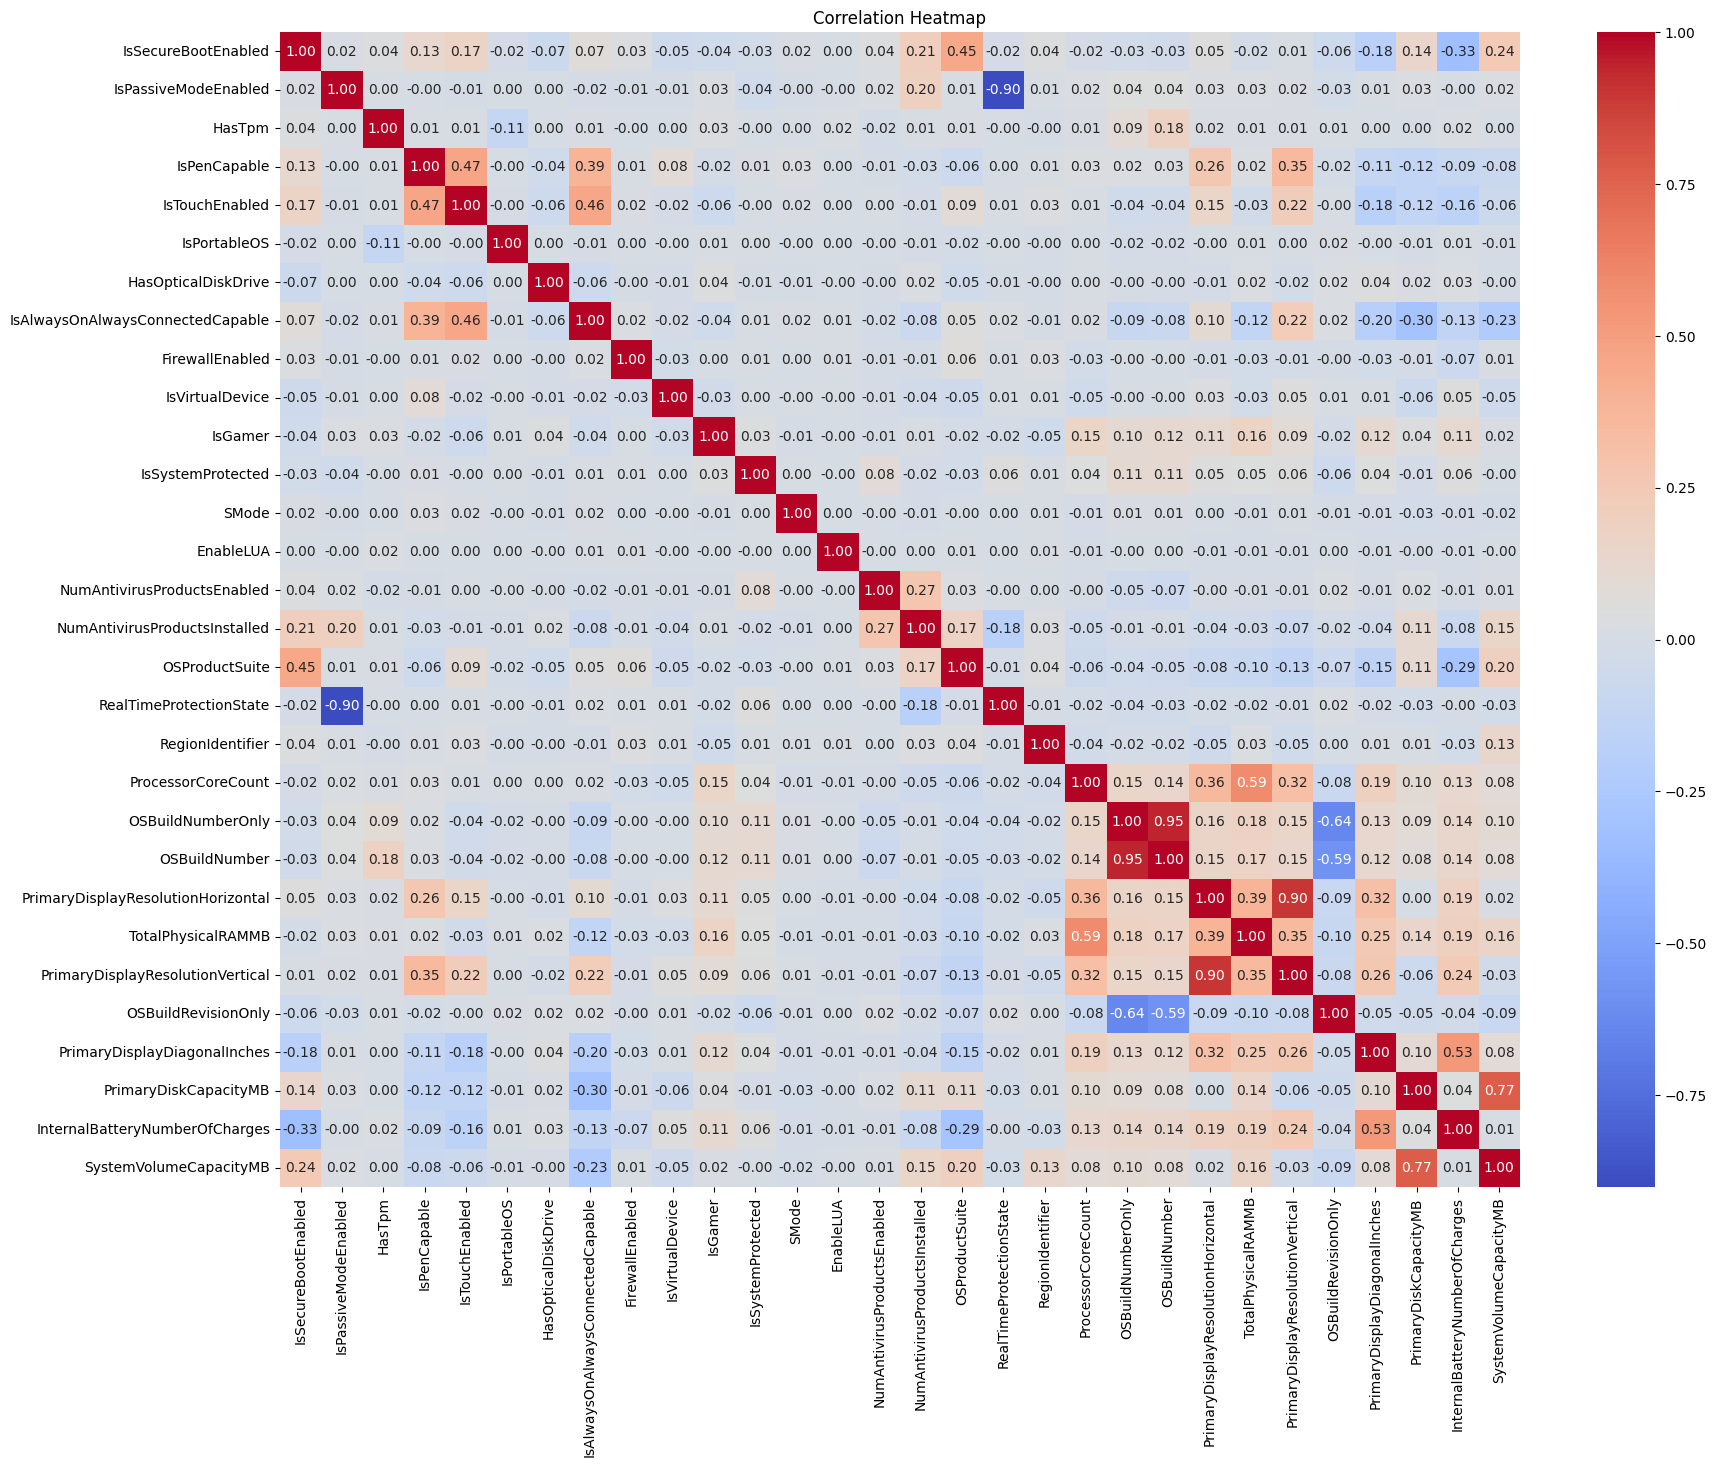

In [29]:

plt.figure(figsize=(20, 15))
sns.heatmap(data[num].corr(),annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()


### Highly coorelated features: 
#### * Buildnumber and buildnumber
#### * resolution horizontal and resolution vertical 
#### * Realtimetimeprotection state and ispassive enabled

### Histogram for train and test 

/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


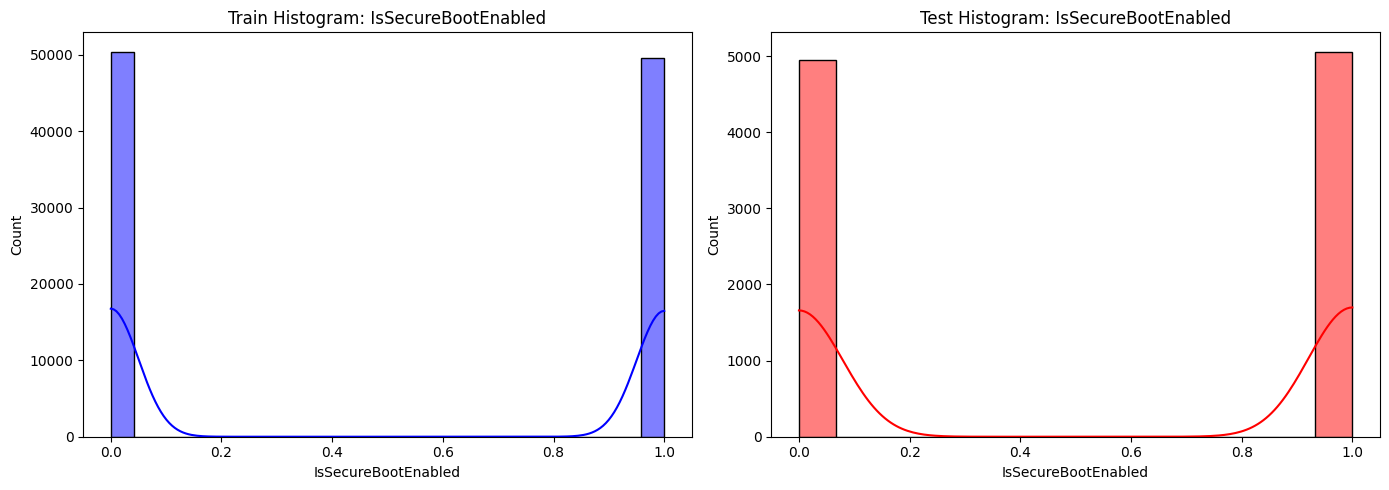

/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


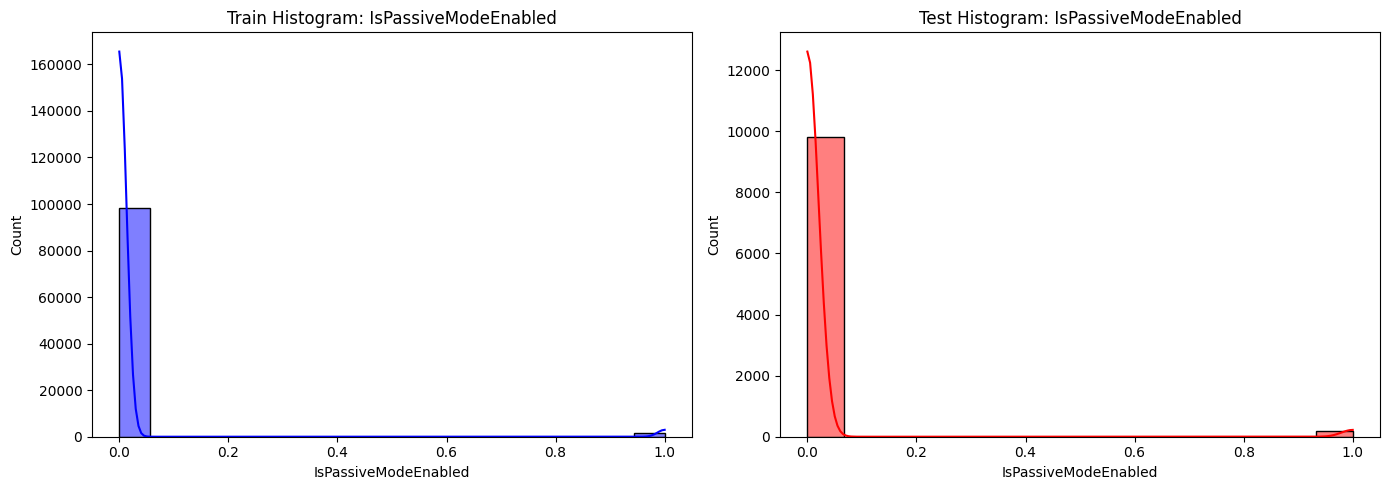

/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


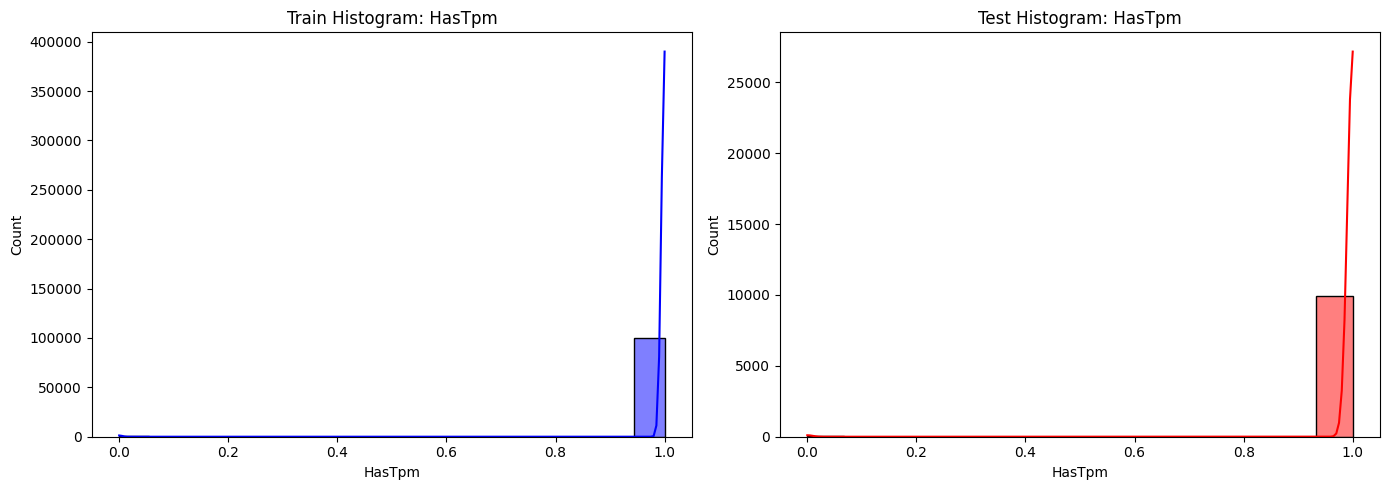

/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


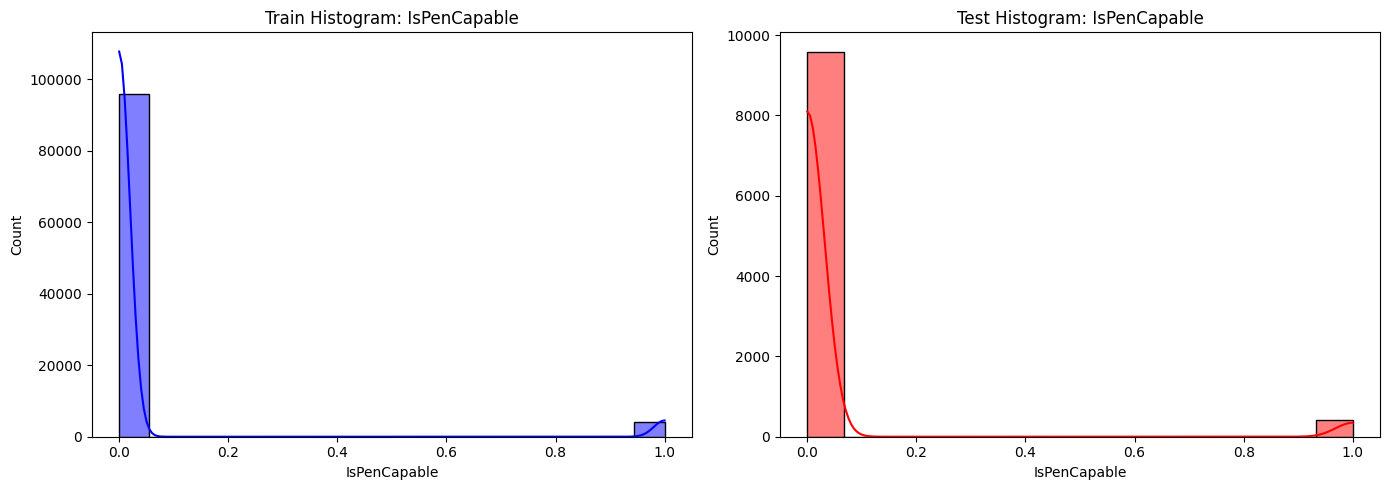

/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


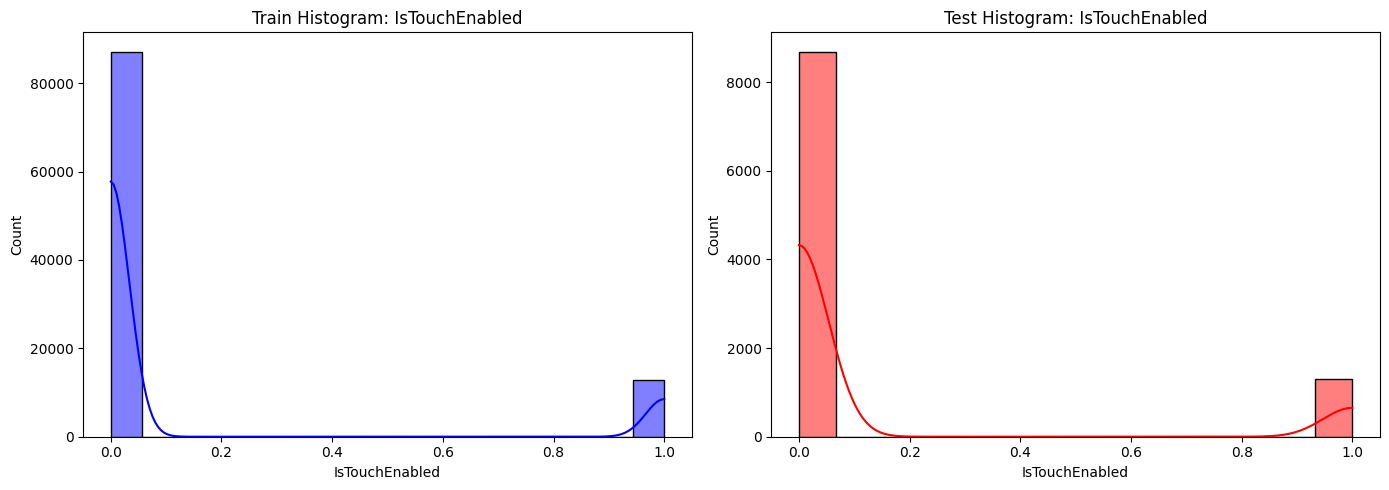

/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


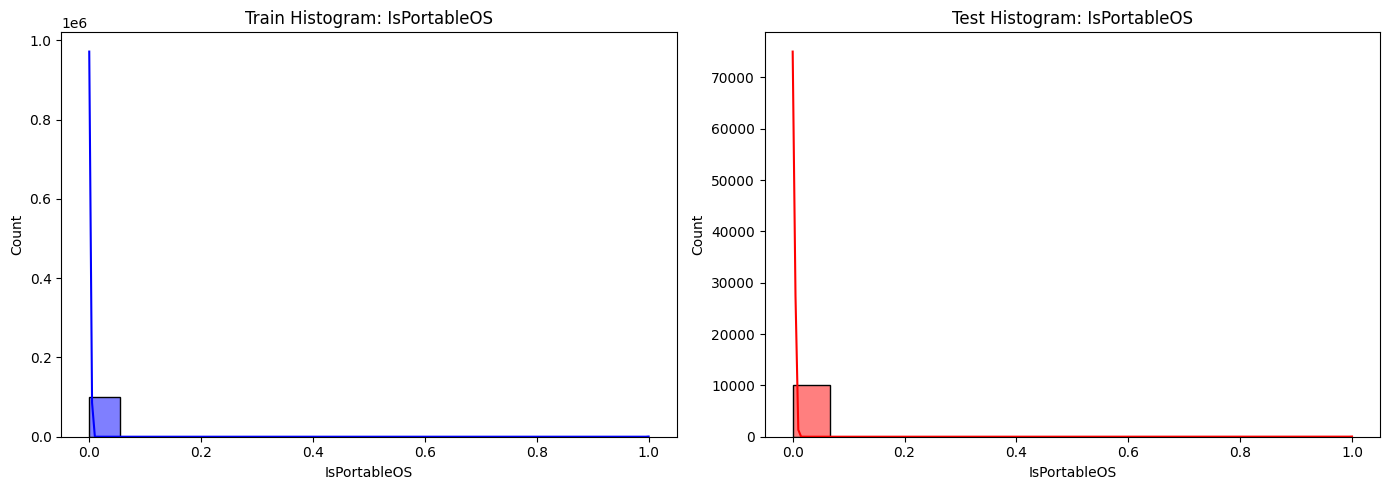

/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


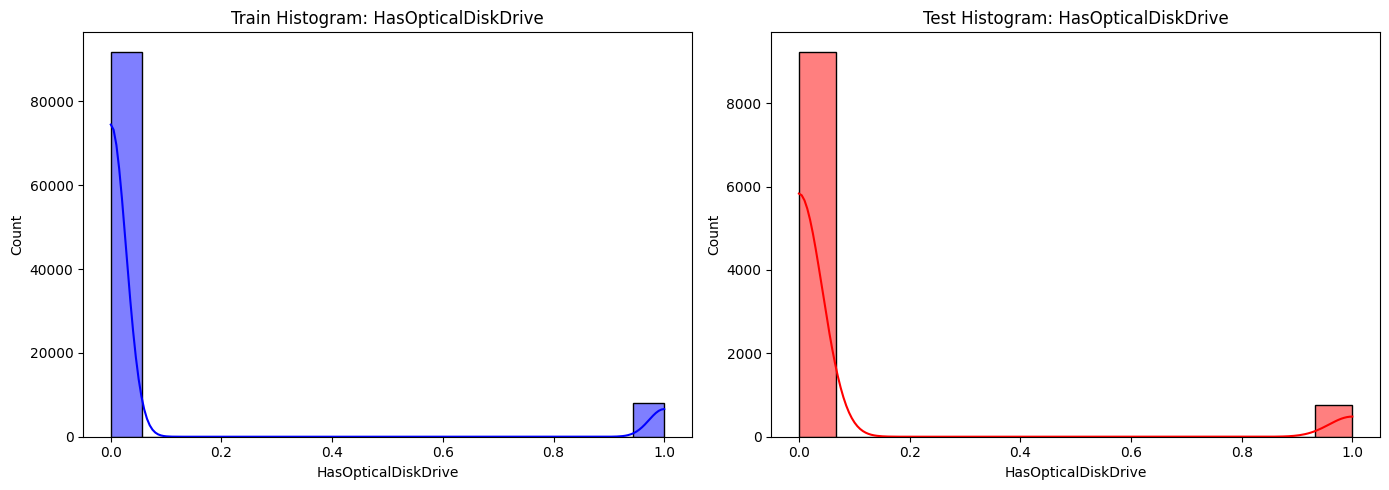

/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


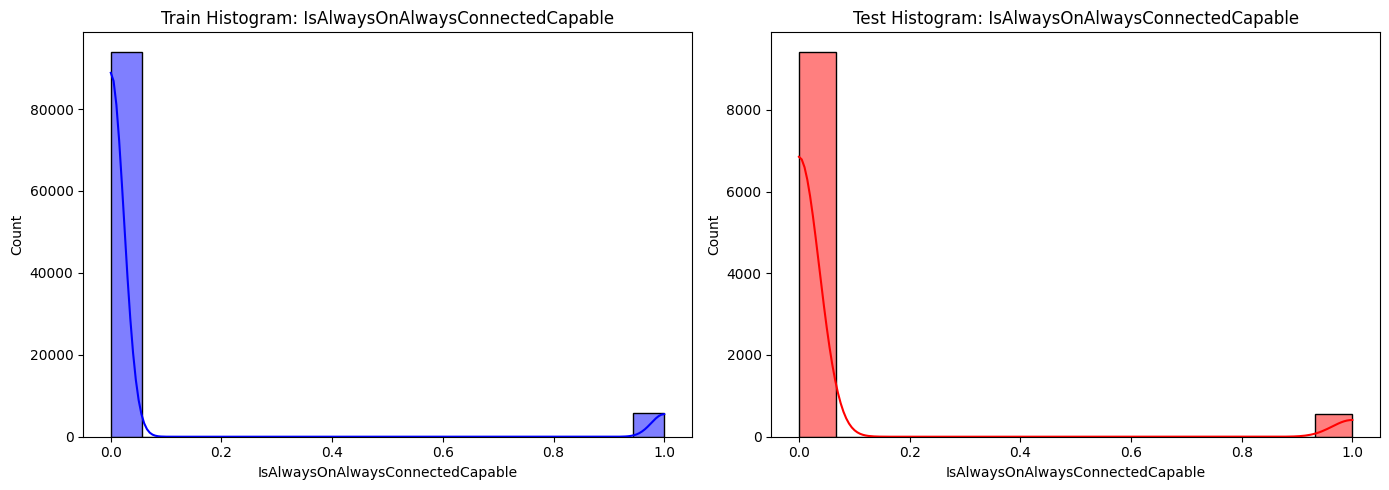

/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


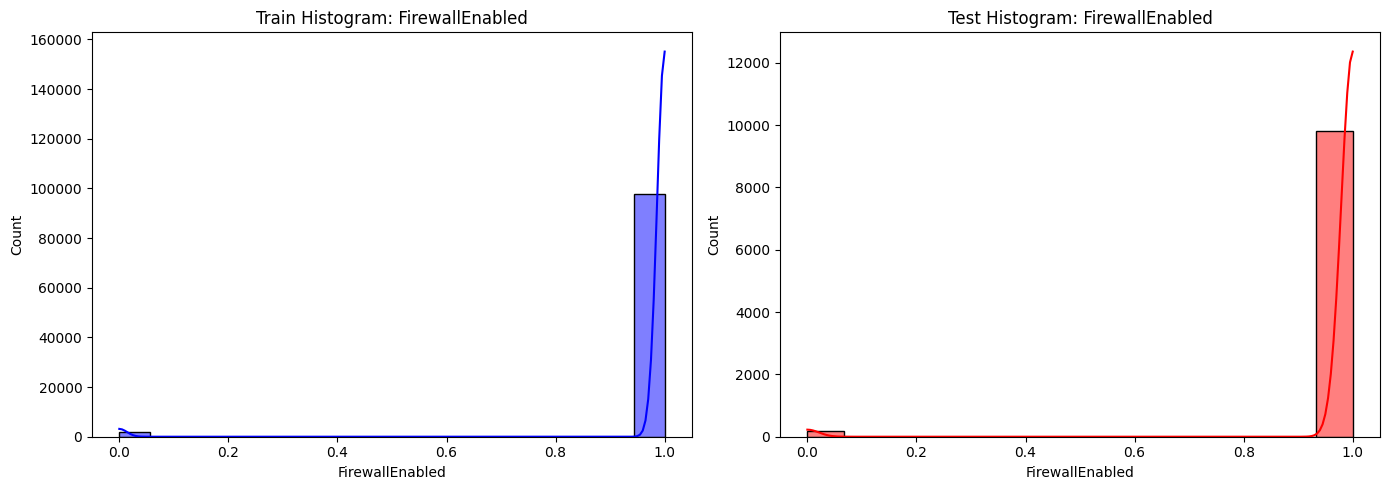

/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


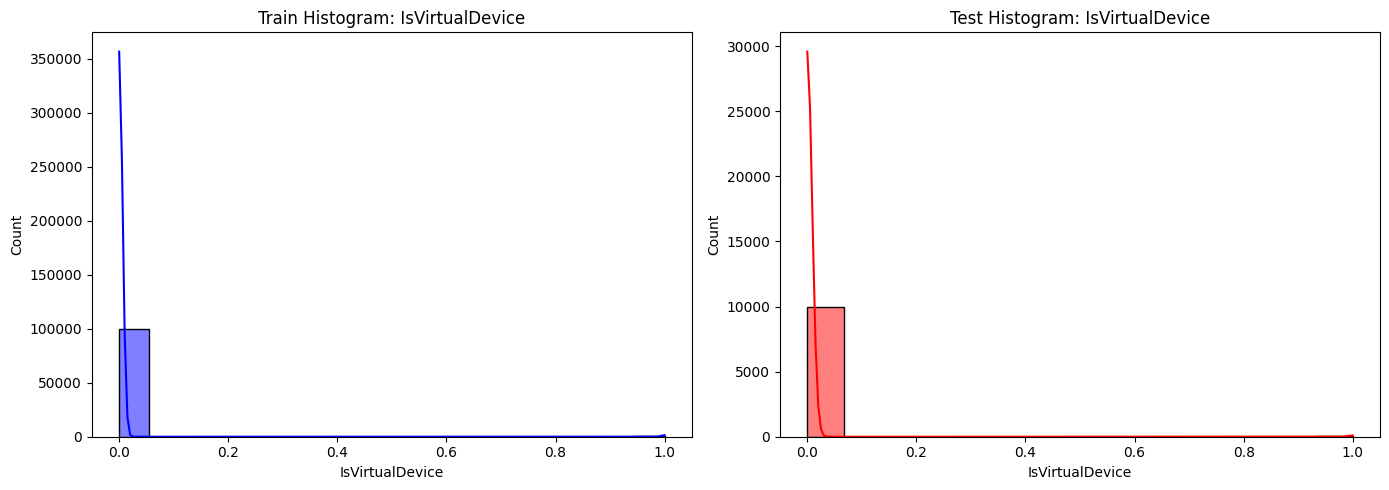

/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


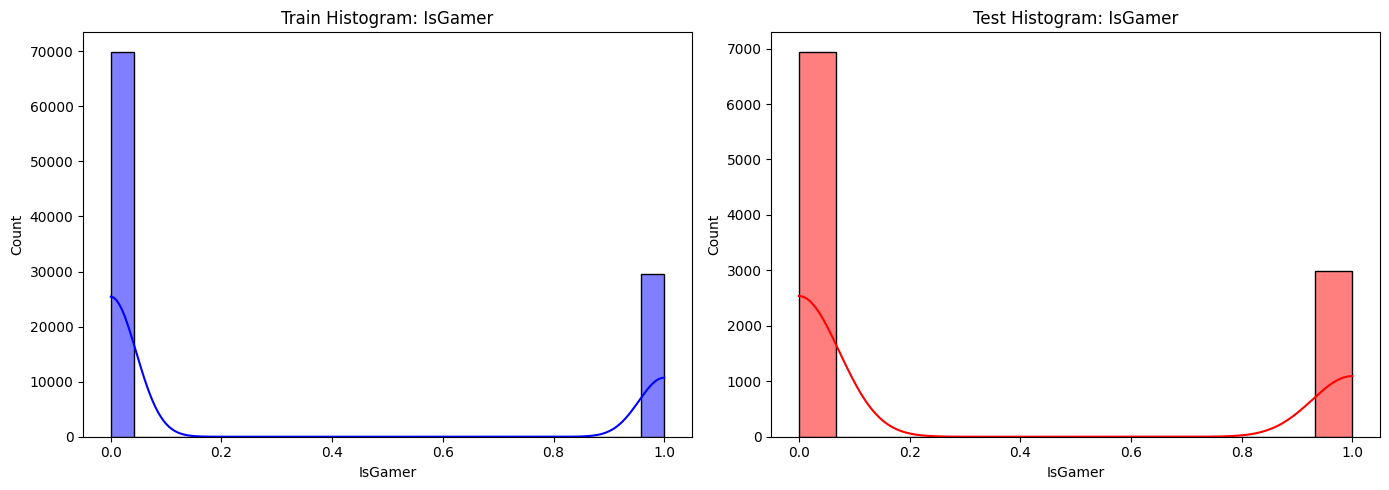

/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


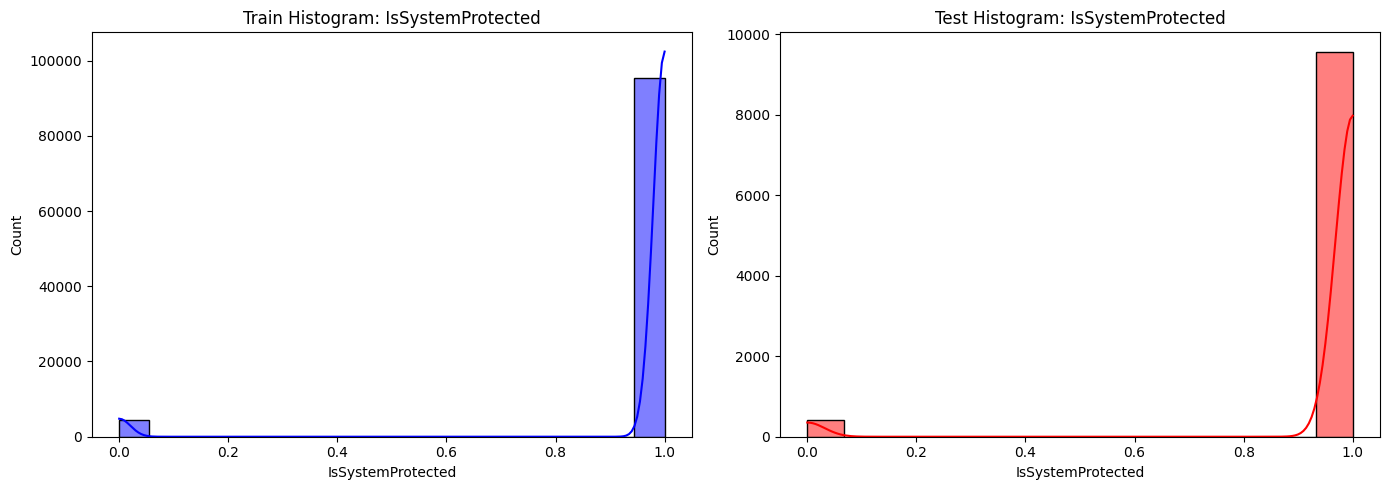

/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


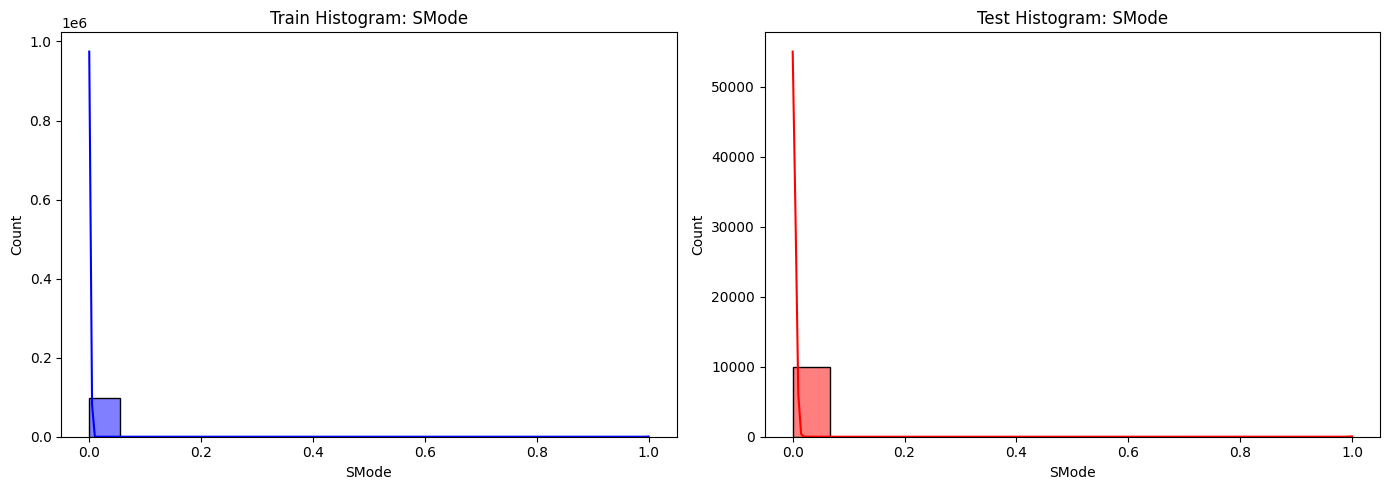

/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


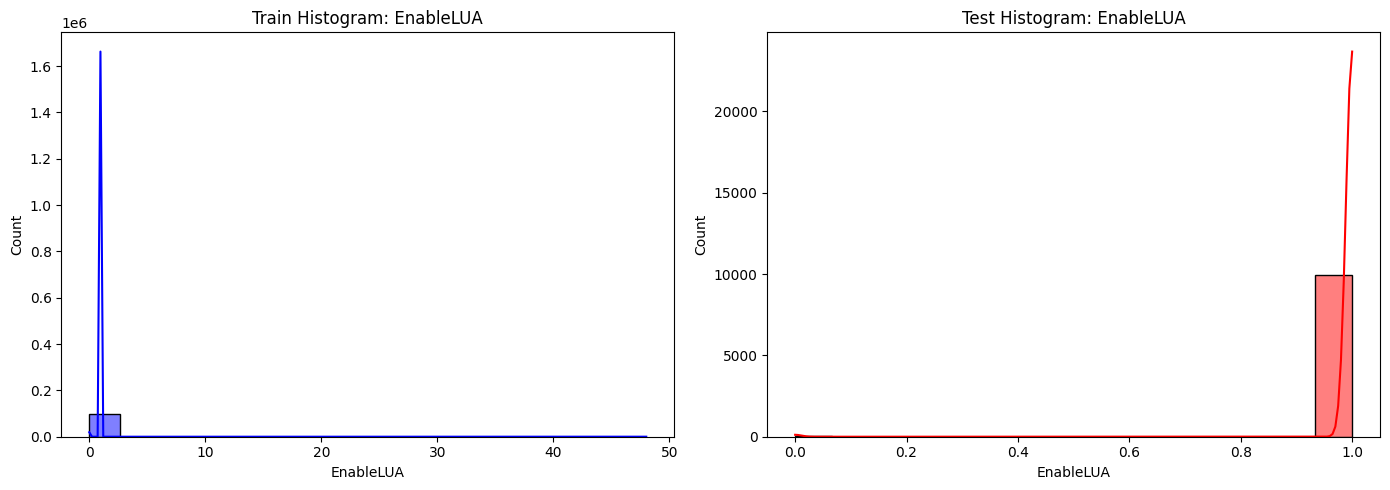

/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


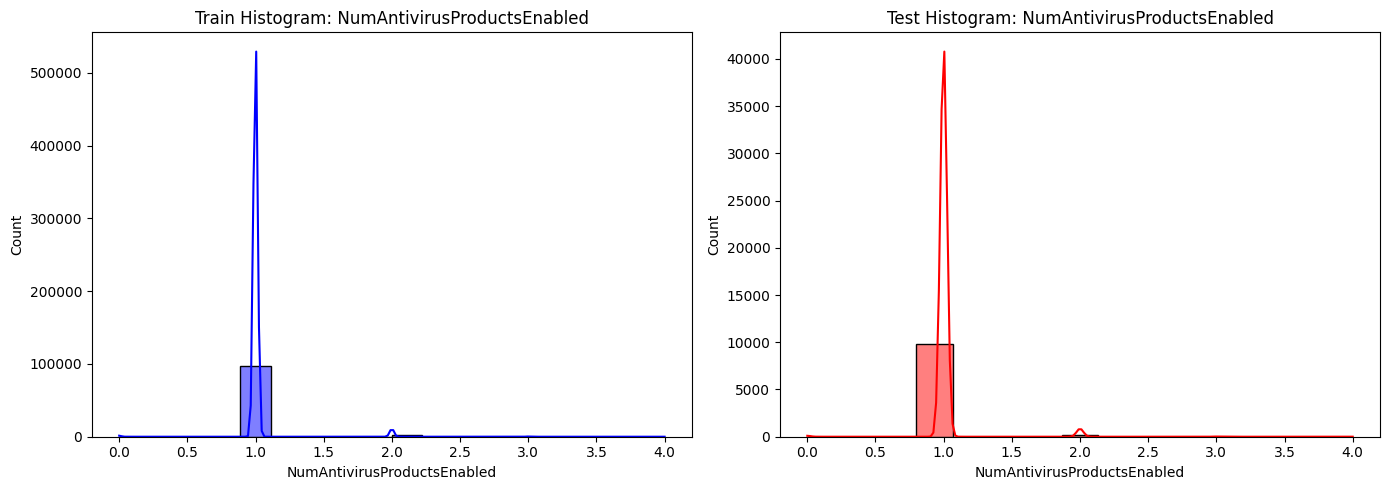

/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


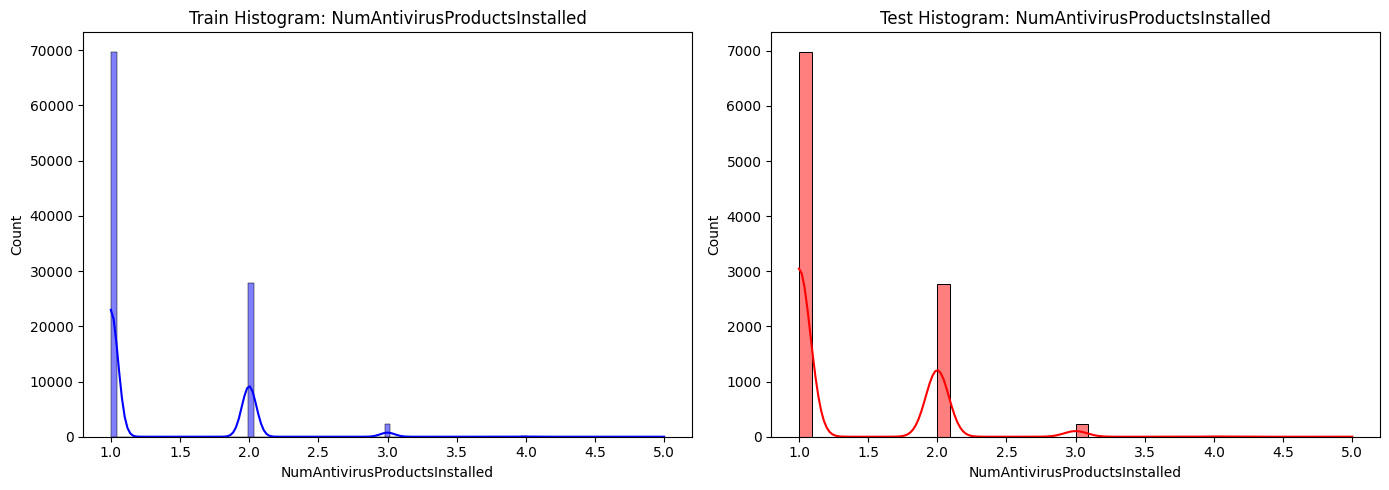

/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


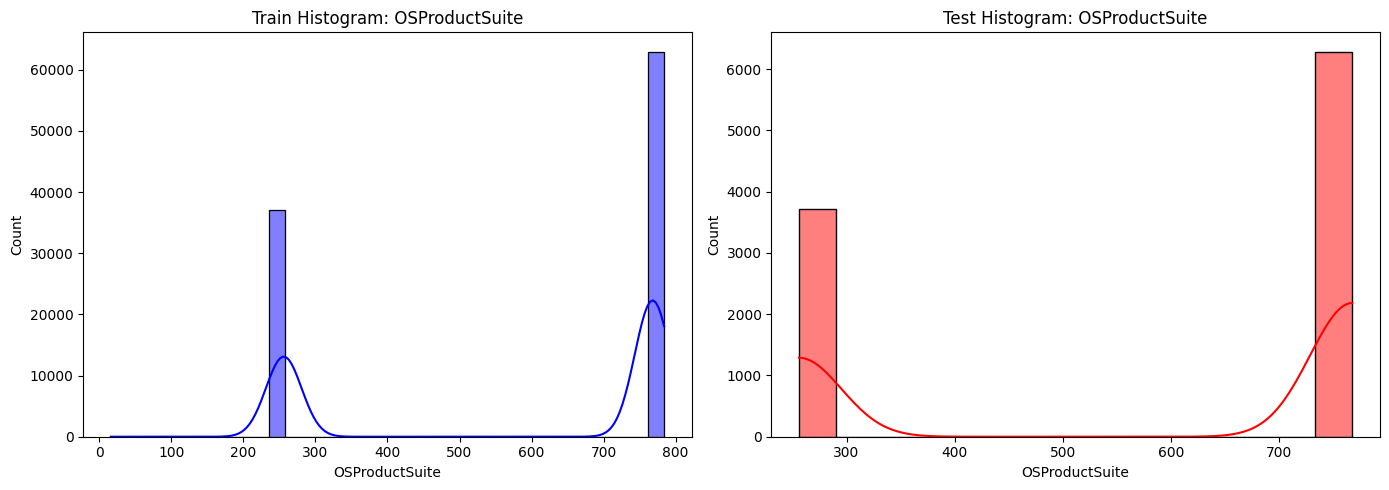

/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


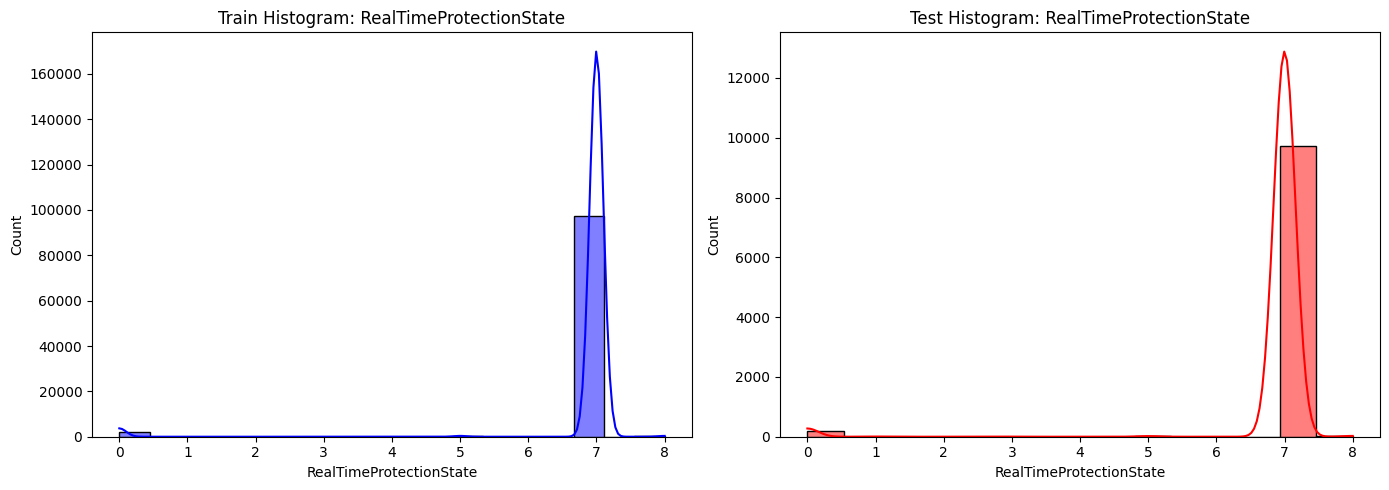

/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


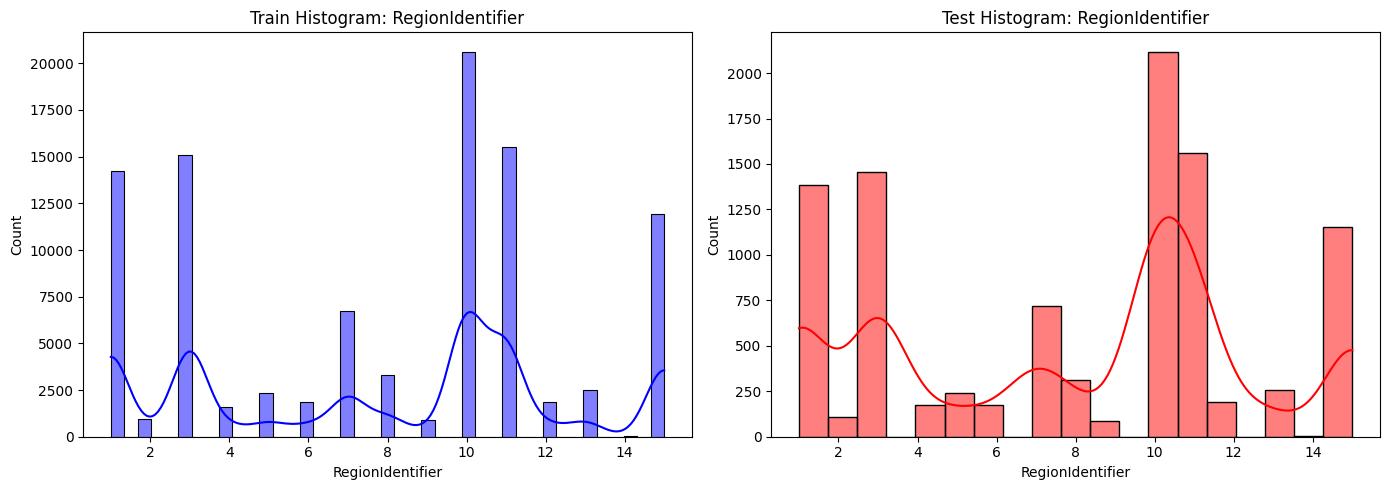

/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


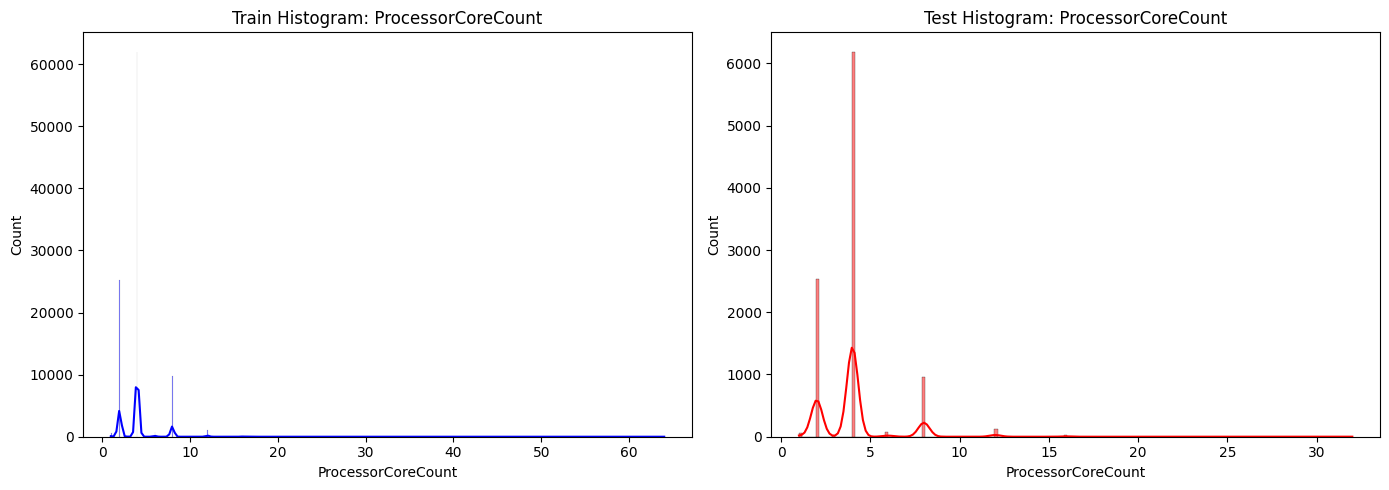

/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


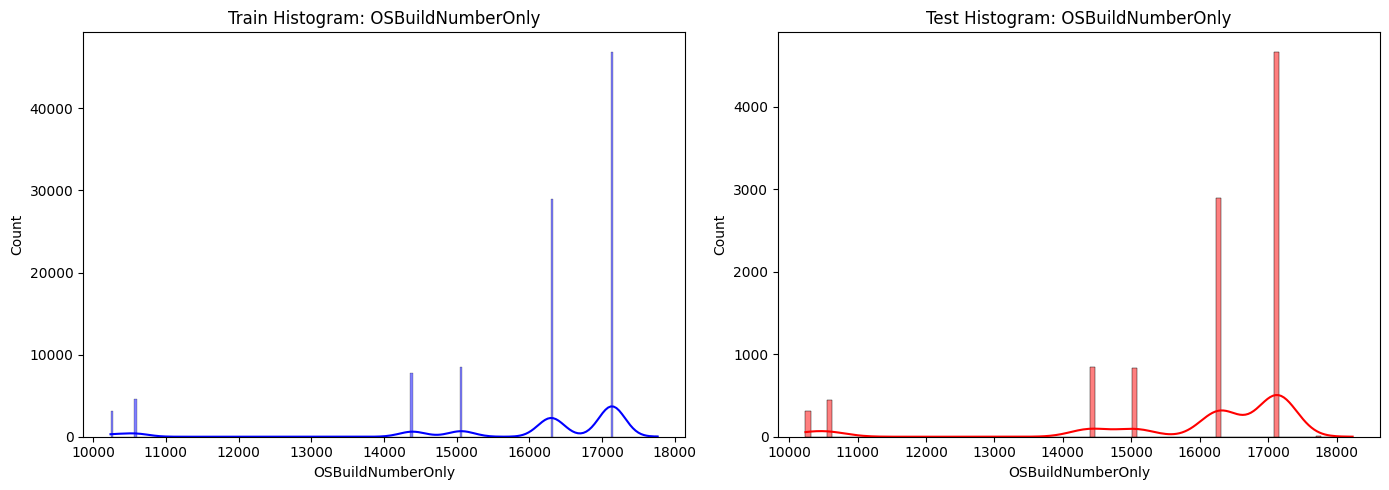

/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


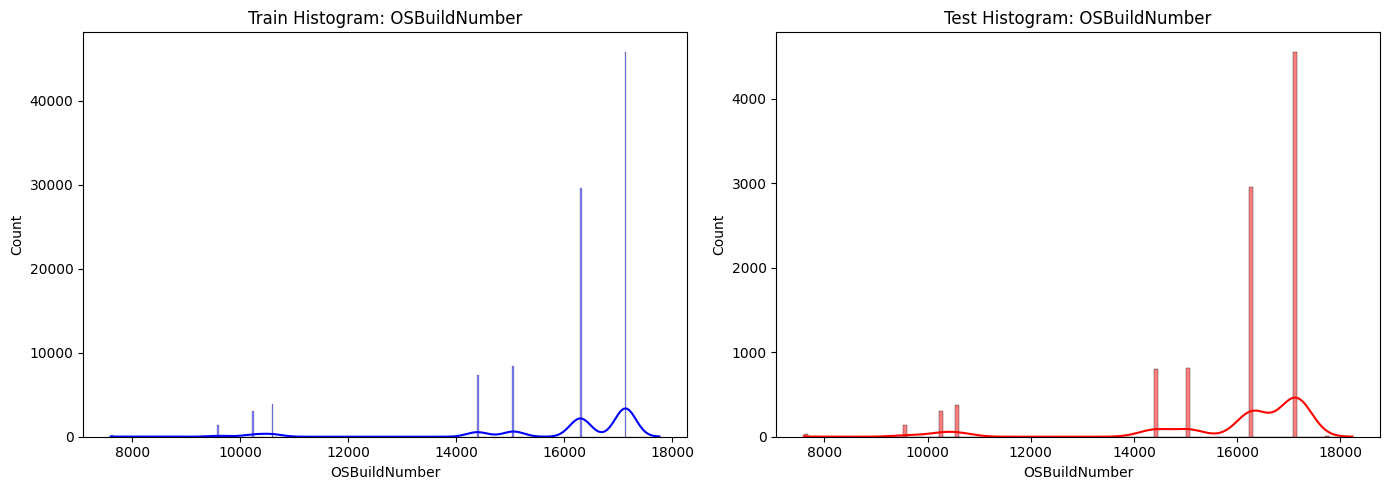

/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


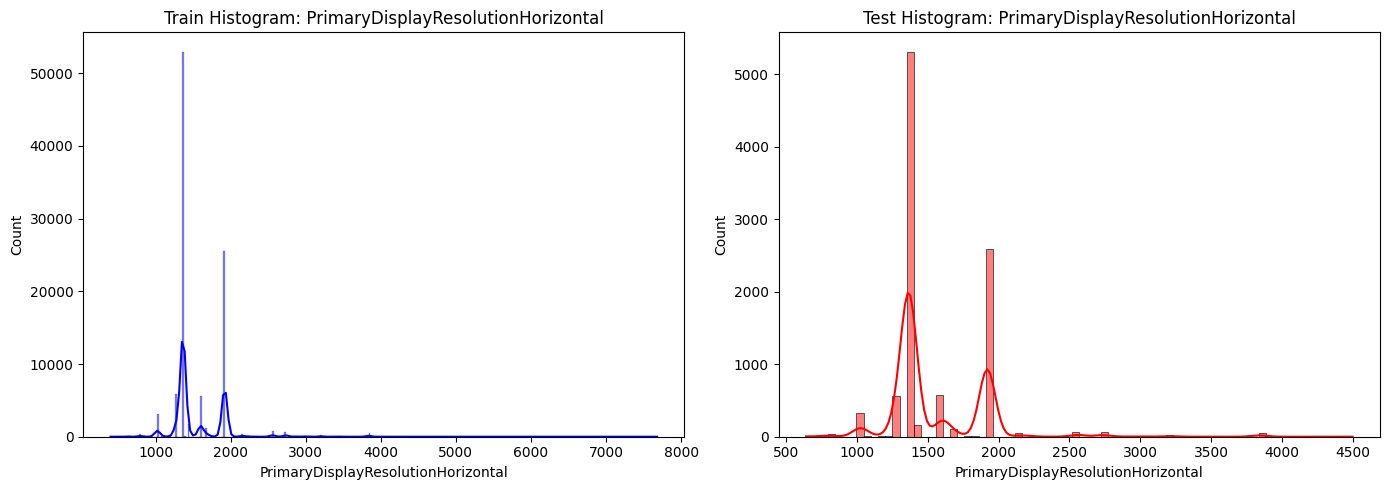

/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


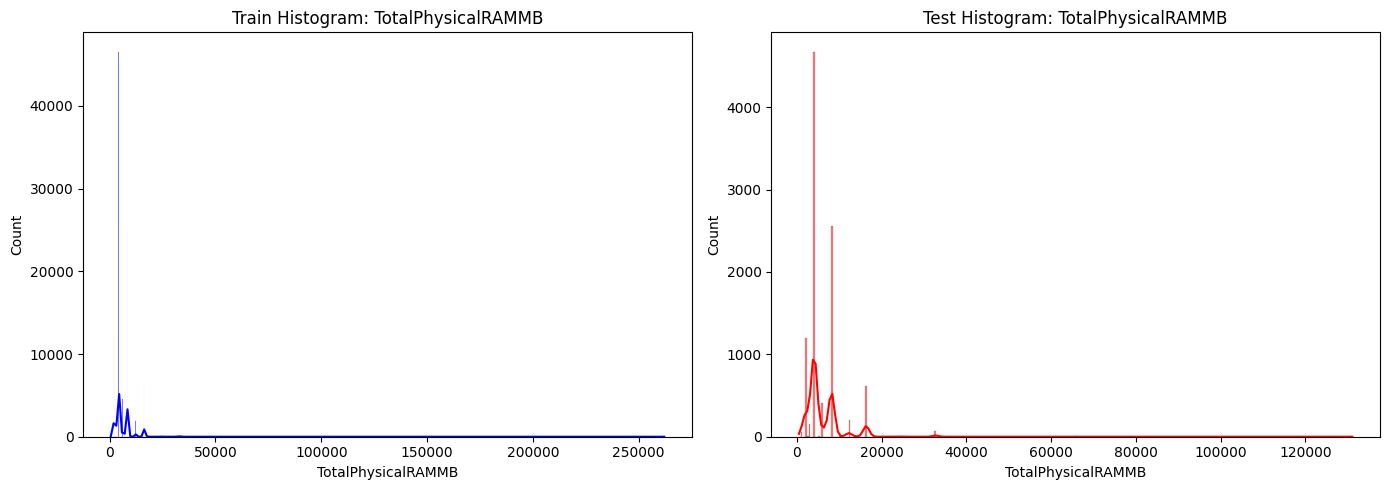

/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


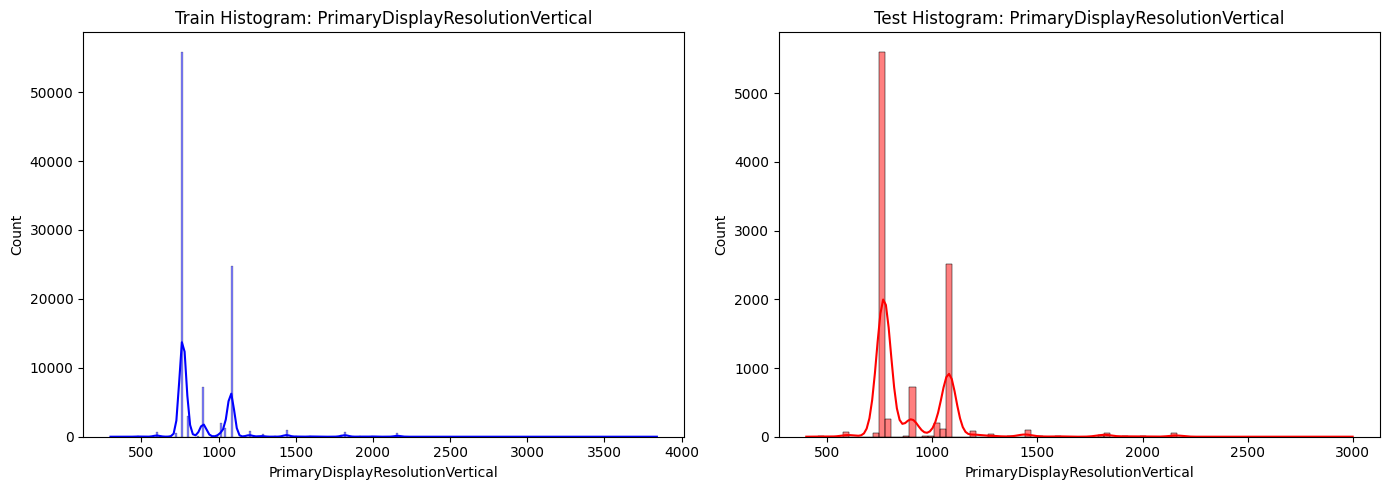

/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


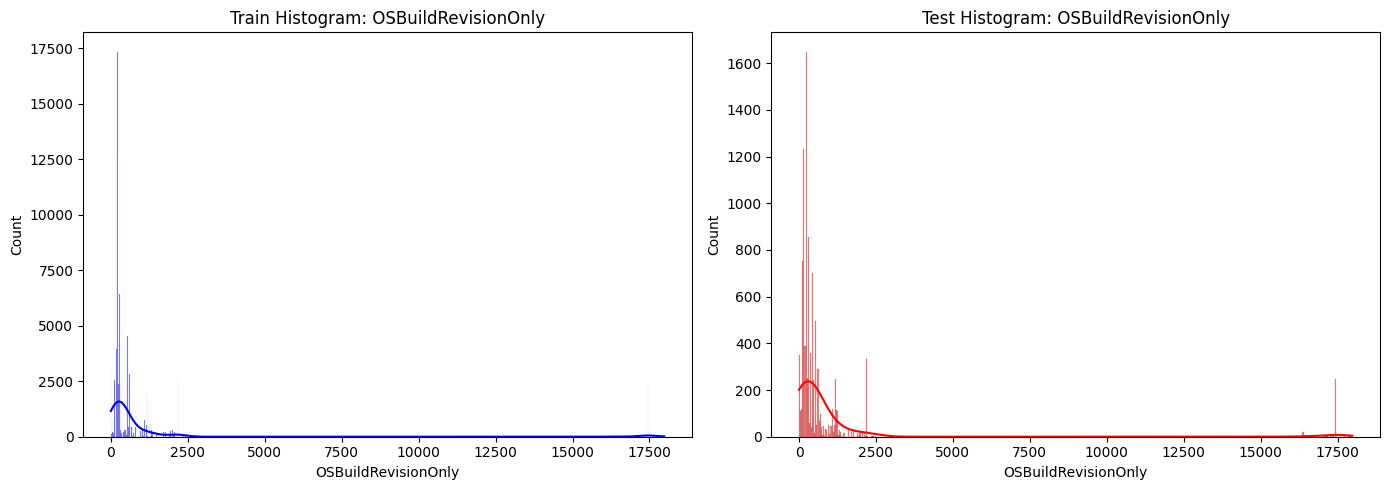

/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


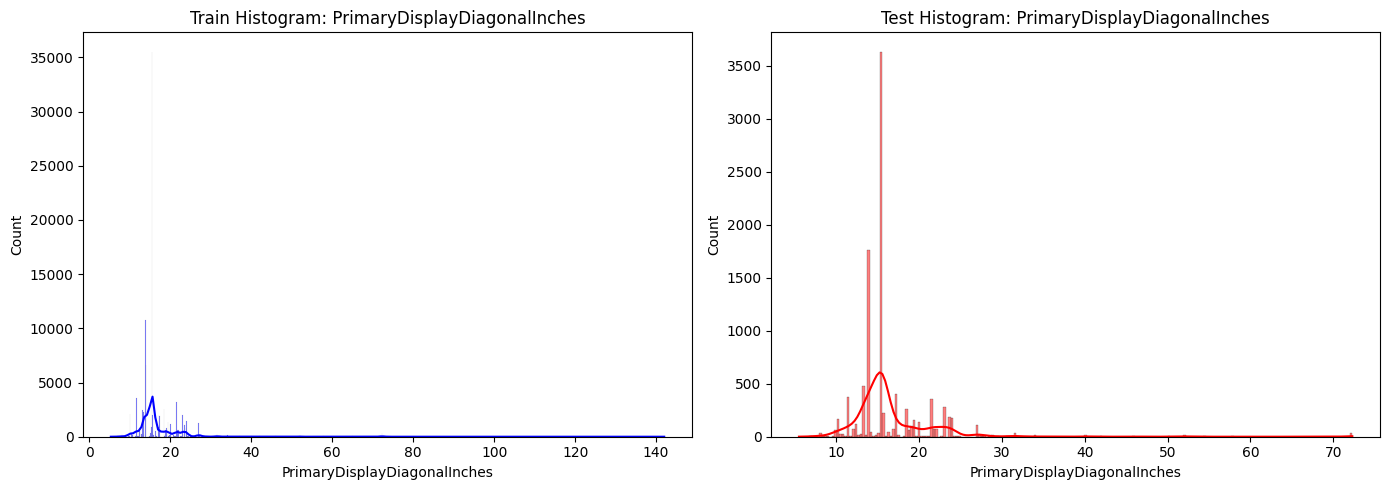

/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


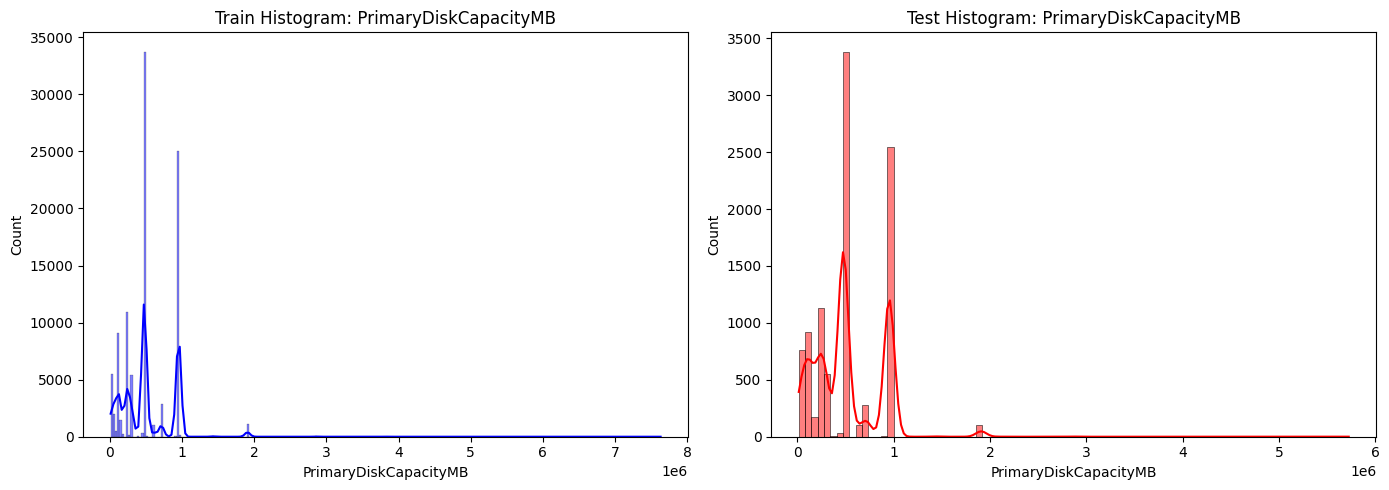

/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


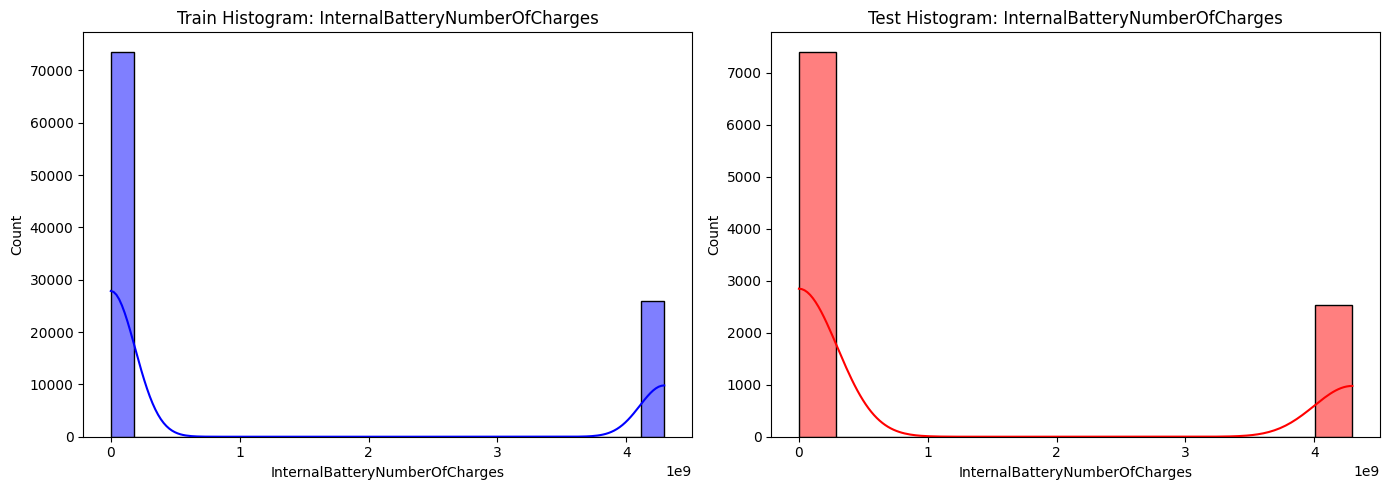

/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


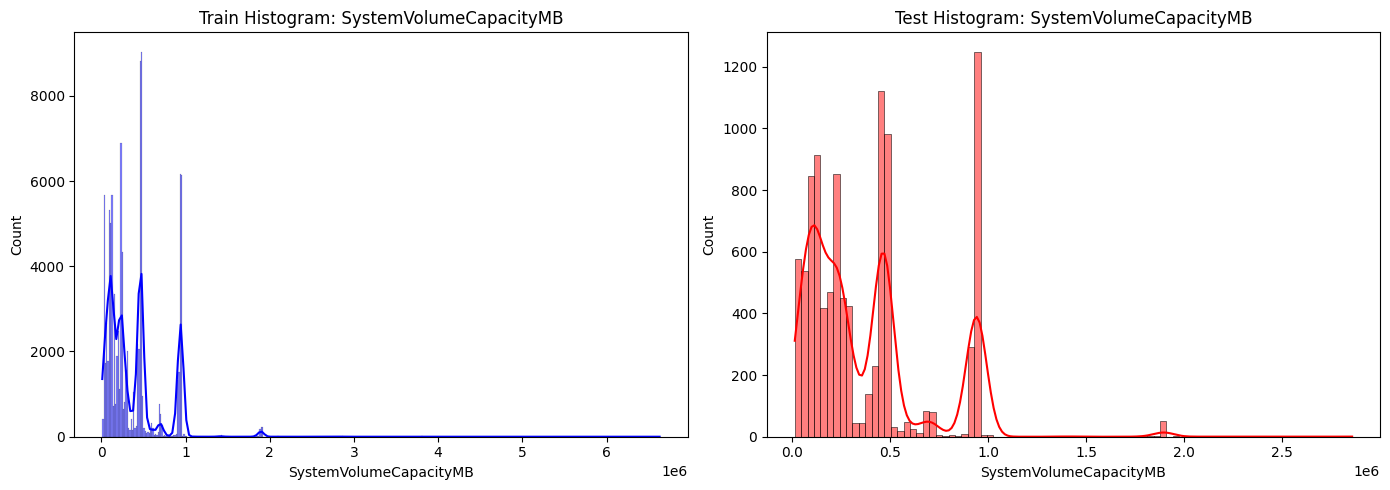

In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def plot_histograms(train_df, test_df):
    numerical_cols = train_df.columns.tolist()

    for col in numerical_cols:
        fig, axes = plt.subplots(1, 2, figsize=(14, 5))        
        sns.histplot(train_df[col], kde=True, ax=axes[0], color="blue")
        axes[0].set_title(f"Train Histogram: {col}")       
        sns.histplot(test_df[col], kde=True, ax=axes[1], color="red")
        axes[1].set_title(f"Test Histogram: {col}")
        plt.tight_layout()
        plt.show()


plot_histograms(train_df=data[num], test_df=test_data[num])


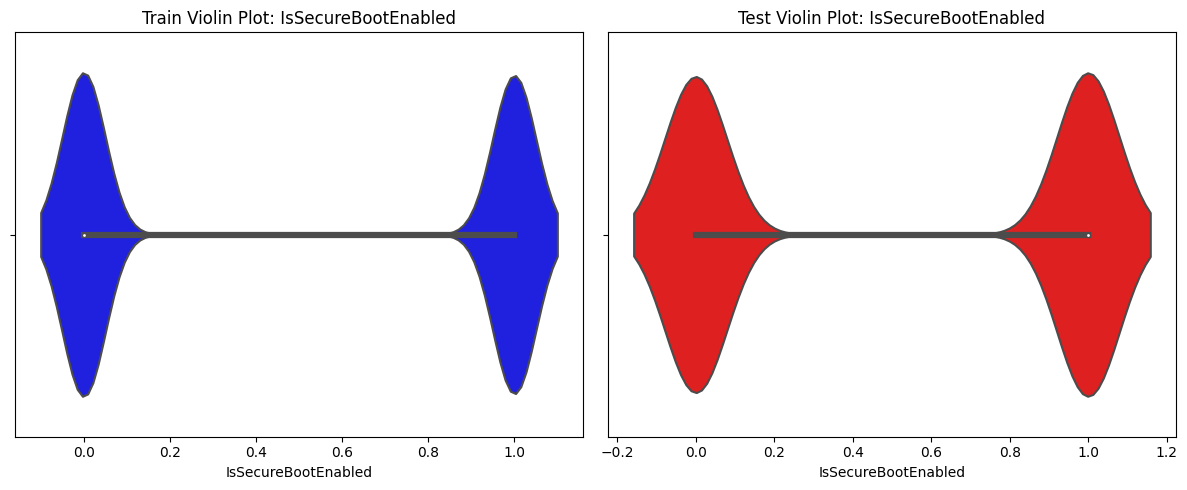

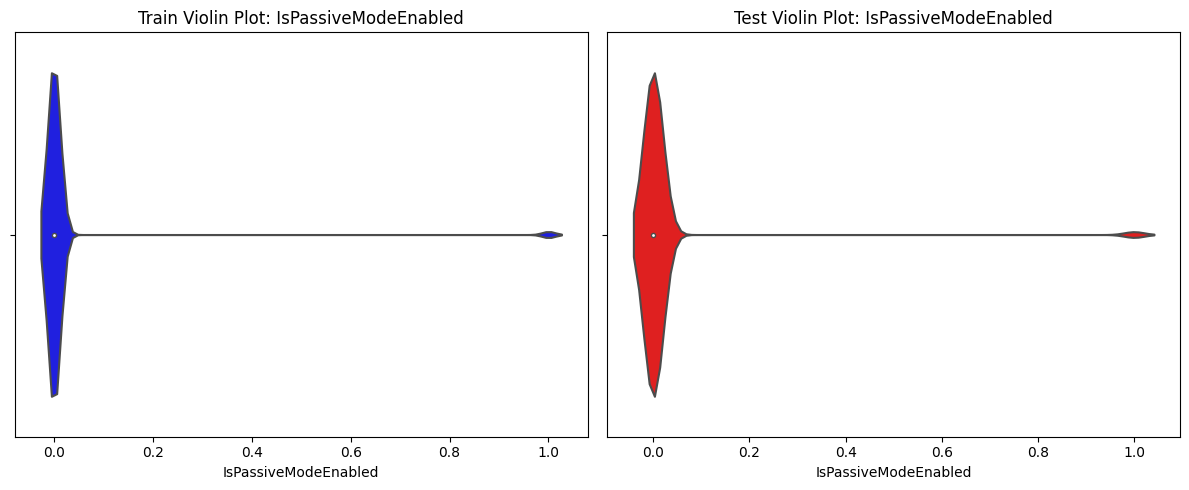

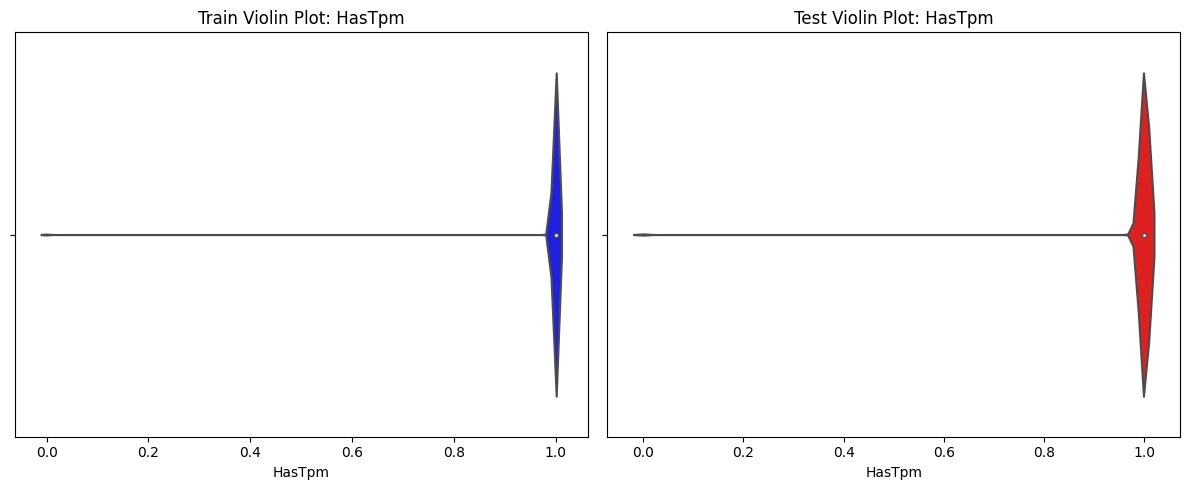

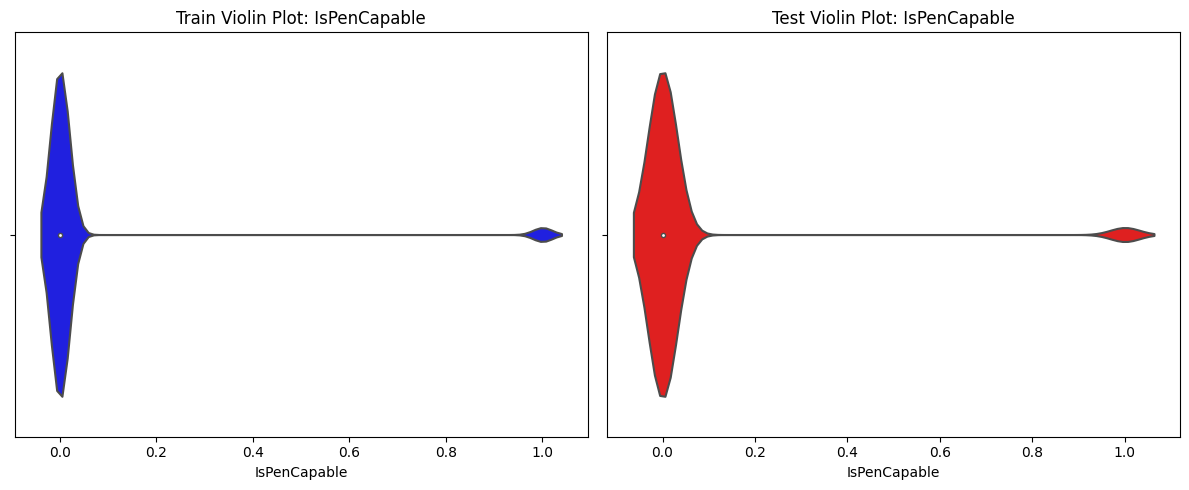

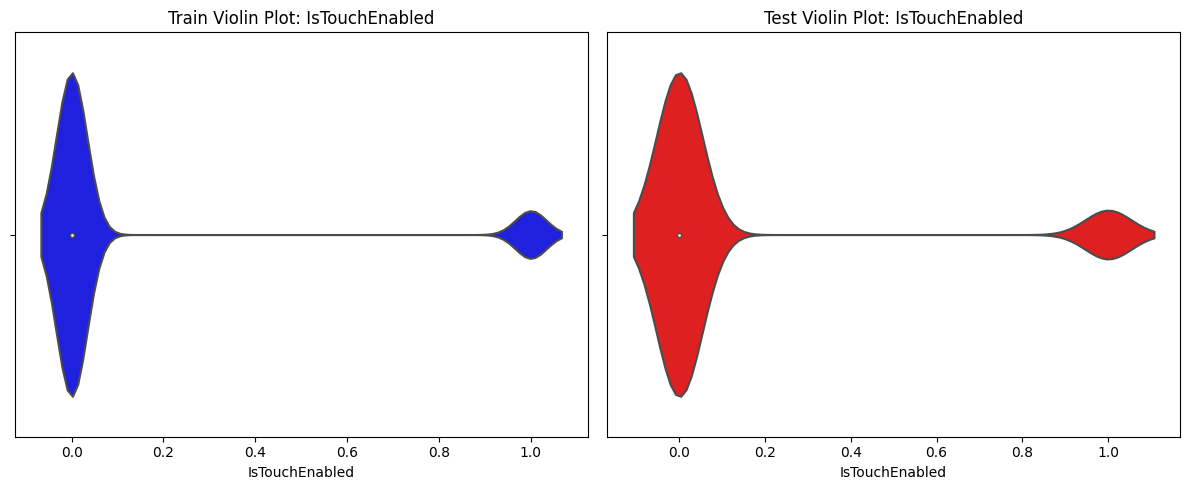

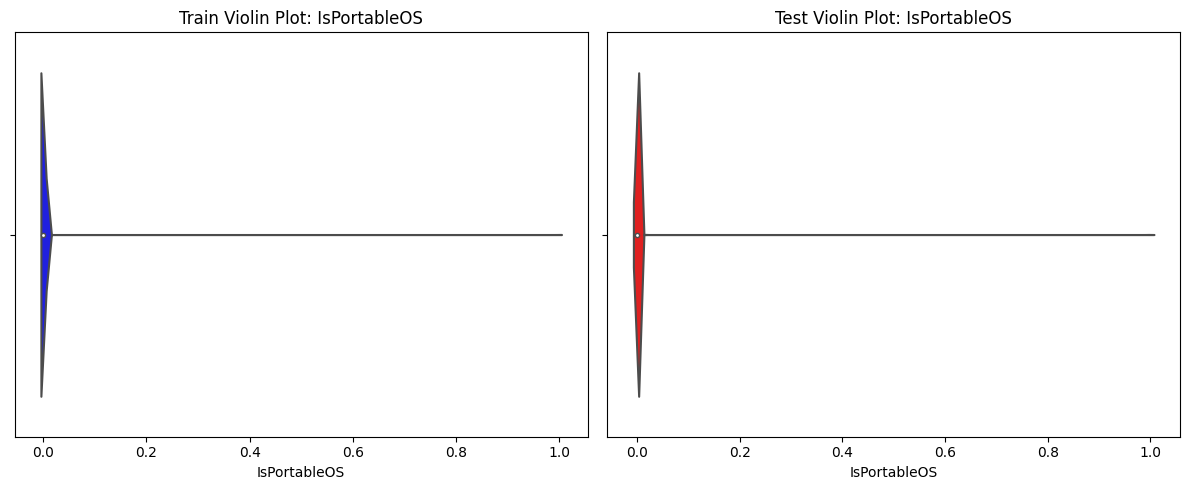

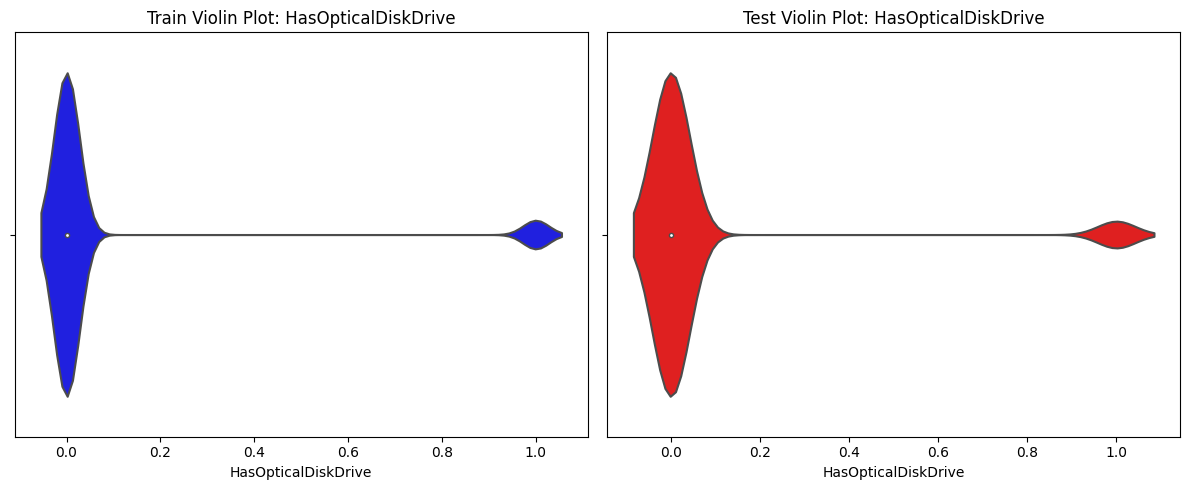

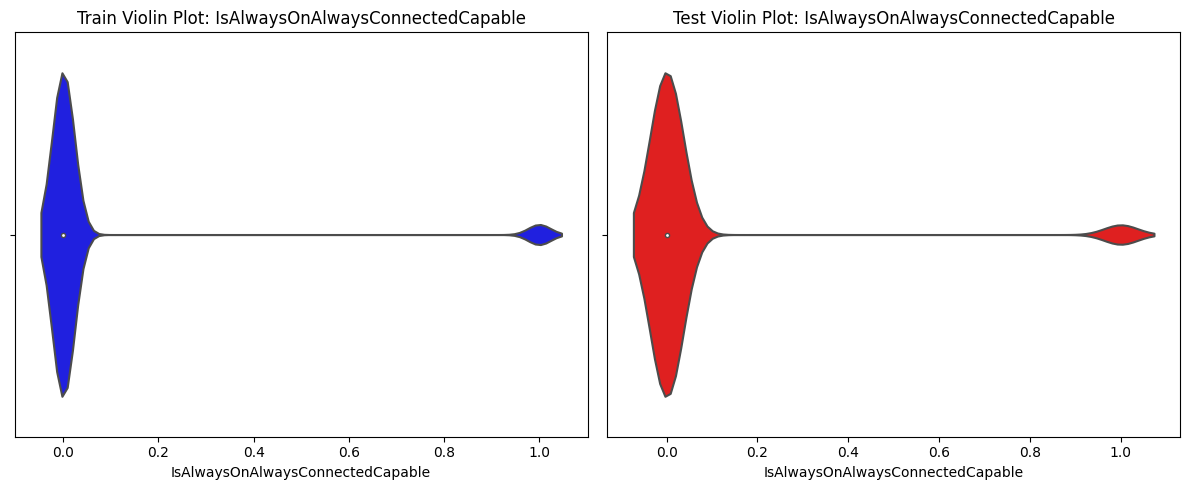

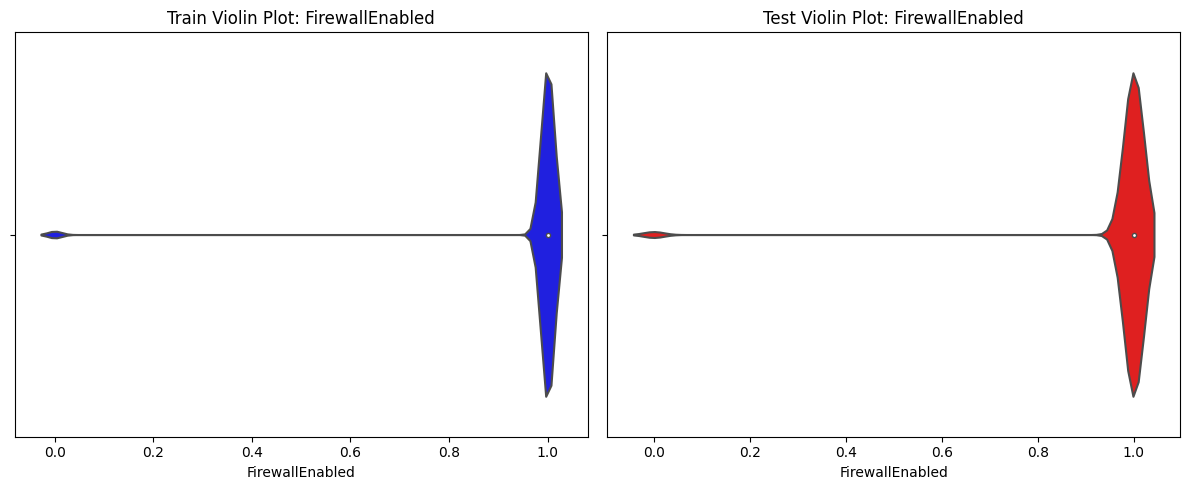

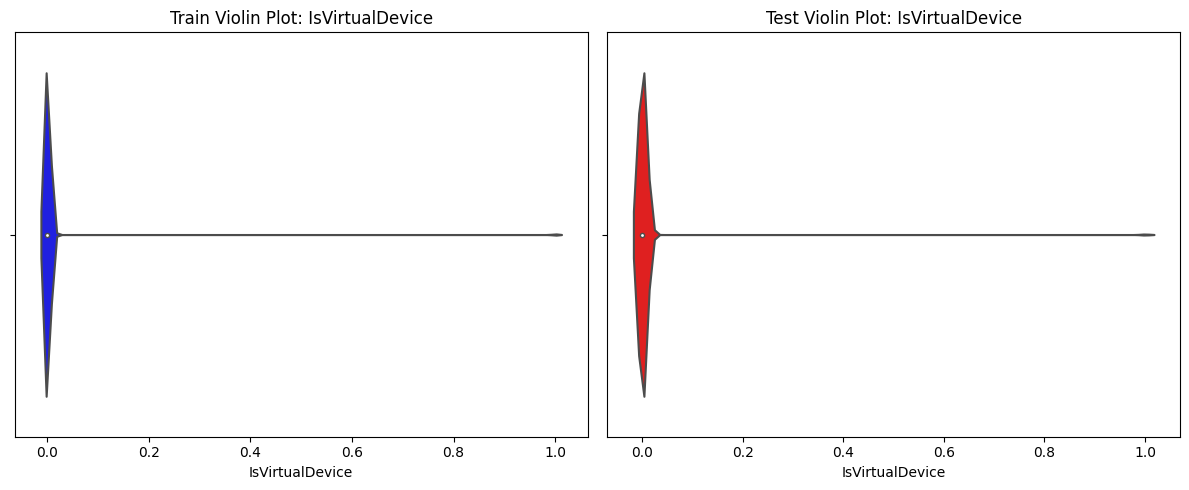

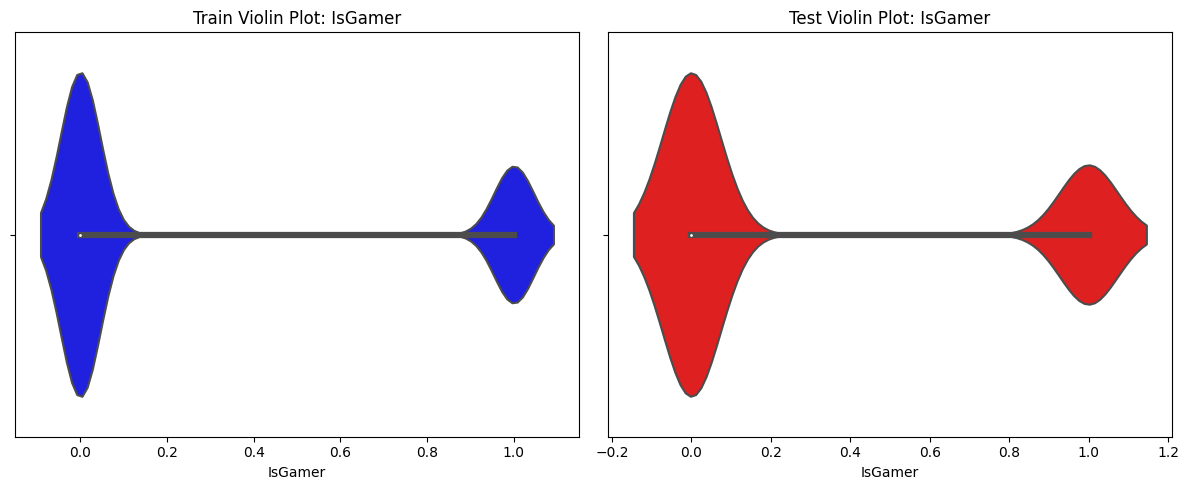

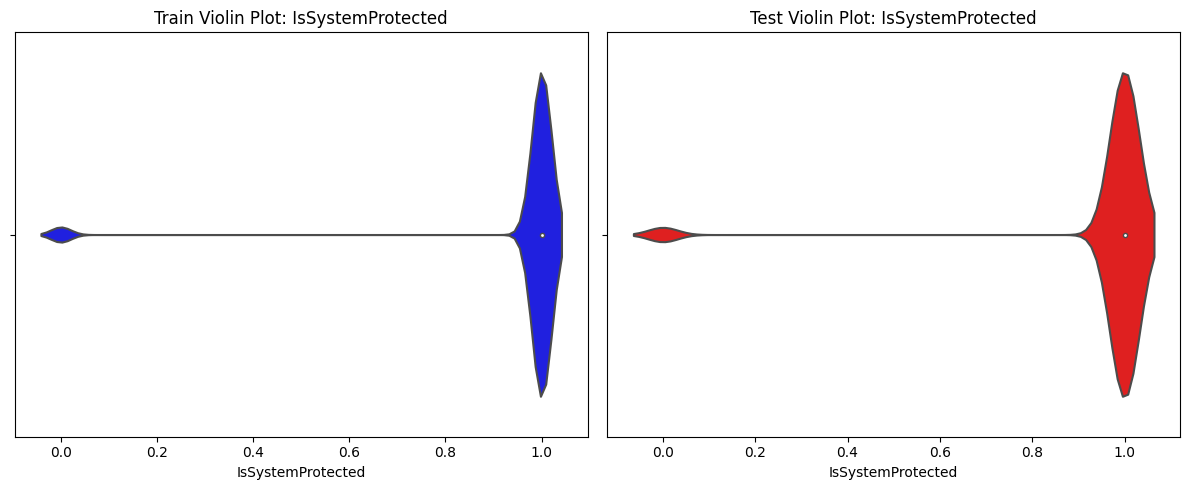

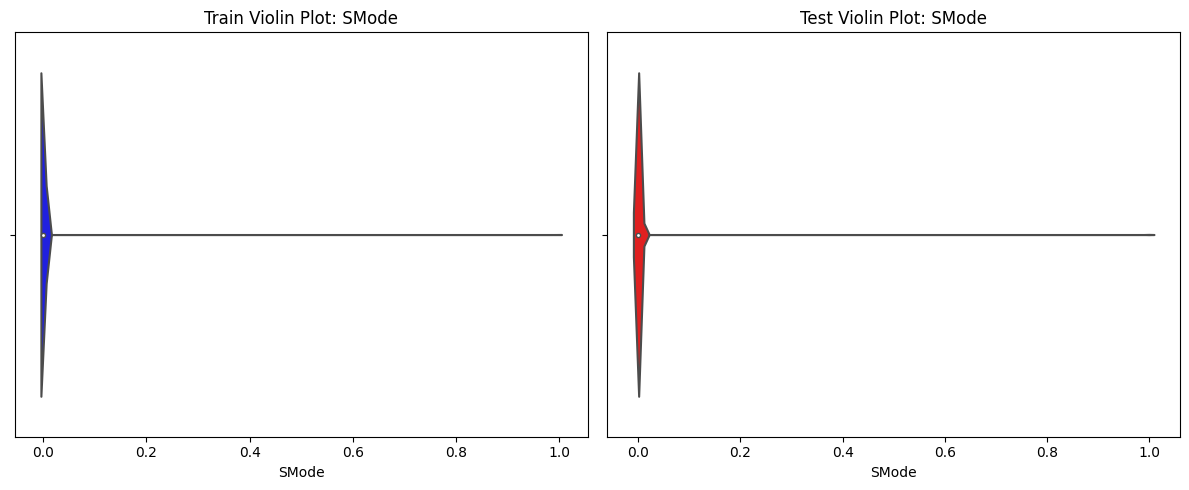

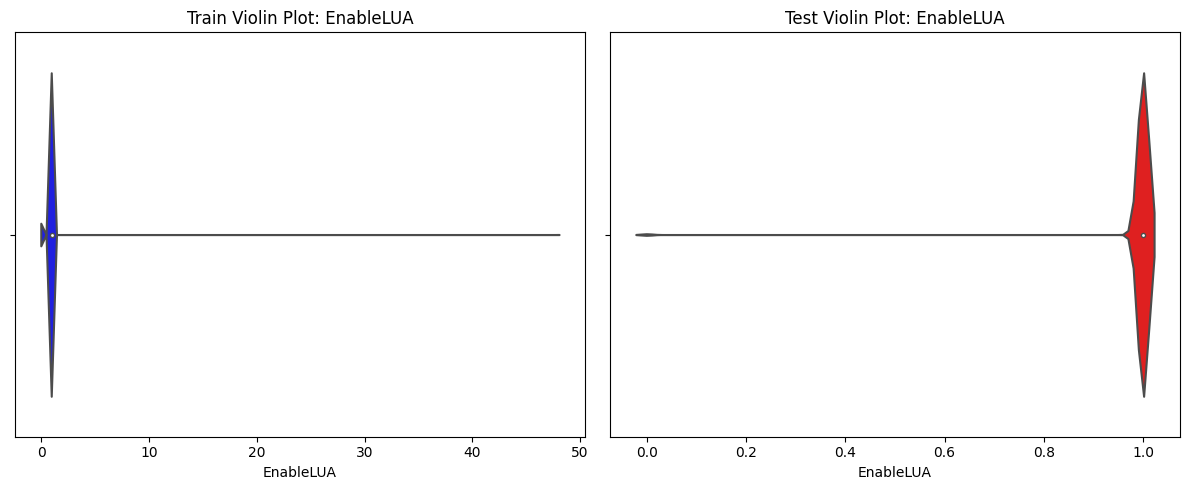

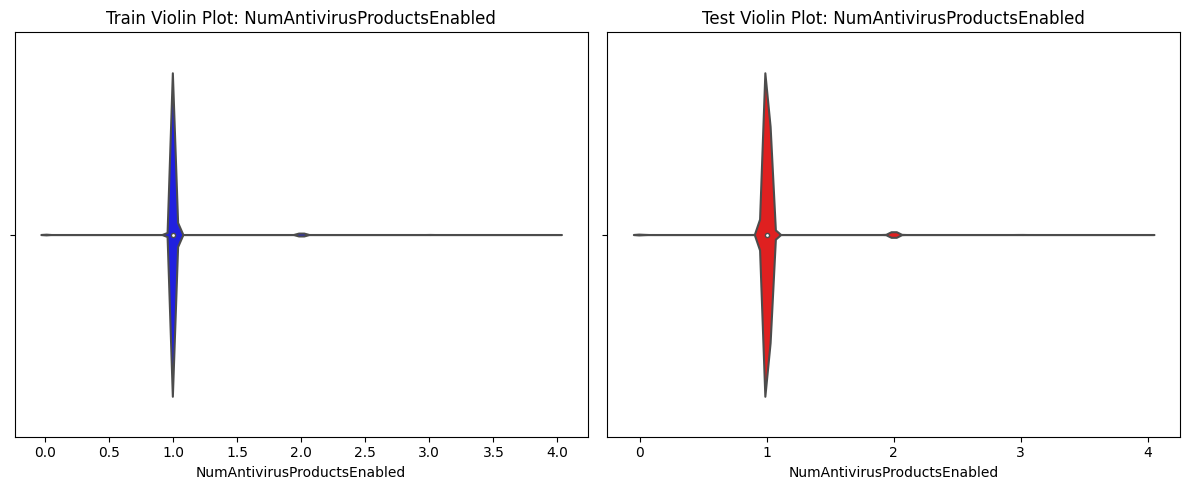

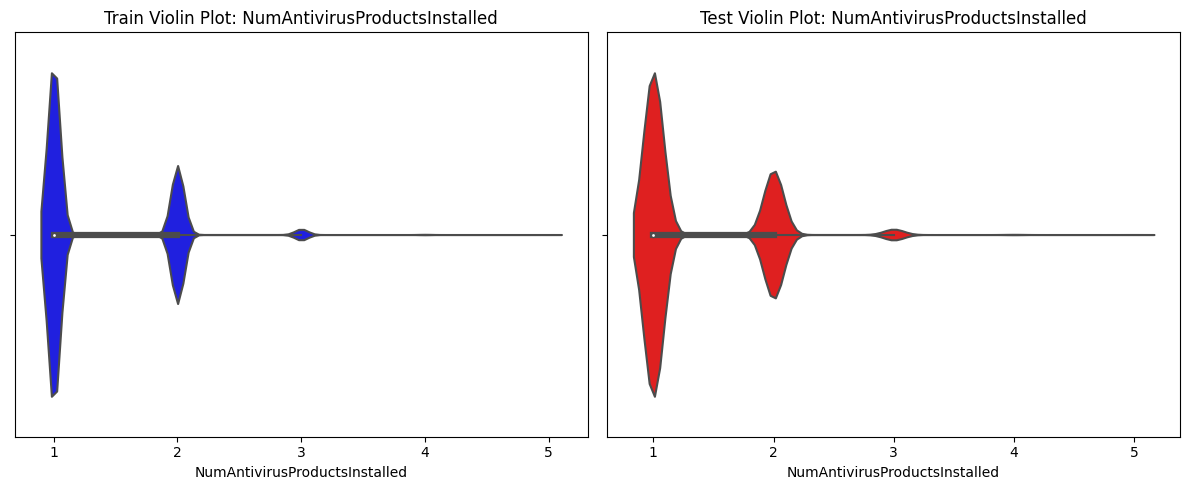

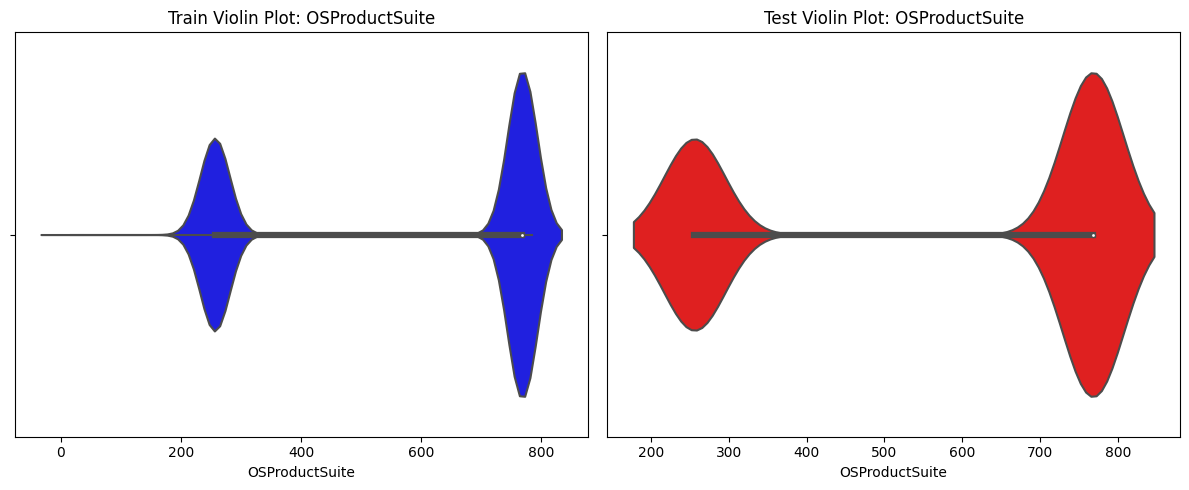

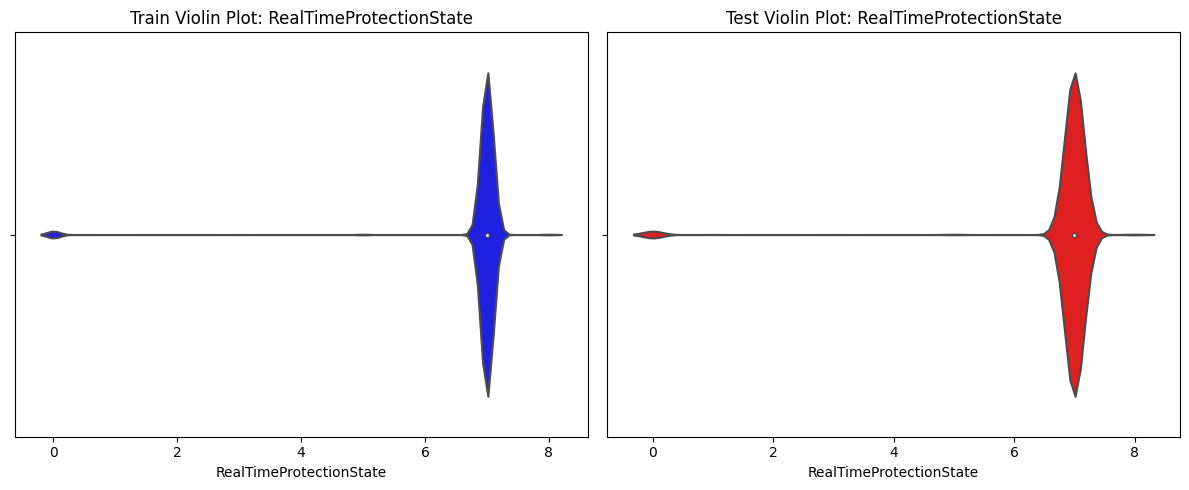

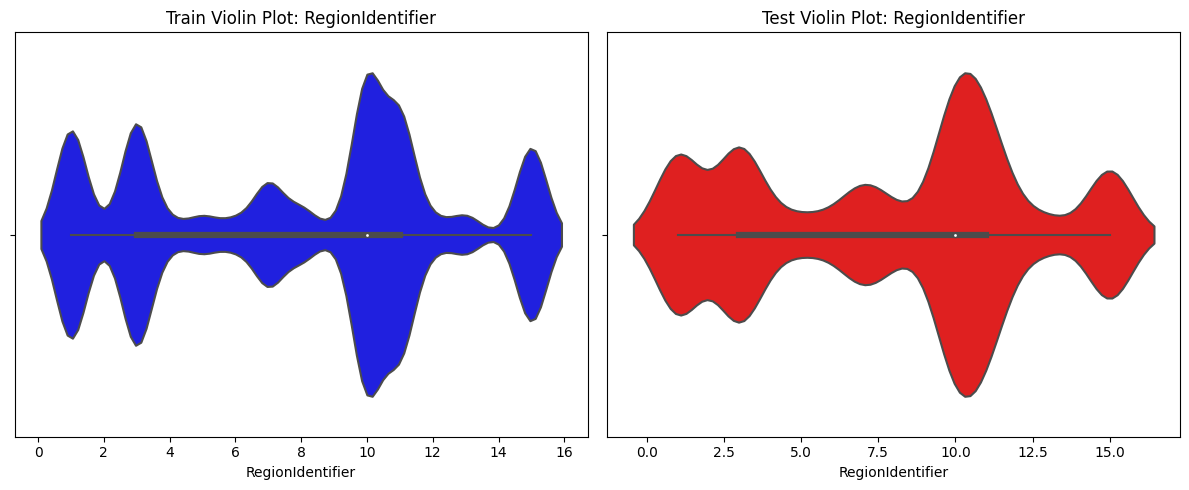

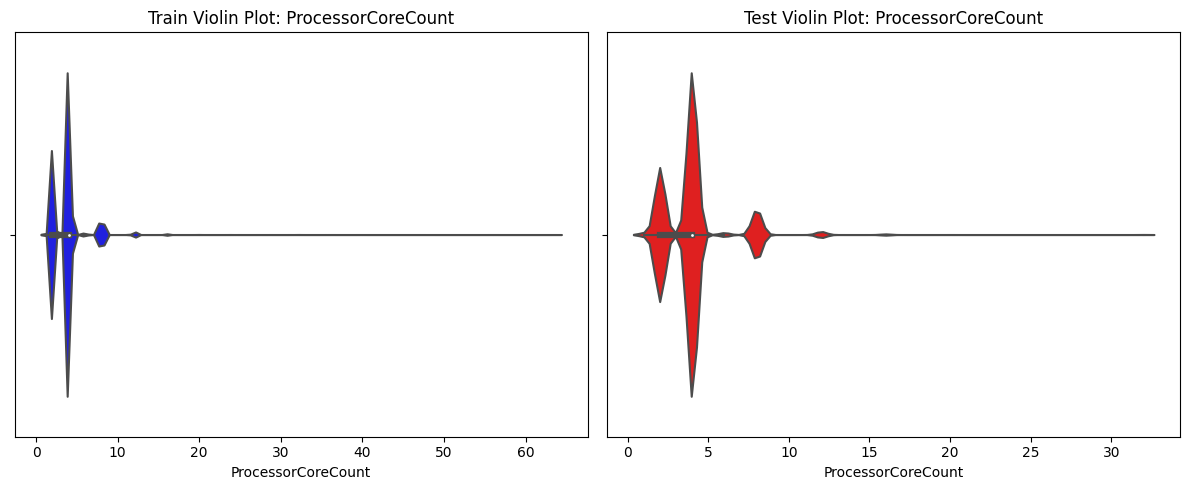

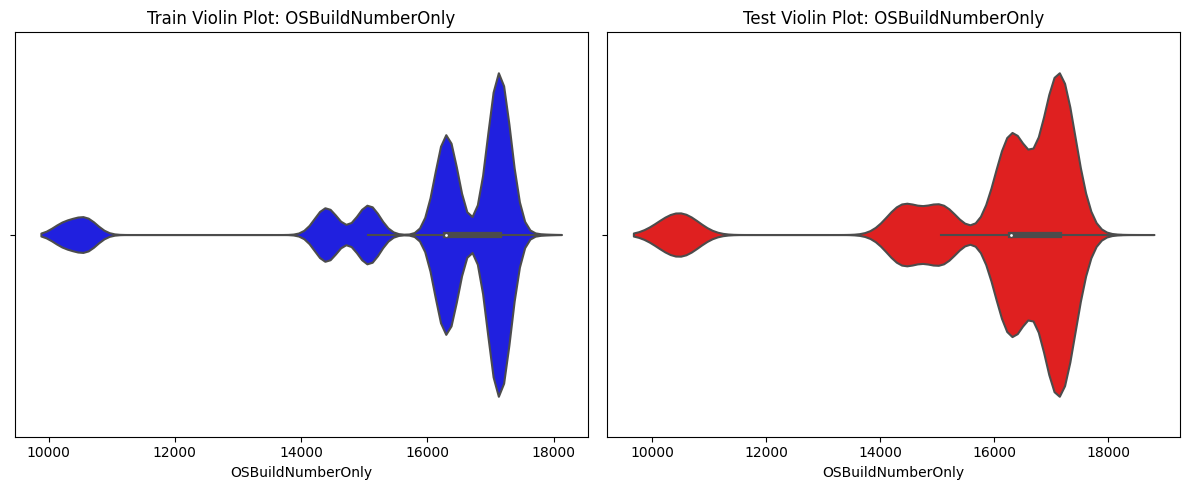

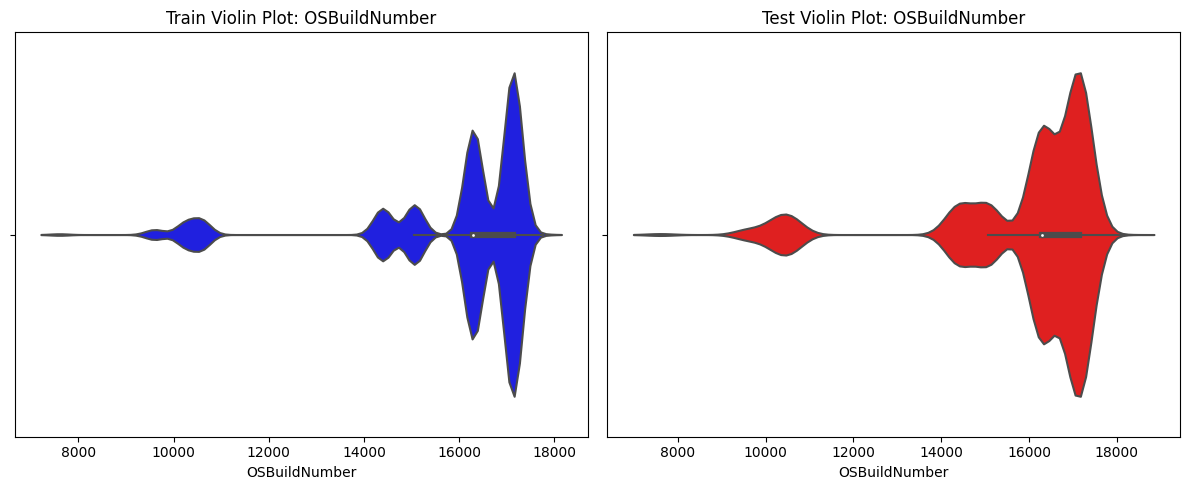

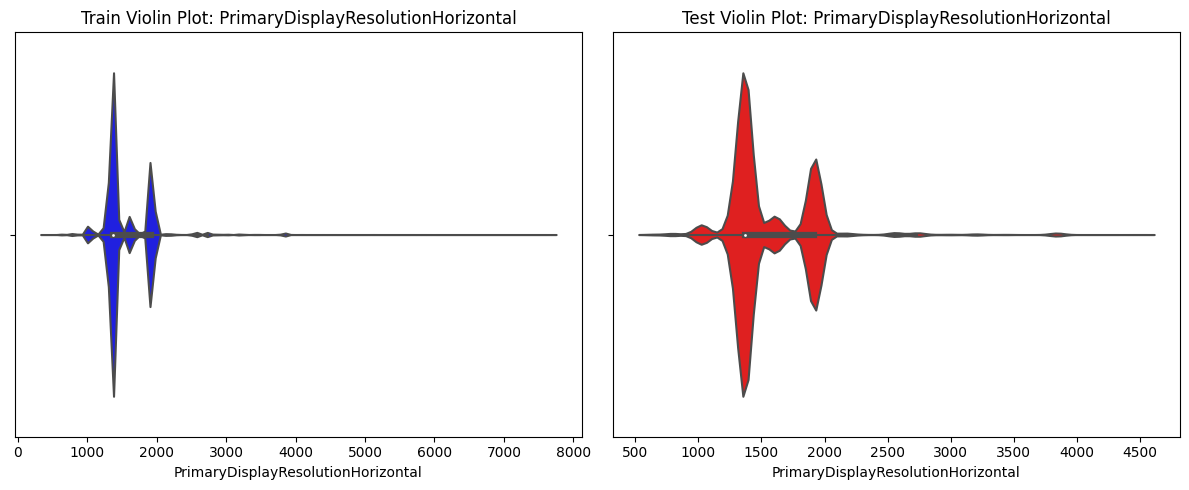

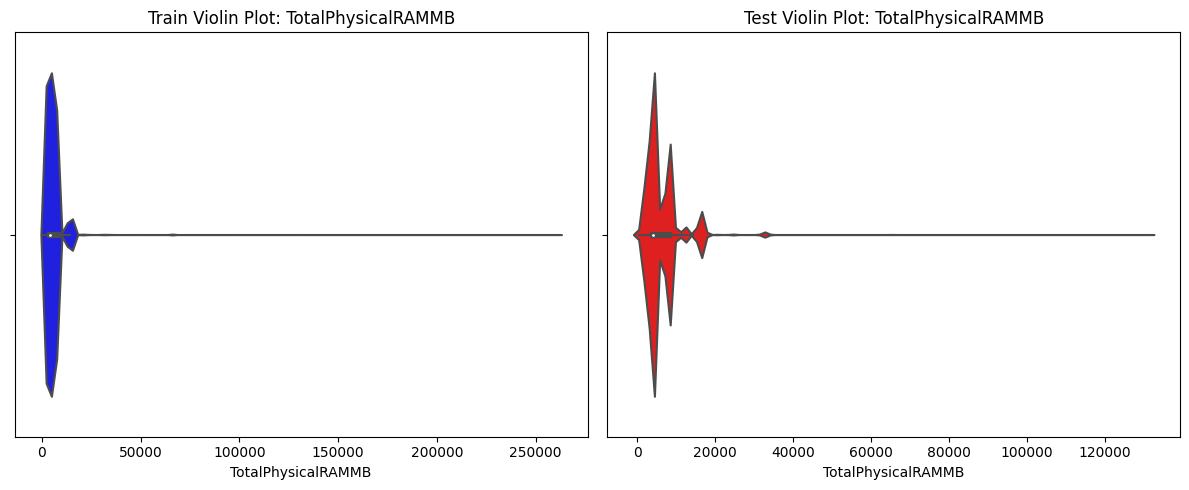

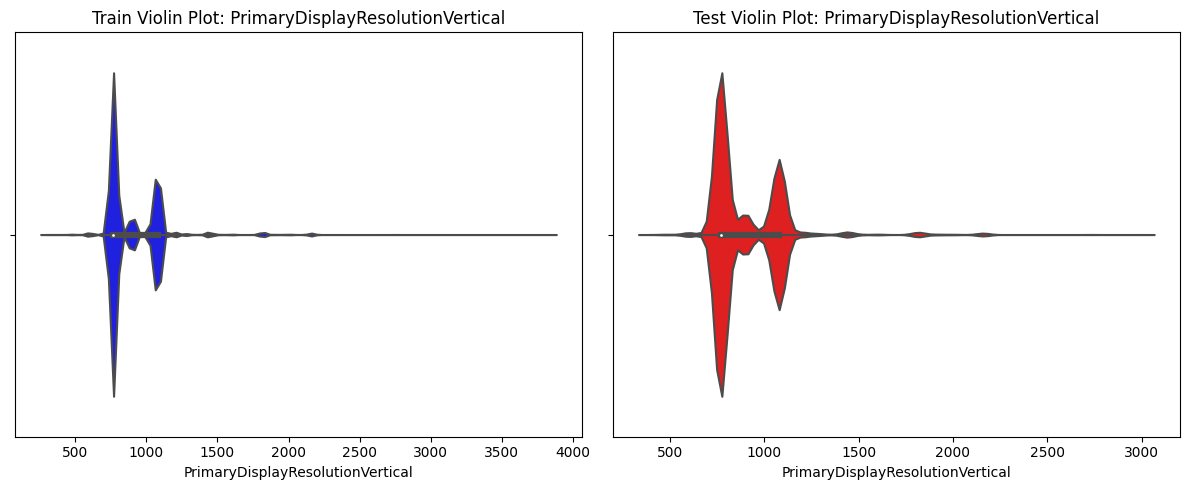

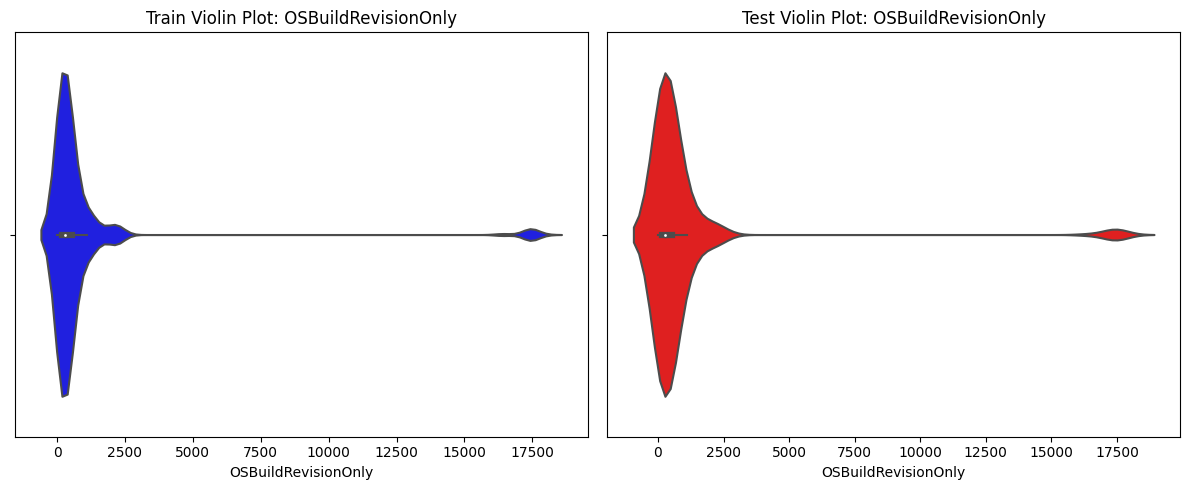

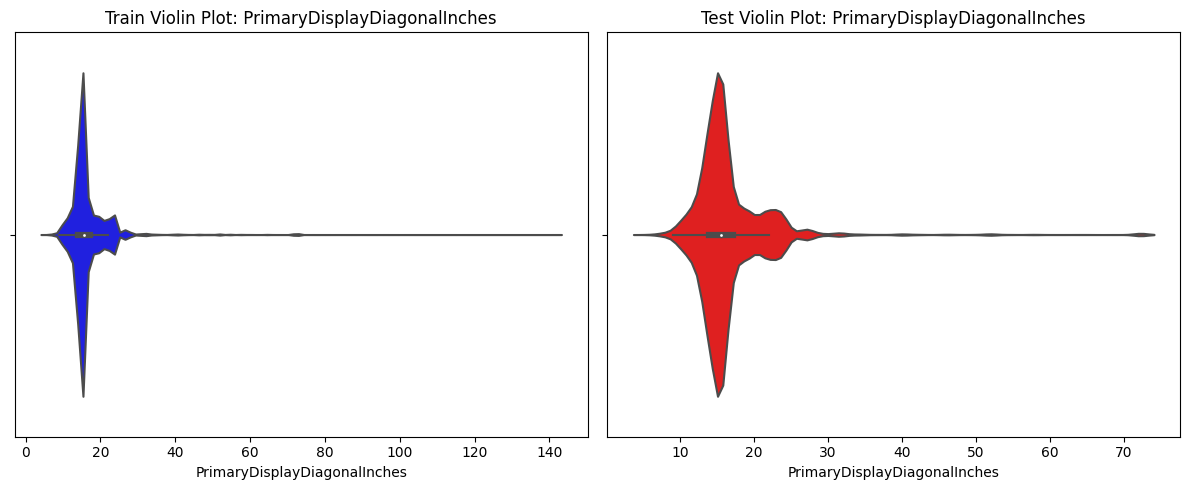

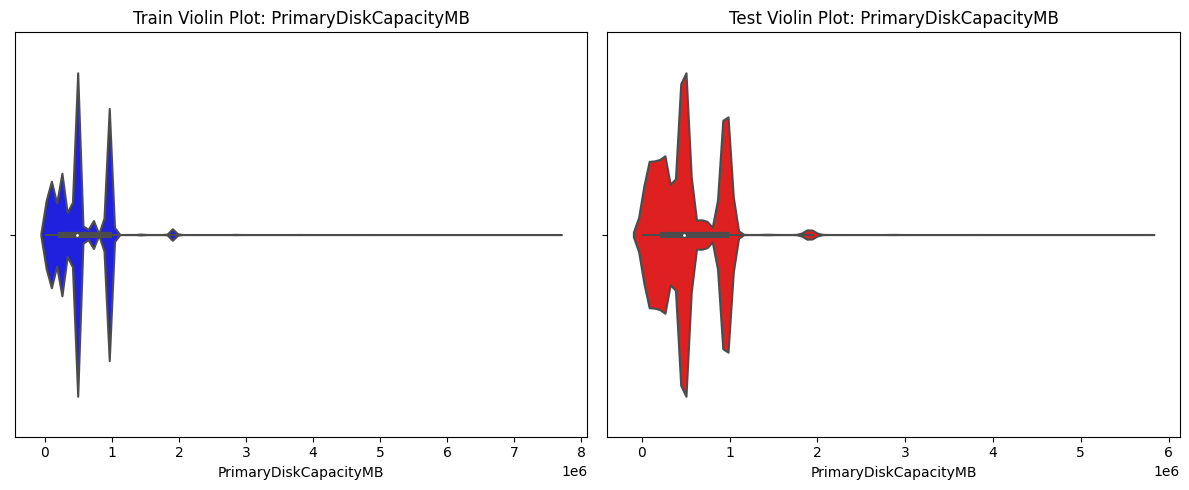

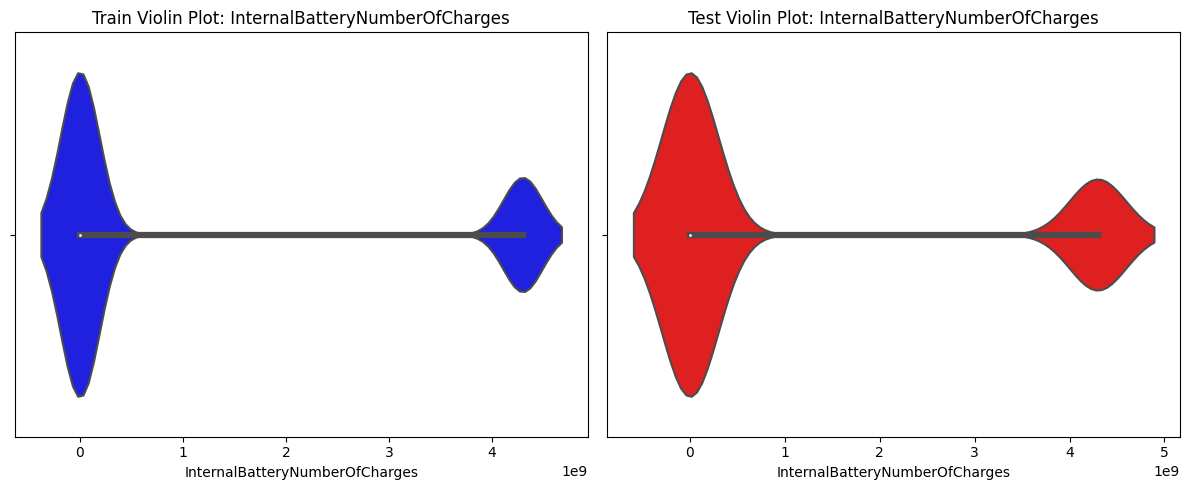

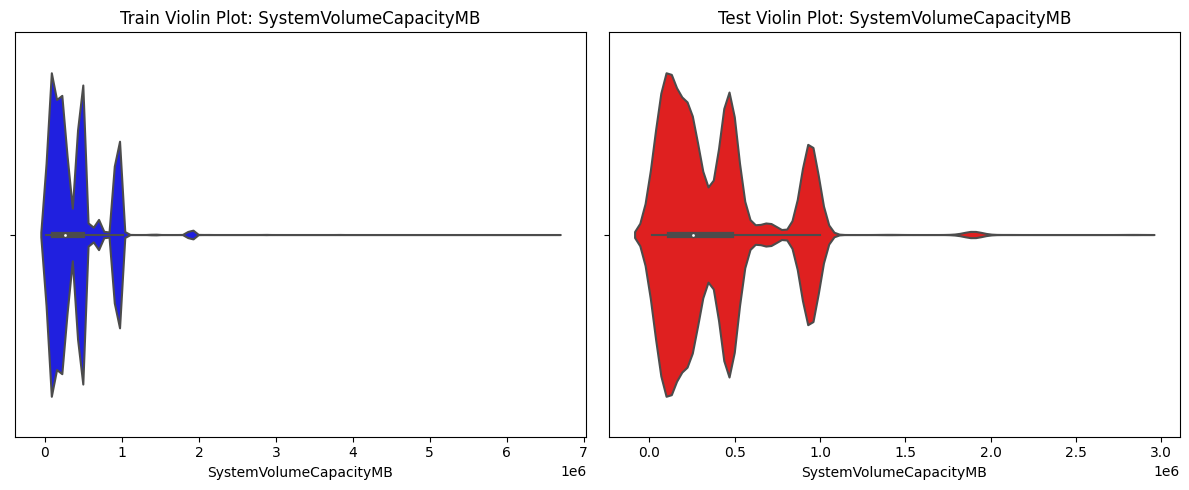

In [31]:
def plot_violinplots(train_df, test_df):
    numerical_cols = train_df.columns.tolist()

    for col in numerical_cols:
        fig, axes = plt.subplots(1, 2, figsize=(12, 5))        
        sns.violinplot(x=train_df[col], ax=axes[0], color="blue")
        axes[0].set_title(f"Train Violin Plot: {col}")        
        sns.violinplot(x=test_df[col], ax=axes[1], color="red")
        axes[1].set_title(f"Test Violin Plot: {col}")
        plt.tight_layout()
        plt.show()

plot_violinplots(train_df=data[num], test_df=test_data[num])


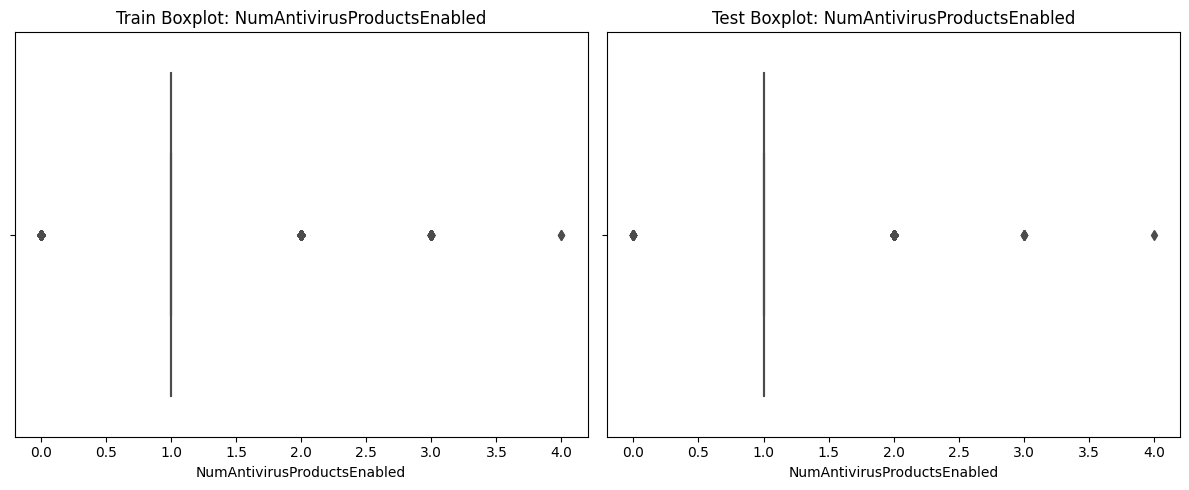

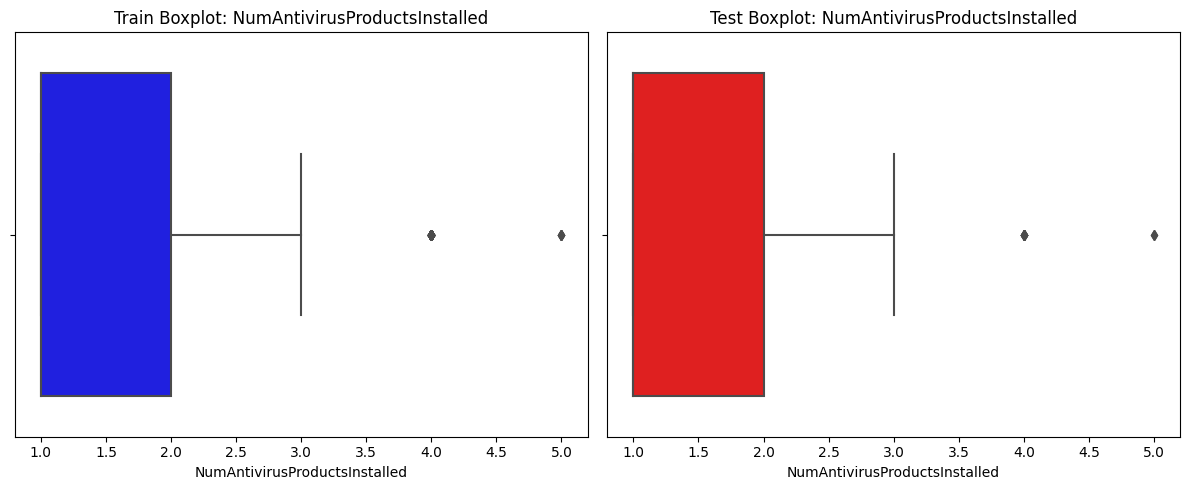

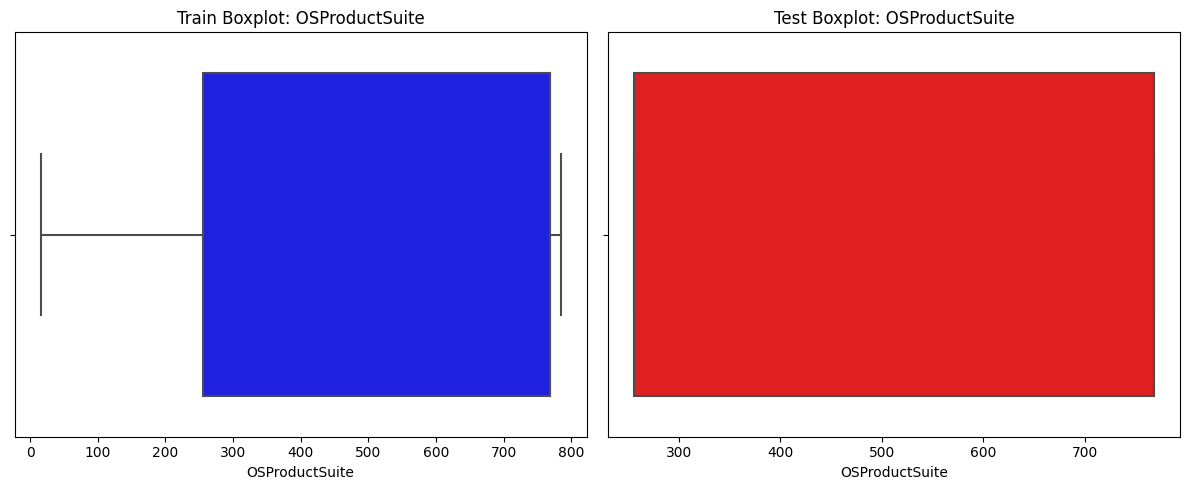

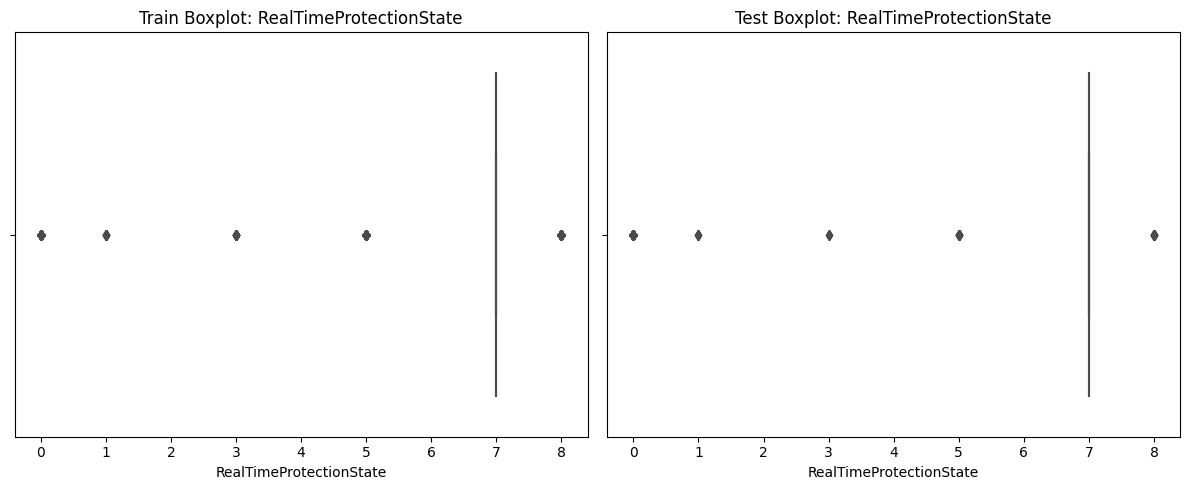

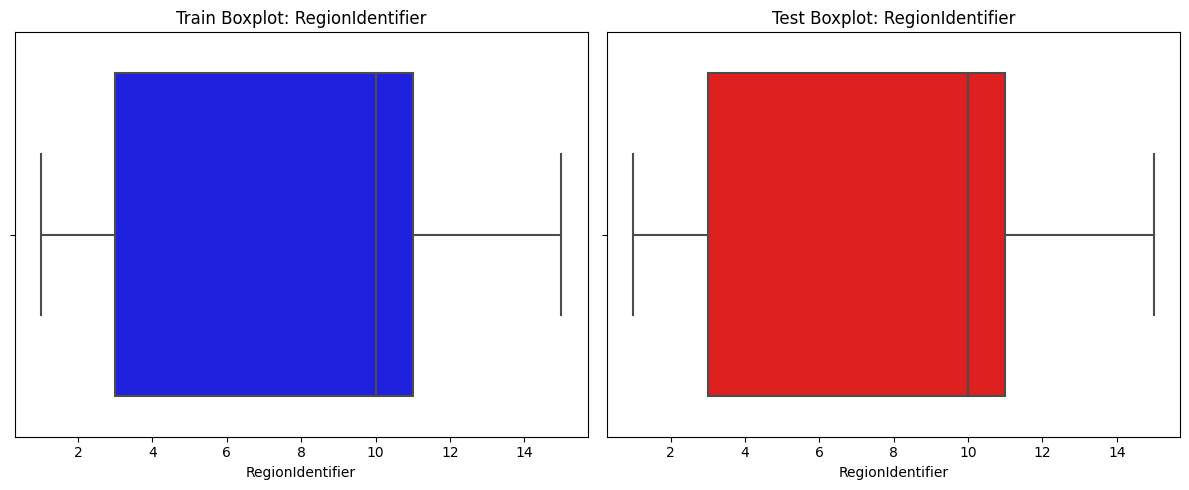

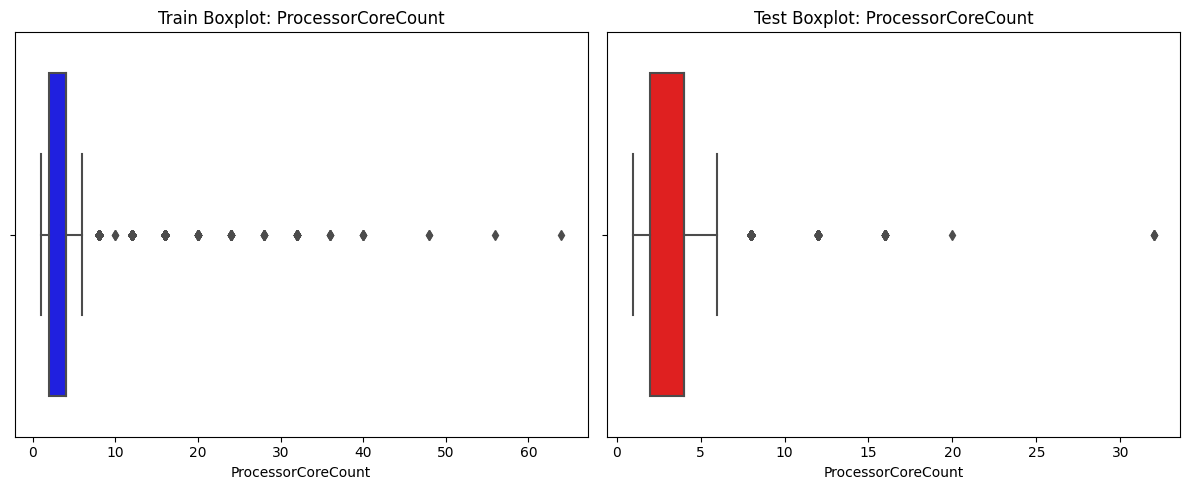

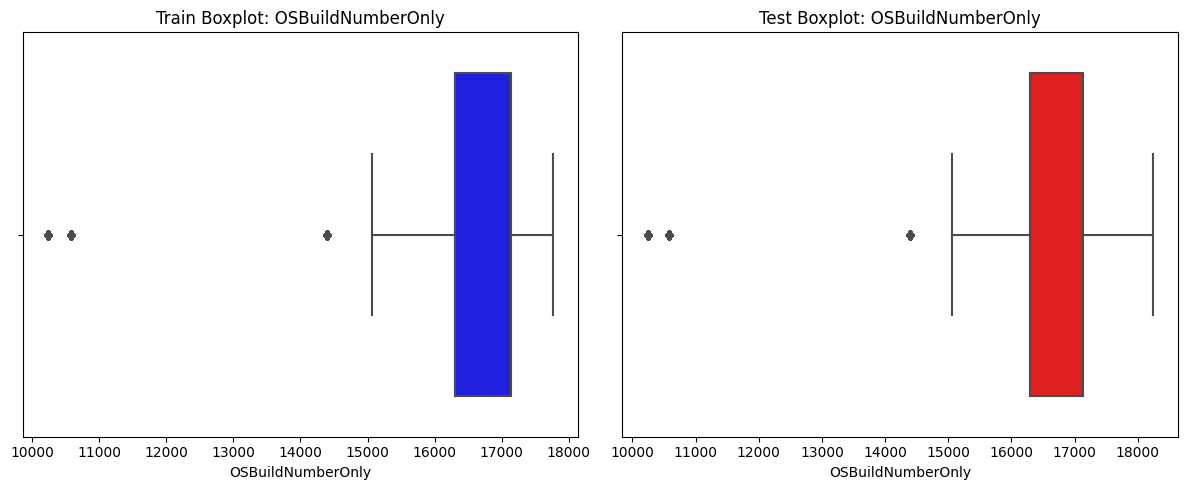

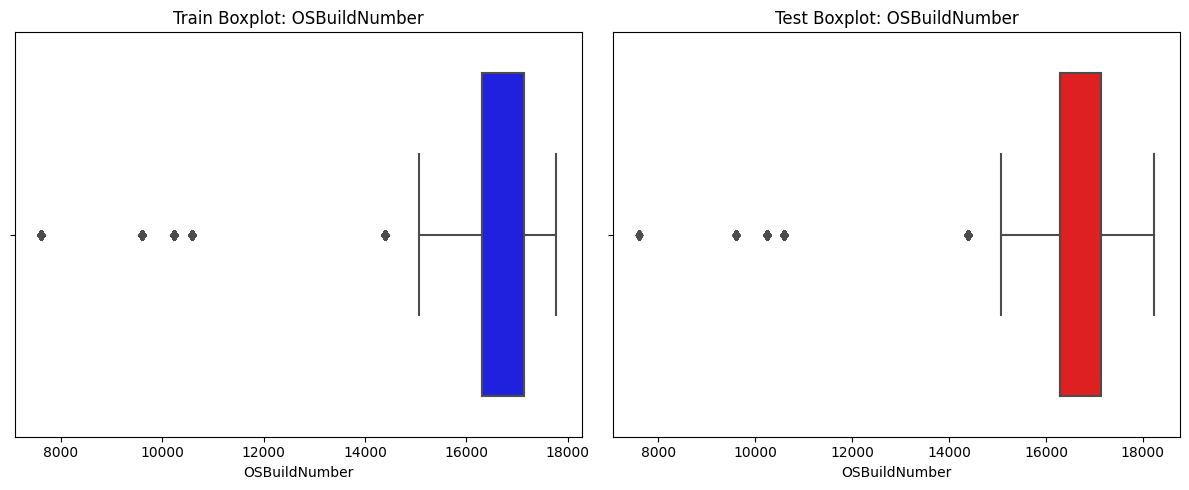

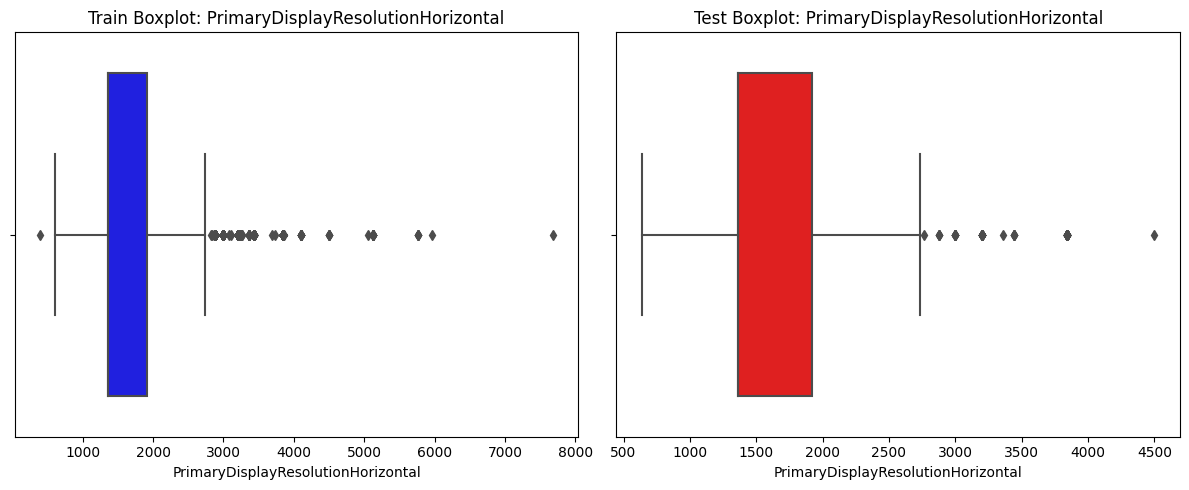

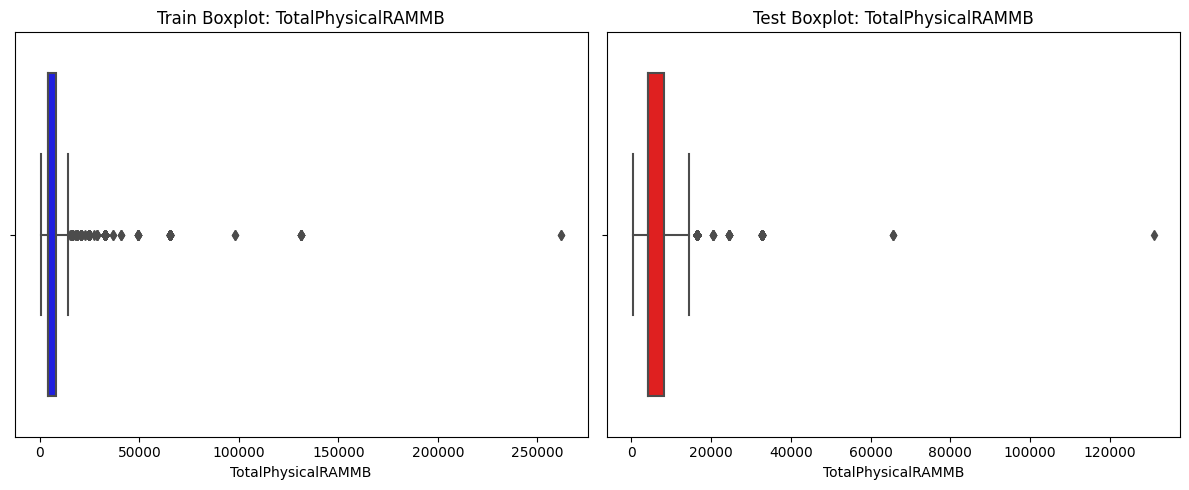

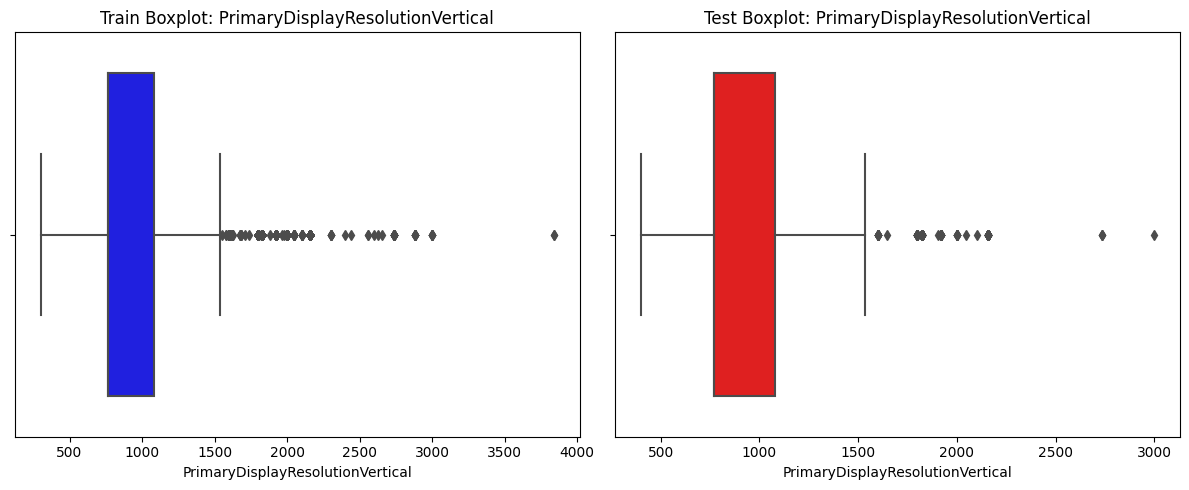

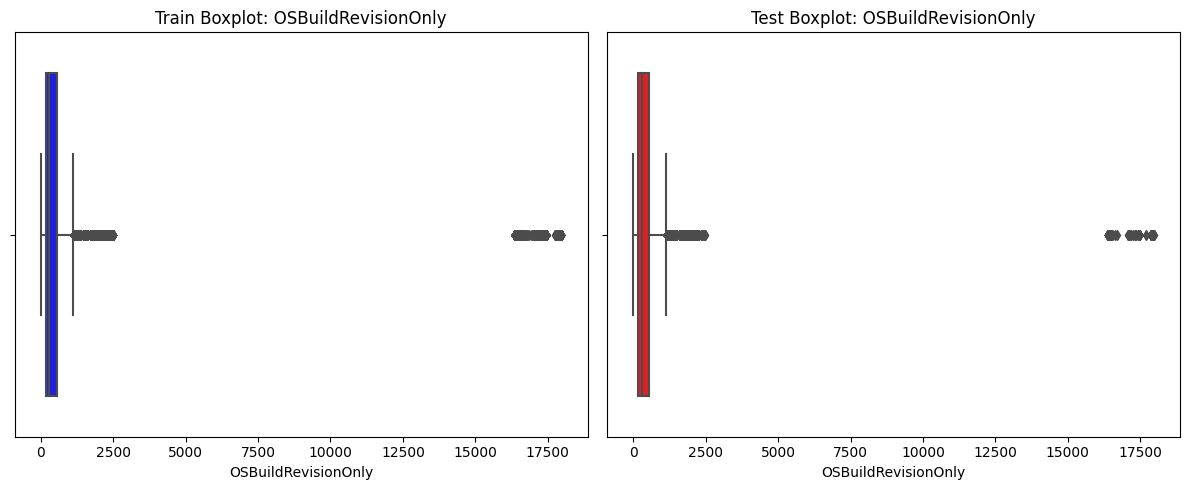

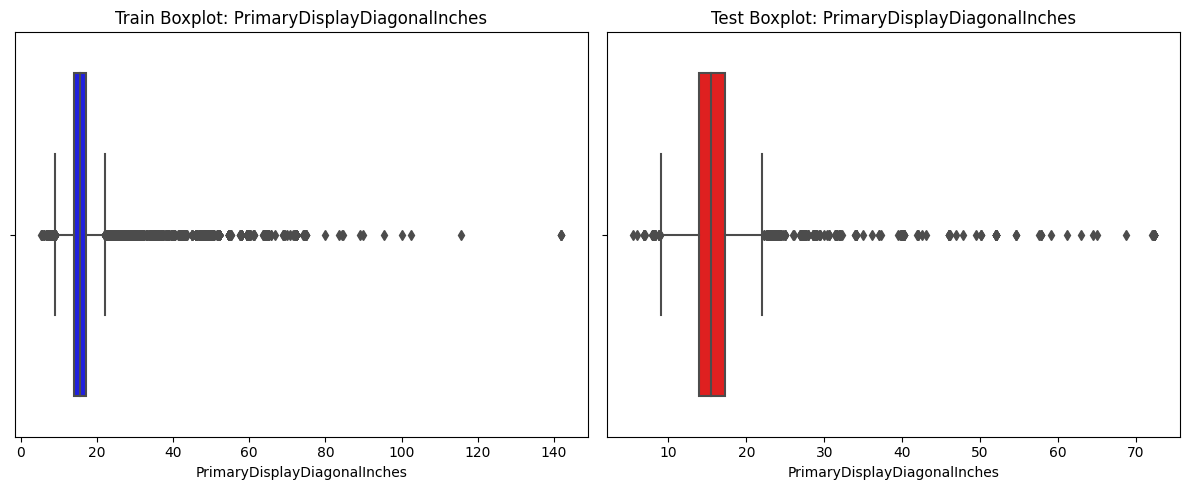

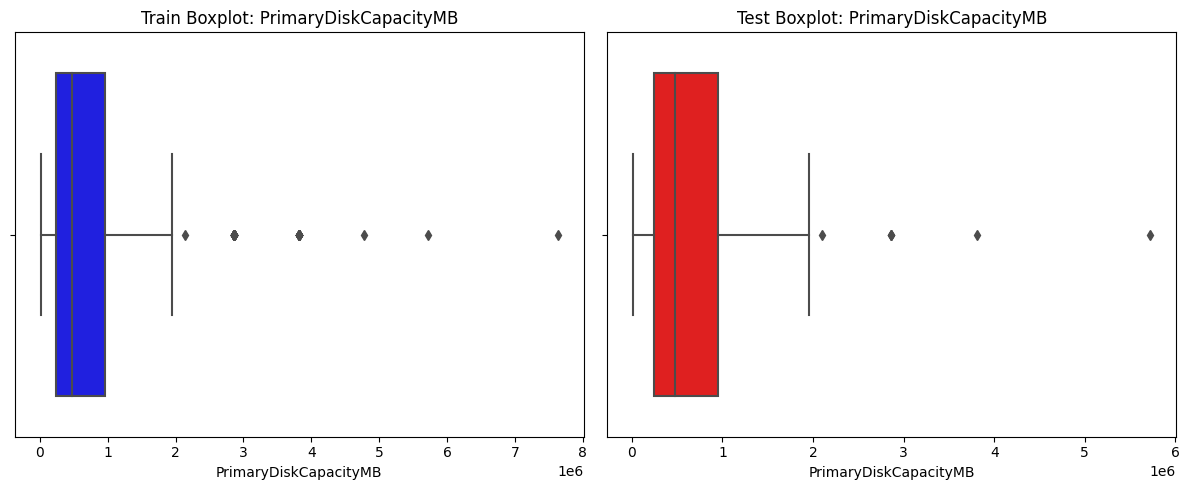

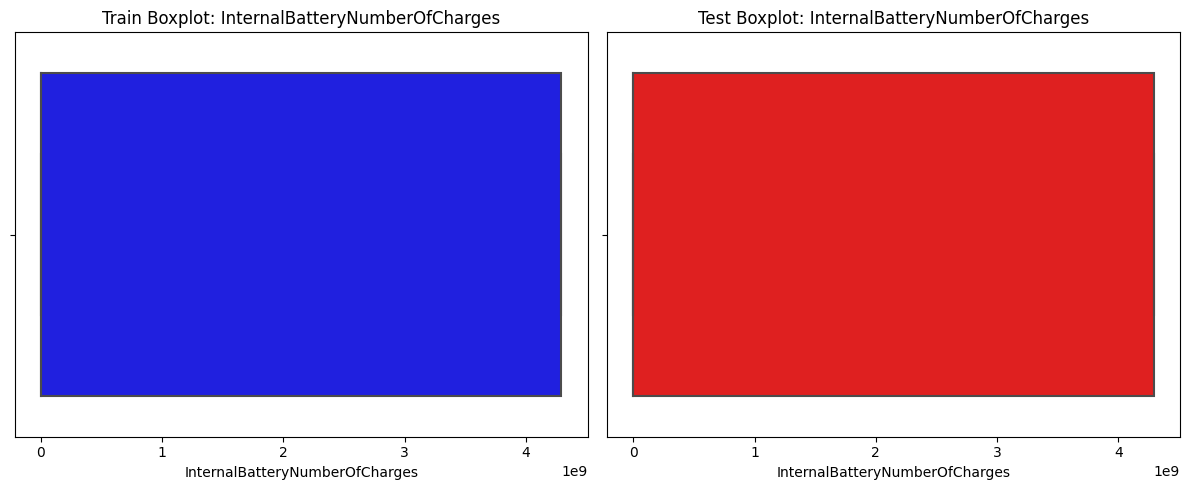

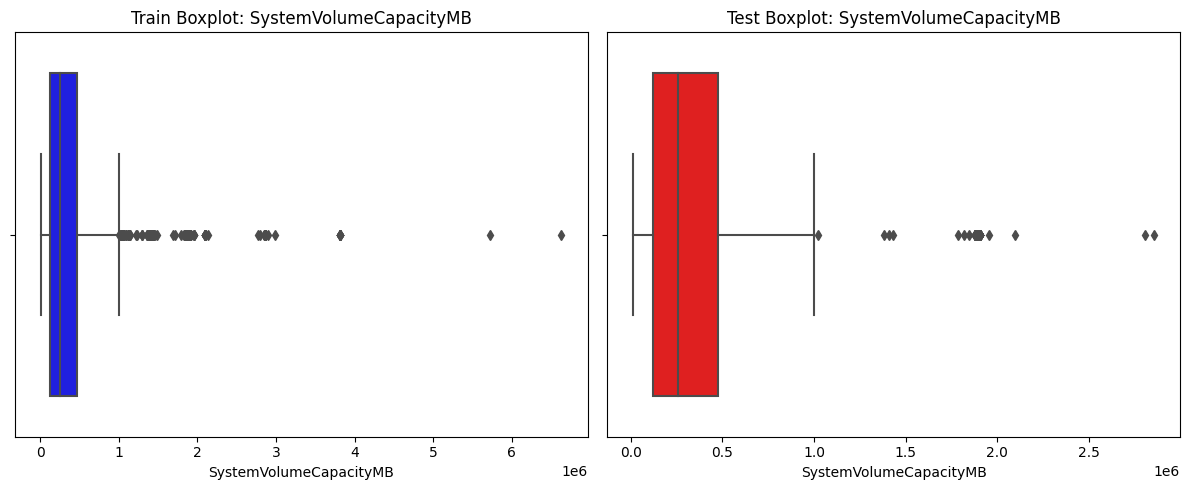

In [32]:
def plot_boxplots(train_df, test_df):
    numerical_cols = train_df.columns.tolist()

    for col in numerical_cols:
        
        fig, axes = plt.subplots(1, 2, figsize=(12, 5))
        sns.boxplot(x=train_df[col], ax=axes[0], color="blue")
        axes[0].set_title(f"Train Boxplot: {col}")
        sns.boxplot(x=test_df[col], ax=axes[1], color="red")
        axes[1].set_title(f"Test Boxplot: {col}")
        plt.tight_layout()
        plt.show()

plot_boxplots(train_df=data[nonbinary_num_features], test_df=test_data[nonbinary_num_features])



# The test data also has outliers
not a better plan to remove the outliers

### Significant categorical features but given as numerical

In [33]:
from scipy.stats import chi2_contingency
alpha=0.05
significant_numfeatures = []
for col in cat_num_feature:
    contingency_table = pd.crosstab(data[col], data['target'])
    chi2, p, dof, expected = chi2_contingency(contingency_table)      
    if p < alpha:
        significant_numfeatures.append({'column': col, 'chi2': round(chi2,4), 'p_value': round(p,4), 'significant': True})
    else:
        significant_numfeatures.append({'column': col, 'chi2': round(chi2,4),'p_value': round(p,4), 'significant': False})
Significant_num_features = pd.DataFrame(significant_numfeatures)

In [34]:
Significant_num_features

,column,chi2,p_value,significant
0,ProcessorManufacturerID,3.4248,0.4894,False
1,OSInstallLanguageID,219.9813,0.0000,True
2,OSUILocaleID,247.6804,0.0000,True
3,IEVersionID,464.8287,0.0000,True
4,FirmwareManufacturerID,569.9206,0.0000,True
5,LocaleEnglishNameID,512.0761,0.0000,True
6,CountryID,757.7483,0.0000,True
7,GeoRegionID,604.3967,0.0000,True
8,OEMNameID,1587.9187,0.0000,True
9,ProcessorModelID,3236.7359,0.0000,True


### Lets transform them as objects

In [35]:
for c in cat_num_feature:
    data[c]=data[c].astype('object')

## Lets refine the significant features based on out EDA

In [36]:
final_cat_features=data.select_dtypes(include=["object"])
opt_cat_features =final_cat_features.columns.tolist().copy()
x=['ProductName', 'OSVersion', 'FlightRing',"MachineID","OSBuildNumberOnly"] 
for i in opt_cat_features:
    if i in x:
        opt_cat_features.remove(i)
opt_cat_features

['EngineVersion',
 'AppVersion',
 'SignatureVersion',
 'RealTimeProtectionState',
 'AntivirusConfigID',
 'CountryID',
 'CityID',
 'GeoRegionID',
 'LocaleEnglishNameID',
 'PlatformType',
 'Processor',
 'OSBuildNumber',
 'OSProductSuite',
 'OsPlatformSubRelease',
 'OSBuildLab',
 'SKUEditionName',
 'IEVersionID',
 'MDC2FormFactor',
 'DeviceFamily',
 'OEMNameID',
 'OEMModelID',
 'ProcessorManufacturerID',
 'ProcessorModelID',
 'PrimaryDiskType',
 'ChassisType',
 'PowerPlatformRole',
 'NumericOSVersion',
 'OSArchitecture',
 'OSBranch',
 'OSEdition',
 'OSSkuFriendlyName',
 'OSInstallType',
 'OSInstallLanguageID',
 'OSUILocaleID',
 'AutoUpdateOptionsName',
 'OSGenuineState',
 'LicenseActivationChannel',
 'FirmwareManufacturerID',
 'FirmwareVersionID',
 'RegionIdentifier',
 'DateAS',
 'DateOS']

In [37]:
print(data.columns.tolist())

['ProductName', 'EngineVersion', 'AppVersion', 'SignatureVersion', 'IsBetaUser', 'RealTimeProtectionState', 'IsPassiveModeEnabled', 'AntivirusConfigID', 'NumAntivirusProductsInstalled', 'NumAntivirusProductsEnabled', 'HasTpm', 'CountryID', 'CityID', 'GeoRegionID', 'LocaleEnglishNameID', 'PlatformType', 'Processor', 'OSVersion', 'OSBuildNumber', 'OSProductSuite', 'OsPlatformSubRelease', 'OSBuildLab', 'SKUEditionName', 'IsSystemProtected', 'AutoSampleSubmissionEnabled', 'SMode', 'IEVersionID', 'FirewallEnabled', 'EnableLUA', 'MDC2FormFactor', 'DeviceFamily', 'OEMNameID', 'OEMModelID', 'ProcessorCoreCount', 'ProcessorManufacturerID', 'ProcessorModelID', 'PrimaryDiskCapacityMB', 'PrimaryDiskType', 'SystemVolumeCapacityMB', 'HasOpticalDiskDrive', 'TotalPhysicalRAMMB', 'ChassisType', 'PrimaryDisplayDiagonalInches', 'PrimaryDisplayResolutionHorizontal', 'PrimaryDisplayResolutionVertical', 'PowerPlatformRole', 'InternalBatteryNumberOfCharges', 'NumericOSVersion', 'OSArchitecture', 'OSBranch', 

In [38]:
import numpy as np

data["PPI"] = np.sqrt((data["PrimaryDisplayResolutionHorizontal"]**2 + data["PrimaryDisplayResolutionVertical"]**2) / data["PrimaryDisplayDiagonalInches"])


data["TotalPhysicalRAMMB"] /= 1024

data["PrimaryDiskCapacityMB"] /= 1024

data["SystemVolumeCapacityMB"] /= 1024

data.rename(columns={
    "TotalPhysicalRAMMB": "TotalPhysicalRAMGB", 
    "PrimaryDiskCapacityMB": "PrimaryDiskCapacityGB", 
    "SystemVolumeCapacityMB": "SystemVolumeCapacityGB"
}, inplace=True)


data.loc[data["InternalBatteryNumberOfCharges"] > 100000, "InternalBatteryNumberOfCharges"] = np.nan


/usr/local/lib/python3.10/dist-packages/pandas/core/computation/expressions.py:73: RuntimeWarning: invalid value encountered in greater
  return op(a, b)


In [39]:
final_num_features=data.select_dtypes(exclude=["object"])
opt_num_features =final_num_features.columns.tolist().copy()
x=['PrimaryDisplayDiagonalInches','PrimaryDisplayResolutionHorizontal','PrimaryDisplayResolutionVertical','IsBetaUser', 'AutoSampleSubmissionEnabled', 'IsFlightsDisabled','target']
for i in opt_num_features:
    if i in x:
        opt_num_features.remove(i)
opt_num_features

opt_bin_num_features=[]
opt_nonbin_num_features=[]
extra=[]
for i in opt_num_features:
    if i in binary_num_features:
        opt_bin_num_features.append(i)
    else:
        
        opt_nonbin_num_features.append(i)
    

print(len(opt_num_features))
print(len(opt_bin_num_features))
print(len(opt_nonbin_num_features))

24
14
10


## categorizing categorical features

In [40]:
import pandas as pd

cat_count = []  

for c in opt_cat_features:  
    cat_count.append({"col": c, "count": final_cat_features[c].nunique(dropna=False)})  
  
cat_count_df = pd.DataFrame(cat_count)  

one_hot=(cat_count_df[cat_count_df['count']<=20])['col'].values.tolist()
print(one_hot)

target_enc= (cat_count_df[cat_count_df['count']>20])['col'].values.tolist()
print(target_enc)

['RealTimeProtectionState', 'PlatformType', 'Processor', 'OSProductSuite', 'OsPlatformSubRelease', 'SKUEditionName', 'MDC2FormFactor', 'DeviceFamily', 'ProcessorManufacturerID', 'PrimaryDiskType', 'PowerPlatformRole', 'OSArchitecture', 'OSBranch', 'OSEdition', 'OSSkuFriendlyName', 'OSInstallType', 'AutoUpdateOptionsName', 'OSGenuineState', 'LicenseActivationChannel', 'RegionIdentifier']
['EngineVersion', 'AppVersion', 'SignatureVersion', 'AntivirusConfigID', 'CountryID', 'CityID', 'GeoRegionID', 'LocaleEnglishNameID', 'OSBuildNumber', 'OSBuildLab', 'IEVersionID', 'OEMNameID', 'OEMModelID', 'ProcessorModelID', 'ChassisType', 'NumericOSVersion', 'OSInstallLanguageID', 'OSUILocaleID', 'FirmwareManufacturerID', 'FirmwareVersionID', 'DateAS', 'DateOS']


# *Data Preprocessing*

In [41]:
X=data.drop(columns=["target"])
y=data["target"]

In [42]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    test_size = 0.3,
                                                    stratify = y,
                                                    random_state = 42)

In [43]:
from sklearn.preprocessing import RobustScaler, OneHotEncoder,MinMaxScaler, StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer,KNNImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.compose import make_column_selector as mcs
from category_encoders import TargetEncoder


## Pipelines 

## Categorical Piplines

In [44]:
cat_simple_onehot =  Pipeline([("imputer", SimpleImputer(missing_values = np.nan, strategy="most_frequent")),
                       ("one_hot_encoder", OneHotEncoder(handle_unknown='ignore',sparse_output=False))])

cat_simple_target =  Pipeline([("imputer", SimpleImputer(missing_values = np.nan, strategy="most_frequent")),
                       ("Target_encoder", TargetEncoder())])

## Numerical Pipelines

In [45]:
num_simple_mean_robust = Pipeline([("imputer", SimpleImputer(missing_values = np.nan, strategy="most_frequent")),
                       ("r_scaler", RobustScaler())])

num_median_minmax = Pipeline([("imputer", SimpleImputer(missing_values = np.nan, strategy="median")),
                       ("r_scaler", MinMaxScaler())])

num_freq_simple = Pipeline([("imputer",SimpleImputer(strategy="most_frequent"))])


num_median_standard = Pipeline([("imputer", SimpleImputer(missing_values = np.nan, strategy="median")),
                       ("r_scaler", StandardScaler())])

id_num_onehot =       Pipeline([("imputer",SimpleImputer(strategy="most_frequent")),
                                ("encoder",OneHotEncoder(sparse_output=False,handle_unknown='ignore'))])

id_num_target =       Pipeline([("imputer",SimpleImputer(strategy="most_frequent")),
                                ("encoder",TargetEncoder())])


In [46]:
ct = ColumnTransformer([("Small_Cat",cat_simple_onehot,one_hot),
                        ("Large_Cat",cat_simple_target,target_enc),
                        ("binary_imp",num_freq_simple,opt_bin_num_features),
                        ("nonbinary_imp",num_median_standard, opt_nonbin_num_features)],
                        remainder='drop', verbose_feature_names_out=False)


ct.fit(X_train, y_train)

X_train_trf = ct.transform(X_train)
X_test_trf = ct.transform(X_test)

In [47]:
from sklearn.metrics import accuracy_score, classification_report, roc_curve, roc_auc_score, auc,confusion_matrix,make_scorer
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, RandomizedSearchCV

# Models

In [48]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Logistic Regression

In [49]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

lr = LogisticRegression(random_state=42)

lr.fit(X_train_trf, y_train)

lr_y_hat_train = lr.predict(X_train_trf)
lr_y_hat_val = lr.predict(X_test_trf)

lr_train_score = accuracy_score(y_train, lr_y_hat_train)
lr_val_score = accuracy_score(y_test, lr_y_hat_val)

print(f"Training Score: {lr_train_score}, Validation Score: {lr_val_score}")
print("\nClassification Report:\n", classification_report(y_test, lr_y_hat_val))



Training Score: 0.7405142857142857, Validation Score: 0.572

Classification Report:
               precision    recall  f1-score   support

           0       0.57      0.55      0.56     14843
           1       0.57      0.59      0.58     15157

    accuracy                           0.57     30000
   macro avg       0.57      0.57      0.57     30000
weighted avg       0.57      0.57      0.57     30000



/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_logistic.py:458: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


# Hypertuning for Logistic Regression

In [50]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from scipy.stats import uniform

param_grid_lr = {
    "C": uniform(0.01, 10),
    "solver": ["liblinear", "lbfgs"],
    "max_iter": [500, 1000]
}


lr = LogisticRegression(random_state=42)

random_search_lr = RandomizedSearchCV(
    estimator=lr,
    param_distributions=param_grid_lr,
    n_iter=10,
    scoring="accuracy",
    cv=3,
    verbose=1,
    n_jobs=-1,
    random_state=42
)


random_search_lr.fit(X_train_trf, y_train)

best_lr = random_search_lr.best_estimator_
print(f"Best Params for Logistic Regression: {random_search_lr.best_params_}")

y_pred_lr = best_lr.predict(X_test_trf)
print(f"Logistic Regression Accuracy: {accuracy_score(y_test, y_pred_lr)}")

param_grid_lr = {
    "C": [0.5, 0.59, 0.6, 0.7],  
    "solver": ["liblinear"], 
    "max_iter": [1000] 
}

lr = LogisticRegression(random_state=42)

grid_search_lr = GridSearchCV(
    estimator=lr,
    param_grid=param_grid_lr,
    scoring="accuracy",
    cv=5,  # More stable results
    verbose=1,
    n_jobs=-1
)

grid_search_lr.fit(X_train_trf, y_train)

best_lr = grid_search_lr.best_estimator_
print(f"Best Params for Logistic Regression: {grid_search_lr.best_params_}")

y_pred_lr = best_lr.predict(X_test_trf)
print(f"Logistic Regression Accuracy: {accuracy_score(y_test, y_pred_lr)}")


Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best Params for Logistic Regression: {'C': 0.5908361216819946, 'max_iter': 1000, 'solver': 'liblinear'}
Logistic Regression Accuracy: 0.5725333333333333
Fitting 5 folds for each of 4 candidates, totalling 20 fits
Best Params for Logistic Regression: {'C': 0.5, 'max_iter': 1000, 'solver': 'liblinear'}
Logistic Regression Accuracy: 0.5724


# DecisionTreeClassifier

In [51]:
from sklearn.tree import DecisionTreeClassifier
dt_model=DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train_trf,y_train)
dt_y_hat_train=dt_model.predict(X_train_trf)
dt_y_hat_val=dt_model.predict(X_test_trf)
dt_train_score = accuracy_score(dt_y_hat_train, y_train)
dt_val_score = accuracy_score(dt_y_hat_val, y_test)
print(f'Training score: {dt_train_score}, Validation score: {dt_val_score}')

Training score: 1.0, Validation score: 0.5407333333333333


# HyperParameter Tuning for DecisionTreeClassifier

In [52]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import RandomizedSearchCV
import numpy as np

param_dist_dt = {
    "criterion": ["gini", "entropy", "log_loss"],
    "max_depth": np.arange(3, 50, 5),
    "min_samples_split": np.arange(2, 20, 2),
    "min_samples_leaf": np.arange(1, 20, 2),
}

dt = DecisionTreeClassifier(random_state=42)

random_search_dt = RandomizedSearchCV(
    estimator=dt,
    param_distributions=param_dist_dt,
    n_iter=30, 
    scoring="accuracy",
    cv=5,  
    verbose=1,
    n_jobs=-1,
    random_state=42
)

random_search_dt.fit(X_train_trf, y_train)

best_dt = random_search_dt.best_estimator_
print(f"Best Params for Decision Tree (Randomized Search): {random_search_dt.best_params_}")


y_pred_dt = best_dt.predict(X_test_trf)
print(f"Decision Tree Accuracy: {accuracy_score(y_test, y_pred_dt)}")
from sklearn.model_selection import GridSearchCV


param_grid_dt = {
    "criterion": [random_search_dt.best_params_["criterion"]],
    "max_depth": [random_search_dt.best_params_["max_depth"] - 5,
                  random_search_dt.best_params_["max_depth"],
                  random_search_dt.best_params_["max_depth"] + 5],
    "min_samples_split": [max(2, random_search_dt.best_params_["min_samples_split"] - 1),
                          random_search_dt.best_params_["min_samples_split"],
                          random_search_dt.best_params_["min_samples_split"] + 1],  # Ensuring it's ≥ 2
    "min_samples_leaf": [max(1, random_search_dt.best_params_["min_samples_leaf"] - 1),
                         random_search_dt.best_params_["min_samples_leaf"],
                         random_search_dt.best_params_["min_samples_leaf"] + 1]

}


grid_search_dt = GridSearchCV(
    estimator=dt,
    param_grid=param_grid_dt,
    scoring="accuracy",
    cv=5,  
    verbose=1,
    n_jobs=-1
)


grid_search_dt.fit(X_train_trf, y_train)


best_dt_grid = grid_search_dt.best_estimator_
print(f"Best Params for Decision Tree (Grid Search): {grid_search_dt.best_params_}")

y_pred_dt_grid = best_dt_grid.predict(X_test_trf)
print(f"Decision Tree Accuracy (Grid Search): {accuracy_score(y_test, y_pred_dt_grid)}")


Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best Params for Decision Tree (Randomized Search): {'min_samples_split': 2, 'min_samples_leaf': 15, 'max_depth': 8, 'criterion': 'entropy'}
Decision Tree Accuracy: 0.5578333333333333
Fitting 5 folds for each of 27 candidates, totalling 135 fits
Best Params for Decision Tree (Grid Search): {'criterion': 'entropy', 'max_depth': 8, 'min_samples_leaf': 14, 'min_samples_split': 2}
Decision Tree Accuracy (Grid Search): 0.5578333333333333


# RandomForest Classifier

In [53]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train_trf, y_train)

rf_y_hat_train = rf.predict(X_train_trf)
rf_y_hat_val = rf.predict(X_test_trf)

rf_train_score = accuracy_score(y_train, rf_y_hat_train)
rf_val_score = accuracy_score(y_test, rf_y_hat_val)
print(f"Training Score: {rf_train_score}, Validation Score: {rf_val_score}")

Training Score: 1.0, Validation Score: 0.5803333333333334


# HyperTuning for RandomForestClassifier

In [54]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
import numpy as np

param_dist_rf = {
    'n_estimators': np.arange(100, 500, 100),
    'max_depth': np.arange(10, 50, 10),
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

rf = RandomForestClassifier(random_state=42, n_jobs=-1)

random_search_rf = RandomizedSearchCV(
    rf, param_distributions=param_dist_rf, 
    n_iter=10,  
    cv=3, 
    verbose=2, 
    n_jobs=-1
)

random_search_rf.fit(X_train_trf, y_train)
best_rf = random_search_rf.best_estimator_
print(f"Best Params for Random Forest: {random_search_rf.best_params_}")

y_pred_rf = best_rf.predict(X_test_trf)
print(f"Random Forest Accuracy: {accuracy_score(y_test, y_pred_rf)}")


Fitting 3 folds for each of 10 candidates, totalling 30 fits


/usr/local/lib/python3.10/dist-packages/joblib/externals/loky/process_executor.py:752: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Best Params for Random Forest: {'n_estimators': 400, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_depth': 20}
Random Forest Accuracy: 0.5814


In [55]:
best_rf = random_search_rf.best_estimator_
print(f"Best Params for Random Forest: {random_search_rf.best_params_}")

y_pred_rf = best_rf.predict(X_test_trf)
print(f"Random Forest Accuracy: {accuracy_score(y_test, y_pred_rf)}")


Best Params for Random Forest: {'n_estimators': 400, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_depth': 20}
Random Forest Accuracy: 0.5814


## Best model

In [56]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

rf1 = RandomForestClassifier(
    n_estimators=400, 
    min_samples_split=10, 
    min_samples_leaf=1, 
    max_depth=20, 
    random_state=42, 
    n_jobs=-1
)
rf1.fit(X_train_trf, y_train)

rf1_y_hat_train = rf1.predict(X_train_trf)
rf1_y_hat_val = rf1.predict(X_test_trf)

rf1_train_score = accuracy_score(y_train, rf1_y_hat_train)
rf1_val_score = accuracy_score(y_test, rf1_y_hat_val)
print(f"Training Score: {rf1_train_score}, Validation Score: {rf1_val_score}")

Training Score: 0.9155142857142857, Validation Score: 0.5814333333333334


# XGBoost

In [57]:
xgb = XGBClassifier(use_label_encoder=False, eval_metric="logloss", random_state=42, n_jobs=-1)
xgb.fit(X_train_trf, y_train)
xgb_pred = xgb.predict(X_test_trf)
print("XGBoost Accuracy:", accuracy_score(y_test, xgb_pred))

XGBoost Accuracy: 0.575


# HyperParameter tuning for XGBoost

In [58]:
from xgboost import XGBClassifier


param_dist_xgb = {
    'n_estimators': np.arange(100, 500, 100),  
    'max_depth': np.arange(3, 10, 2),
    'learning_rate': np.linspace(0.01, 0.3, 10), 
    'subsample': np.linspace(0.5, 1.0, 5), 
    'colsample_bytree': np.linspace(0.5, 1.0, 5),
    'gamma': np.linspace(0, 0.5, 5), 
    'reg_lambda': np.logspace(-1, 2, 5) }
xgb = XGBClassifier(use_label_encoder=False, eval_metric='logloss')

random_search_xgb = RandomizedSearchCV(
    xgb,
    param_distributions=param_dist_xgb,
    n_iter=20, 
    scoring='accuracy',
    cv=3,
    verbose=2,
    n_jobs=-1,
    random_state=42
)

random_search_xgb.fit(X_train_trf, y_train)

print("Best parameters:", random_search_xgb.best_params_)
print("Best score:", random_search_xgb.best_score_)

Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best parameters: {'subsample': 0.5, 'reg_lambda': 0.1, 'n_estimators': 200, 'max_depth': 5, 'learning_rate': 0.07444444444444444, 'gamma': 0.125, 'colsample_bytree': 0.875}
Best score: 0.7800428525633483


In [59]:
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

xgb_best = XGBClassifier(
    subsample=0.5, 
    reg_lambda=0.1, 
    n_estimators=200, 
    max_depth=5, 
    learning_rate=0.07444444444444444, 
    gamma=0.125, 
    colsample_bytree=0.875, 
    random_state=42, 
    n_jobs=-1
)

xgb_best.fit(X_train_trf, y_train)

xgb_train_preds = xgb_best.predict(X_train_trf)
xgb_val_preds = xgb_best.predict(X_test_trf)


xgb_train_acc = accuracy_score(y_train, xgb_train_preds)
xgb_val_acc = accuracy_score(y_test, xgb_val_preds)
print(f"Training Accuracy: {xgb_train_acc:.4f}, Validation Accuracy: {xgb_val_acc:.4f}")


Training Accuracy: 0.8001, Validation Accuracy: 0.5771


# LGBMClassifier

In [60]:
lgbm = LGBMClassifier(random_state=42, n_jobs=-1)
lgbm.fit(X_train_trf, y_train)
lgbm_pred = lgbm.predict(X_test_trf)
print("LightGBM Accuracy:", accuracy_score(y_test, lgbm_pred))

[LightGBM] [Info] Number of positive: 35368, number of negative: 34632
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.021314 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 4645
[LightGBM] [Info] Number of data points in the train set: 70000, number of used features: 173
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.505257 -> initscore=0.021029
[LightGBM] [Info] Start training from score 0.021029
LightGBM Accuracy: 0.5764666666666667


In [61]:
from lightgbm import LGBMClassifier
from sklearn.model_selection import RandomizedSearchCV
import numpy as np

param_dist = {
    'n_estimators': np.arange(100, 500, 100),
    'learning_rate': np.linspace(0.01, 0.3, 10),
    'max_depth': np.arange(3, 10, 2),
    'num_leaves': np.arange(20, 150, 20),
    'min_child_samples': np.arange(10, 100, 10),
    'subsample': np.linspace(0.5, 1, 5),
    'colsample_bytree': np.linspace(0.5, 1, 5),
    'reg_alpha': np.logspace(-3, 1, 5),
    'reg_lambda': np.logspace(-3, 1, 5),
}

# Initialize model
lgbm = LGBMClassifier(random_state=42)

# Perform RandomizedSearchCV
random_search = RandomizedSearchCV(
    estimator=lgbm,
    param_distributions=param_dist,
    n_iter=20, 
    cv=3,
    scoring='accuracy',
    n_jobs=-1,
    verbose=2,
    random_state=42
)

random_search.fit(X_train_trf, y_train)

print("Best parameters found: ", random_search.best_params_)
print("Best accuracy: ", random_search.best_score_)


Fitting 3 folds for each of 20 candidates, totalling 60 fits


/usr/local/lib/python3.10/dist-packages/joblib/externals/loky/process_executor.py:752: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


[LightGBM] [Info] Number of positive: 35368, number of negative: 34632
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.020093 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 4659
[LightGBM] [Info] Number of data points in the train set: 70000, number of used features: 180
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.505257 -> initscore=0.021029
[LightGBM] [Info] Start training from score 0.021029
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain

In [62]:
base_estimators = [
    ('rf', RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)),
    ('xgb', XGBClassifier(use_label_encoder=False, eval_metric="logloss", random_state=42, n_jobs=-1)),
    ('lgbm', LGBMClassifier(random_state=42, n_jobs=-1))
]
meta_model = LogisticRegression(max_iter=1000, random_state=42)
stacking_clf = StackingClassifier(estimators=base_estimators, final_estimator=meta_model, n_jobs=-1)
stacking_clf.fit(X_train_trf, y_train)
stack_pred = stacking_clf.predict(X_test_trf)
print("Stacking Classifier Accuracy:", accuracy_score(y_test, stack_pred))

Stacking Classifier Accuracy: 0.5765333333333333


In [63]:
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV


base_models = [
    ('xgb', XGBClassifier(subsample=0.5, reg_lambda=0.1, n_estimators=200, max_depth=5, 
                          learning_rate=0.0744, gamma=0.125, colsample_bytree=0.875, random_state=42)),
    
    ('lgbm', LGBMClassifier(subsample=0.625, reg_lambda=1.0, reg_alpha=0.001, num_leaves=60, 
                            n_estimators=400, min_child_samples=10, max_depth=3, 
                            learning_rate=0.1389, colsample_bytree=0.625, random_state=42)),
    
    ('rf', RandomForestClassifier(n_estimators=400, min_samples_split=10, 
                                  min_samples_leaf=1, max_depth=20, random_state=42, n_jobs=-1))
]


In [64]:
stack_clf = StackingClassifier(estimators=base_models, final_estimator=LogisticRegression(), n_jobs=-1)

param_grid = {
    'final_estimator__C': [0.01, 0.1, 1, 10],
    'final_estimator__solver': ['lbfgs', 'liblinear']
}

grid_search = GridSearchCV(estimator=stack_clf, param_grid=param_grid, cv=5, scoring='accuracy', n_jobs=-1, verbose=2)
grid_search.fit(X_train_trf, y_train)

print("Best parameters for meta-learner: ", grid_search.best_params_)
print("Best accuracy: ", grid_search.best_score_)


Fitting 5 folds for each of 8 candidates, totalling 40 fits


/usr/local/lib/python3.10/dist-packages/joblib/externals/loky/process_executor.py:752: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Best parameters for meta-learner:  {'final_estimator__C': 0.01, 'final_estimator__solver': 'lbfgs'}
Best accuracy:  0.7835428571428571


In [65]:


test["PPI"] = np.sqrt((test["PrimaryDisplayResolutionHorizontal"]**2 + test["PrimaryDisplayResolutionVertical"]**2) / test["PrimaryDisplayDiagonalInches"])


test["TotalPhysicalRAMMB"] /= 1024

test["PrimaryDiskCapacityMB"] /= 1024

test["SystemVolumeCapacityMB"] /= 1024

test.rename(columns={
    "TotalPhysicalRAMMB": "TotalPhysicalRAMGB", 
    "PrimaryDiskCapacityMB": "PrimaryDiskCapacityGB", 
    "SystemVolumeCapacityMB": "SystemVolumeCapacityGB"
}, inplace=True)



In [66]:
test_trf =ct.transform(test)
y_pred=rf1.predict(test_trf)
print("success")

success


In [67]:
submission=pd.DataFrame({"id":range(0,test.shape[0]),
                        "target":y_pred})
submission.to_csv("submission.csv",index=False)
print("success")

success


In [68]:
submission.head(100)

,id,target
0,0,1
1,1,1
2,2,0
3,3,1
4,4,0
...,...,...
95,95,1
96,96,1
97,97,0
98,98,0
